# 🚢 타이타닉 생존 요인 분석 — 로지스틱 회귀

> 타이타닉 승객 1,309명의 데이터로 생존 여부를 판별하는 로지스틱 회귀를
> **품질 점검 → EDA → 기준선 모형 → 가정 검정 → 체크포인트 비교 → 최종 보고**의 흐름으로 수행했습니다.
> 이름에서 뽑은 **호칭(Title)** 으로 '여성과 아이 먼저'를 성별보다 정확하게 포착했고,
> 가족 규모를 **단독 · 소가족 · 대가족**으로 나눈 도메인 파생변수로 대가족의 낮은 생존율을 모델에 담았습니다.

| 항목 | 내용 |
|---|---|
| **데이터** | [Titanic (Kaggle)](https://www.kaggle.com/c/titanic) · 1,309행 → 결측 처리 후 1,306행 |
| **종속변수** | `Survived` — 생존(1) 492명 / 사망(0) 814명 (38 : 62, 약한 불균형) |
| **분석 질문** | ① 누가 살아남았는가? ② '여성과 아이 먼저'는 데이터에서 어떻게 드러나는가? ③ 가족과 함께 탄 것은 생존에 유리했는가? |
| **주요 기법** | 파생변수(호칭 · 가족 규모) · Mann-Whitney U · 카이제곱 검정 · Box-Tidwell · 후진소거 · AUC · 임계값 조정 |

### 📑 목차
0. **준비** — 라이브러리, 데이터 로드, 컬럼 의미
1. **PART 1. 데이터 품질 점검** — 결측 처리 · 파생변수(가족 수 · 호칭) · 불필요 컬럼 제거
2. **PART 2. EDA** — 단변량 → 이변량(T검정 · 교차분석) → 다변량(공선성) → 최종 변수 선택
3. **PART 3. 기준선 모형과 가정 검정** — 기준선 모형 → 로짓 선형성 · 독립성
4. **PART 4. 로지스틱 회귀 모델링** — 가족 규모 도메인 파생변수 → 체크포인트 비교 → 최종 모델 선택
5. **PART 5. 최종 모델 보고** — 계수 해석 · 분류 성능 · 임계값 조정
6. **📌 종합 인사이트**

> ⚙️ **사용 모듈** : `my_qtcheck` · `my_plot` · `my_stats` · `my_prep` · `my_logit` (helpers) · 데이터 로더 `jussam`

---
# 0. 준비

### (1) 라이브러리 참조

In [1]:
from jussam import load_data
from helpers import *

import numpy as np
from pandas import DataFrame, crosstab, cut, set_option
from IPython.display import display, Markdown

📦 연세대학교 주영아 교수가 제작한 라이브러리를 사용중입니다.
📧 Email(1): j.purplerose@yonsei.ac.kr
📧 Email(2): j.purplerose@gmail.com
📝 Website: https://juyounga.kr/
🔖 Version: develop


### (2) 데이터 가져오기

In [2]:
origin = load_data("titanic")
print(f"데이터 크기 : {origin.shape}")
origin.head()

📚 타이타닉호 침몰은 역사상 가장 악명 높은 난파 사고 중 하나입니다. 1912년 4월 15일, 첫 항해 중이던 타이타닉호는 빙산과 충돌하여 침몰했습니다. 당시 배에는 모든 승객과 승무원을 태울 수 있는 구명보트가 충분하지 않아 2,224명의 승객과 승무원 중 1,502명이 목숨을 잃었습니다. 생존에는 어느 정도 운이 작용했지만, 일부 집단은 다른 집단보다 생존 가능성이 더 높았던 것으로 보입니다. 이번 과제에서는 승객 데이터(예: 이름, 나이, 성별, 사회경제적 계층 등)를 사용하여 `어떤 유형의 사람들이 생존할 가능성이 더 높았을까?`라는 질문에 답하는 예측 모델을 구축해야 합니다. (출처: https://www.kaggle.com/datasets/yasserh/titanic-dataset)

변수명       설명
-----------  -------------------------------------------------------
PassengerId  탑승객의 ID(인덱스와 같은 개념)
Survived     생존유무(0은 사망 1은 생존)
Pclass       객실의 등급(1=1등급, 2=2등급, 3=3등급)
Name         이름
Sex          성별
SibSp        동승한 형제 혹은 배우자의 수
Parch        동승한 자녀 혹은 부모의 수
Ticket       티켓번호
Fare         요금
Cabin        선실
Embarked     탑승지 (C = Cherbourg, Q = Queenstown, S = Southampton)

데이터 크기 : (1309, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.000,1,0,A/5 21171,7.250,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Thayer)",female,38.000,1,0,PC 17599,71.283,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.000,0,0,STON/O2. 3101282,7.925,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.000,1,0,113803,53.100,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.000,0,0,373450,8.050,NaN,S


### (3) 컬럼 의미를 정리한 딕셔너리

In [3]:
column_means = {
    "PassengerId": "탑승객 식별자",
    "Survived":    "생존 여부 (0=사망, 1=생존)",
    "Pclass":      "객실 등급 (1=1등급, 2=2등급, 3=3등급)",
    "Name":        "이름",
    "Sex":         "성별 (male, female)",
    "Age":         "나이",
    "SibSp":       "동승한 형제·배우자 수",
    "Parch":       "동승한 부모·자녀 수",
    "Ticket":      "티켓 번호",
    "Fare":        "요금",
    "Cabin":       "선실 번호",
    "Embarked":    "탑승 항구 (C=Cherbourg, Q=Queenstown, S=Southampton)",
}

---
# PART 1. 데이터 품질 점검

### (1) 자료형 변환

- `Survived` · `Pclass` · `Sex` · `Embarked`는 명목형(category)으로 지정한다. `Pclass`는 1 · 2 · 3이라는 숫자로 저장돼 있지만 **'3등급은 1등급의 3배'가 아니므로** 연속형으로 두면 안 된다.

In [4]:
df1 = my_qtcheck.set_type(origin, as_category=["Survived", "Pclass", "Sex", "Embarked"])

<class 'pandas.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   PassengerId  1309 non-null   int32   
 1   Survived     1309 non-null   category
 2   Pclass       1309 non-null   category
 3   Name         1309 non-null   str     
 4   Sex          1309 non-null   category
 5   Age          1046 non-null   float32 
 6   SibSp        1309 non-null   int32   
 7   Parch        1309 non-null   int32   
 8   Ticket       1309 non-null   object  
 9   Fare         1308 non-null   float32 
 10  Cabin        295 non-null    str     
 11  Embarked     1307 non-null   category
dtypes: category(4), float32(2), int32(3), object(1), str(2)
memory usage: 97.5+ KB


### (2) 중복 점검

In [5]:
df2 = my_qtcheck.check_duplicates(data=df1)

중복된 행의 수: 0


### (3) 결측치 점검

In [6]:
my_qtcheck.check_missing_values(df2)

,Missing Count,Missing Ratio (%)
PassengerId,0,0.000
Survived,0,0.000
Pclass,0,0.000
Name,0,0.000
Sex,0,0.000
Age,263,20.092
SibSp,0,0.000
Parch,0,0.000
Ticket,0,0.000
Fare,1,0.076


### (4) 결측치 처리

| 컬럼 | 결측 | 처리 | 이유 |
|---|---|---|---|
| `Cabin` | 1,014건 (77.5%) | **컬럼 삭제** | 4명 중 3명이 비어 있어 채울 근거가 없다 |
| `Embarked` | 2건 (0.15%) | **행 삭제** | 합쳐서 3행(0.23%)뿐이라 지워도 영향이 거의 없고, 추정값을 만들지 않아도 된다 |
| `Fare` | 1건 (0.08%) | **행 삭제** | (위와 같음) |
| `Age` | 263건 (20.1%) | **중앙값으로 대체** | 아래 참고 |

- **`Age`는 지우지 않고 채운다.**
  - '여성과 아이 먼저' 관행이 있었던 만큼, 나이는 생존을 설명하는 핵심 변수라 컬럼째 지울 수 없다.
  - 결측 행을 지우면 263명(20.1%)을 잃는다.
- **평균이 아니라 중앙값으로 채운다.**
  - 평균은 극단값 몇 개에도 크게 움직이지만, 중앙값은 값을 크기순으로 세운 가운데 값이라 극단값에 덜 흔들린다.
  - 아직 분포 모양을 확인하기 전이므로, 어떤 분포에서도 무난한 **중앙값**을 택한다.
- ⚠️ 263명을 하나의 값(중앙값)으로 채우는 것은 **가볍게 볼 일이 아니다.**
  - 263명이 같은 값을 갖게 되어, 나이 분포에 **인공적인 봉우리**가 생길 수 있다.
  - 실제 나이의 차이가 지워져, 나이의 효과가 **실제보다 약하게** 추정될 수 있다.
  - → 채운 뒤의 분포는 단변량 분석에서 확인한다.

In [7]:
# Cabin 컬럼 삭제
df4 = df2.drop(columns=["Cabin"]) 

# Embarked · Fare 결측 행 삭제
df4 = my_prep.replace_missing(df=df4, columns=["Embarked", "Fare"], method="drop")

# Age  중앙값으로 대체
age_raw = df4["Age"].copy()            # Age 값을 따로 보관(호칭별 나이 확인용)
df4 = my_prep.replace_missing(df=df4, columns=["Age"], method="median")

# 결측치 다시 확인
my_qtcheck.check_missing_values(data=df4)

결측치 처리 방식: 'drop' (대상 컬럼 2개)
행 수: 1309개 -> 1306개 (3개 삭제)
결측치 처리 방식: 'median'
컬럼                     결측치                 대체값
--------------------------------------------
Age          263개(20.1%)              28.0


,Missing Count,Missing Ratio (%)
PassengerId,0,0.000
Survived,0,0.000
Pclass,0,0.000
Name,0,0.000
Sex,0,0.000
Age,0,0.000
SibSp,0,0.000
Parch,0,0.000
Ticket,0,0.000
Fare,0,0.000


### (5) 파생변수 ① — 동승 가족 수 (`FamilySize`)

- 형제 · 배우자(`SibSp`)와 부모 · 자녀(`Parch`)를 합치고 본인(1)을 더해 **함께 탄 가족 규모**를 만든다.

In [8]:
df4["FamilySize"] = df4["SibSp"] + df4["Parch"] + 1
column_means["FamilySize"] = "동승 가족 수 (SibSp + Parch + 본인)"

df4[["SibSp", "Parch", "FamilySize"]].head()

,SibSp,Parch,FamilySize
0,1,0,2
1,1,0,2
2,0,0,1
3,1,0,2
4,0,0,1


### (6) 파생변수 ② — 이름에서 호칭(`Title`) 추출

- 이름은 `Braund, Mr. Owen Harris`처럼 **`성, 호칭. 이름`** 형식이다. 쉼표와 마침표 사이를 뽑으면 호칭이 나온다.
- 원본 호칭은 **18종**인데, 그중 절반 이상이 1~2명뿐이다. 그대로 쓰면 추정이 불가능한 범주가 생기므로, 의미가 같은 것끼리 **5종**으로 묶는다(도메인 지식).

In [9]:
# 이름에서 호칭 추출 : "성, 호칭. 이름" 형식이므로 쉼표와 마침표 사이를 뽑는다
title_raw = df4["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()

display(Markdown(f"**원본 호칭 ({title_raw.nunique()}종)**"))
title_raw.value_counts().rename("빈도").to_frame().T

**원본 호칭 (18종)**

Name,Mr,Miss,Mrs,Master,Rev,Dr,Col,Ms,Major,Mlle,Don,Mme,Lady,Sir,Capt,the Countess,Jonkheer,Dona
빈도,756,259,196,61,8,8,4,2,2,2,1,1,1,1,1,1,1,1


In [10]:
# 의미별 호칭 정의
title_map = {
    # 성인 남성 — Don(스페인) · Sir(영국) · Jonkheer(네덜란드)는 남성 귀족 경칭
    "Mr": "Mr", "Don": "Mr", "Sir": "Mr", "Jonkheer": "Mr",
    # 미혼 여성 — Mlle(프랑스)=Miss, Ms=혼인 여부를 밝히지 않는 호칭
    "Miss": "Miss", "Mlle": "Miss", "Ms": "Miss",
    # 기혼 여성 — Mme(프랑스) · Dona(스페인)=Mrs, Lady · the Countess는 여성 귀족 경칭
    "Mrs": "Mrs", "Mme": "Mrs", "Dona": "Mrs", "Lady": "Mrs", "the Countess": "Mrs",
    # 남자아이
    "Master": "Master",
    # 전문직 · 군인 · 성직자 — 이름에 직위가 드러난 사람들
    "Dr": "Officer", "Rev": "Officer", "Col": "Officer", "Major": "Officer", "Capt": "Officer",
}

df4["Title"] = title_raw.map(title_map)
column_means["Title"] = "이름에서 추출한 호칭 (Mr/Mrs/Miss/Master/Officer)"

print("원본 호칭 :", title_raw.nunique(), "종 → 통합 후 :", df4["Title"].nunique(), "종")
print("매핑 누락 :", df4["Title"].isna().sum(), "건")
df4["Title"].value_counts().rename("빈도").to_frame().T

원본 호칭 : 18 종 → 통합 후 : 5 종
매핑 누락 : 0 건


Title,Mr,Miss,Mrs,Master,Officer
빈도,759,263,200,61,23


### (7) 호칭별 나이 — 결측 대체 전 기준

- 나이는 결측을 채우기 **전** 값(`age_raw`)으로 본다. 대체 후 값으로 보면 중앙값이 섞여 호칭별 차이가 흐려진다.

In [11]:
age_table = DataFrame({"Age": age_raw, "Title": df4["Title"]}).groupby("Title")["Age"]

result = DataFrame({
    "결측":   age_table.apply(lambda s: s.isna().sum()),   # 나이가 비어 있는 사람 수
    "기록":   age_table.count(),                           # 나이가 기록된 사람 수
    "중앙값": age_table.median(),                          # 기록된 나이의 중앙값
})

result.T

Title,Master,Miss,Mr,Mrs,Officer
결측,8.000,51.000,176.000,27.000,1.000
기록,53.000,212.000,583.000,173.000,22.000
중앙값,4.000,22.000,29.000,35.000,49.500


---
##### 💡 인사이트 — 호칭이 나이대를 가른다

| 호칭 | Master | Miss | Mr | Mrs | Officer |
|---|---|---|---|---|---|
| 나이 중앙값 | **4세** | 22세 | 29세 | 35세 | 49.5세 |
| 나이 결측 | 8명 | 51명 | 176명 | 27명 | 1명 |

- 호칭마다 나이대가 뚜렷하게 다르다. 특히 **`Master`는 남자아이**(중앙값 4세)라, 성별(`male`)로는 구분되지 않던 **'아이'를 따로 잡아낸다.**
- 그런데 결측은 전체 중앙값 **28세**로 채웠기 때문에, 나이를 모르는 남자아이(Master) 8명도 28세가 됐다. 호칭별 중앙값으로 채웠다면 더 현실적인 값을 넣을 수 있었다. → 한계로 기록한다.

---

### (8) 불필요한 컬럼 제거 (도메인 지식)

| 컬럼 | 제거 이유 |
|---|---|
| `PassengerId` | 행마다 값이 모두 다른 **식별자**다. 숫자라서 그대로 두면 연속형 변수로 잘못 투입된다 |
| `Name` | 자유 텍스트다. **호칭(`Title`)을 뽑은 뒤** 제거한다 |
| `Ticket` | 형식이 제각각인 **문자열 식별자**다 (`A/5 21171`, `113803` …) |

In [12]:
df5 = df4.drop(columns=["PassengerId", "Name", "Ticket"])
df5 = my_qtcheck.set_type(df5, as_category=["Title"])
print("남은 컬럼 :", df5.columns.tolist())

<class 'pandas.DataFrame'>
RangeIndex: 1306 entries, 0 to 1305
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   Survived    1306 non-null   category
 1   Pclass      1306 non-null   category
 2   Sex         1306 non-null   category
 3   Age         1306 non-null   float32 
 4   SibSp       1306 non-null   int32   
 5   Parch       1306 non-null   int32   
 6   Fare        1306 non-null   float32 
 7   Embarked    1306 non-null   category
 8   FamilySize  1306 non-null   int32   
 9   Title       1306 non-null   category
dtypes: category(5), float32(2), int32(3)
memory usage: 32.1 KB
남은 컬럼 : ['Survived', 'Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked', 'FamilySize', 'Title']


### (9) 명목형 변수 기술통계량

In [13]:
cat_desc = my_qtcheck.categorical_summary(df5)
cat_desc

컬럼 'Survived'의 value_counts( ):


,count
Survived,
0,814
1,492


컬럼 'Pclass'의 value_counts( ):


,count
Pclass,
1,321
2,277
3,708


컬럼 'Sex'의 value_counts( ):


,count
Sex,
female,464
male,842


컬럼 'Embarked'의 value_counts( ):


,count
Embarked,
C,270
Q,123
S,913


컬럼 'Title'의 value_counts( ):


,count
Title,
Master,61
Miss,263
Mr,759
Mrs,200
Officer,23


,Survived,Pclass,Sex,Embarked,Title
count,1306,1306,1306,1306,1306
unique,2,3,2,3,5
top,0,3,male,S,Mr
freq,814,708,842,913,759


### (10) 연속형 변수 기술통계량

In [14]:
num_desc = my_qtcheck.numerical_summary(df5)
num_desc.T

,Age,SibSp,Parch,Fare,FamilySize
count,1306.000,1306.000,1306.000,1306.000,1306.000
mean,29.448,0.500,0.386,33.224,1.886
std,12.858,1.043,0.866,51.766,1.585
min,0.170,0.000,0.000,0.000,1.000
25%,22.000,0.000,0.000,7.896,1.000
50%,28.000,0.000,0.000,14.454,1.000
75%,35.000,1.000,0.000,31.275,2.000
max,80.000,8.000,9.000,512.329,11.000
rel_diff,0.052,inf,inf,1.299,0.886
rdiff_flag,similar,large_diff,large_diff,large_diff,large_diff


---
##### 💡 인사이트 — 품질 점검

| 점검 항목 | 결과 |
|---|---|
| 중복 | 0건 |
| 결측 처리 | `Cabin` 컬럼 삭제, `Embarked` · `Fare` 3행 삭제, `Age` 263건 중앙값(28세) 대체 |
| 파생변수 | `FamilySize`(동승 가족 수), `Title`(호칭 18종 → 5종) |
| 최종 | **1,306행 × 10개 변수** |

- 결측이 가장 많은 `Cabin`(77.5%)은 버리고, 생존과 직결되는 `Age`(20.1%)는 채워서 남겼다.
- 이름 · 가족 수처럼 그대로는 쓰기 어려운 정보를 **파생변수**로 바꿔, 버릴 뻔한 정보를 살렸다.

---

# PART 2. 탐색적 데이터 분석(EDA)

### (1) 변수 유형 분류

In [15]:
target = "Survived"
nominal_cols = my_qtcheck.get_categorical_column_names(df5)
continuous_cols = my_qtcheck.get_number_column_names(df5)
nominal_cols.remove(target)

print("종속변수 :", target)
print("명목형   :", nominal_cols)
print("연속형   :", continuous_cols)

종속변수 : Survived
명목형   : ['Pclass', 'Sex', 'Embarked', 'Title']
연속형   : ['Age', 'SibSp', 'Parch', 'Fare', 'FamilySize']


### (2) 범주 순서 지정

- `Pclass`는 **서열**(3등급 < 2등급 < 1등급)이 있어 순서를 지정한다.
- `Title`은 서열은 없지만, 더미변수의 **기준 범주를 `Mr`(성인 남성)** 로 정하기 위해 순서를 재배치한다.

In [16]:
df = df5.copy()
df["Pclass"] = df["Pclass"].cat.reorder_categories([3, 2, 1], ordered=True)
df["Title"] = df["Title"].cat.reorder_categories(["Mr", "Officer", "Master", "Miss", "Mrs"])

print("Pclass :", list(df["Pclass"].cat.categories))
print("Title  :", list(df["Title"].cat.categories))

Pclass : [3, 2, 1]
Title  : ['Mr', 'Officer', 'Master', 'Miss', 'Mrs']


### (3) EDA 범위 정리

- 종속변수 `Survived`가 **명목형(2집단)** 이므로, 독립변수의 유형에 따라 **T검정**과 **교차분석**을 적용한다.

| 종속유형 | 독립유형 | 분석 유형 | 대상 변수 | 적용 | 비고 |
|---|---|---|---|---|---|
| 연속형 | 연속형 | 상관분석 | — | ❌ 미적용 | 종속변수가 명목형 |
| 연속형 | 명목형(2집단) | T검정 | — | ❌ 미적용 | 종속변수가 명목형 |
| 연속형 | 명목형(3집단+) | ANOVA | — | ❌ 미적용 | 종속변수가 명목형 |
| **명목형(2집단)** | **연속형** | **T검정** | `Age` · `SibSp` · `Parch` · `Fare` · `FamilySize` → `Survived` | ✅ **적용** | |
| **명목형(2집단)** | **명목형(2집단)** | **교차분석** | `Sex` → `Survived` | ✅ **적용** | |
| **명목형(2집단)** | **명목형(3집단+)** | **교차분석** | `Pclass` · `Embarked` · `Title` → `Survived` | ✅ **적용** | |
| 명목형(3집단+) | 연속형 | ANOVA | — | ❌ 미적용 | 종속변수가 2집단 |
| 명목형(3집단+) | 명목형(2집단) | 교차분석 | — | ❌ 미적용 | 종속변수가 2집단 |
| 명목형(3집단+) | 명목형(3집단+) | 교차분석 | — | ❌ 미적용 | 종속변수가 2집단 |

- **다변량 분석(독립변수끼리)** : 연속형끼리는 상관분석 · VIF(`FamilySize` · `SibSp` · `Parch` 등), 명목형끼리는 교차분석(`Title` ↔ `Sex`)으로 중복 여부를 확인한다.

## 2-1. 단변량 분석

### (1) 종속변수 — 범주 비율

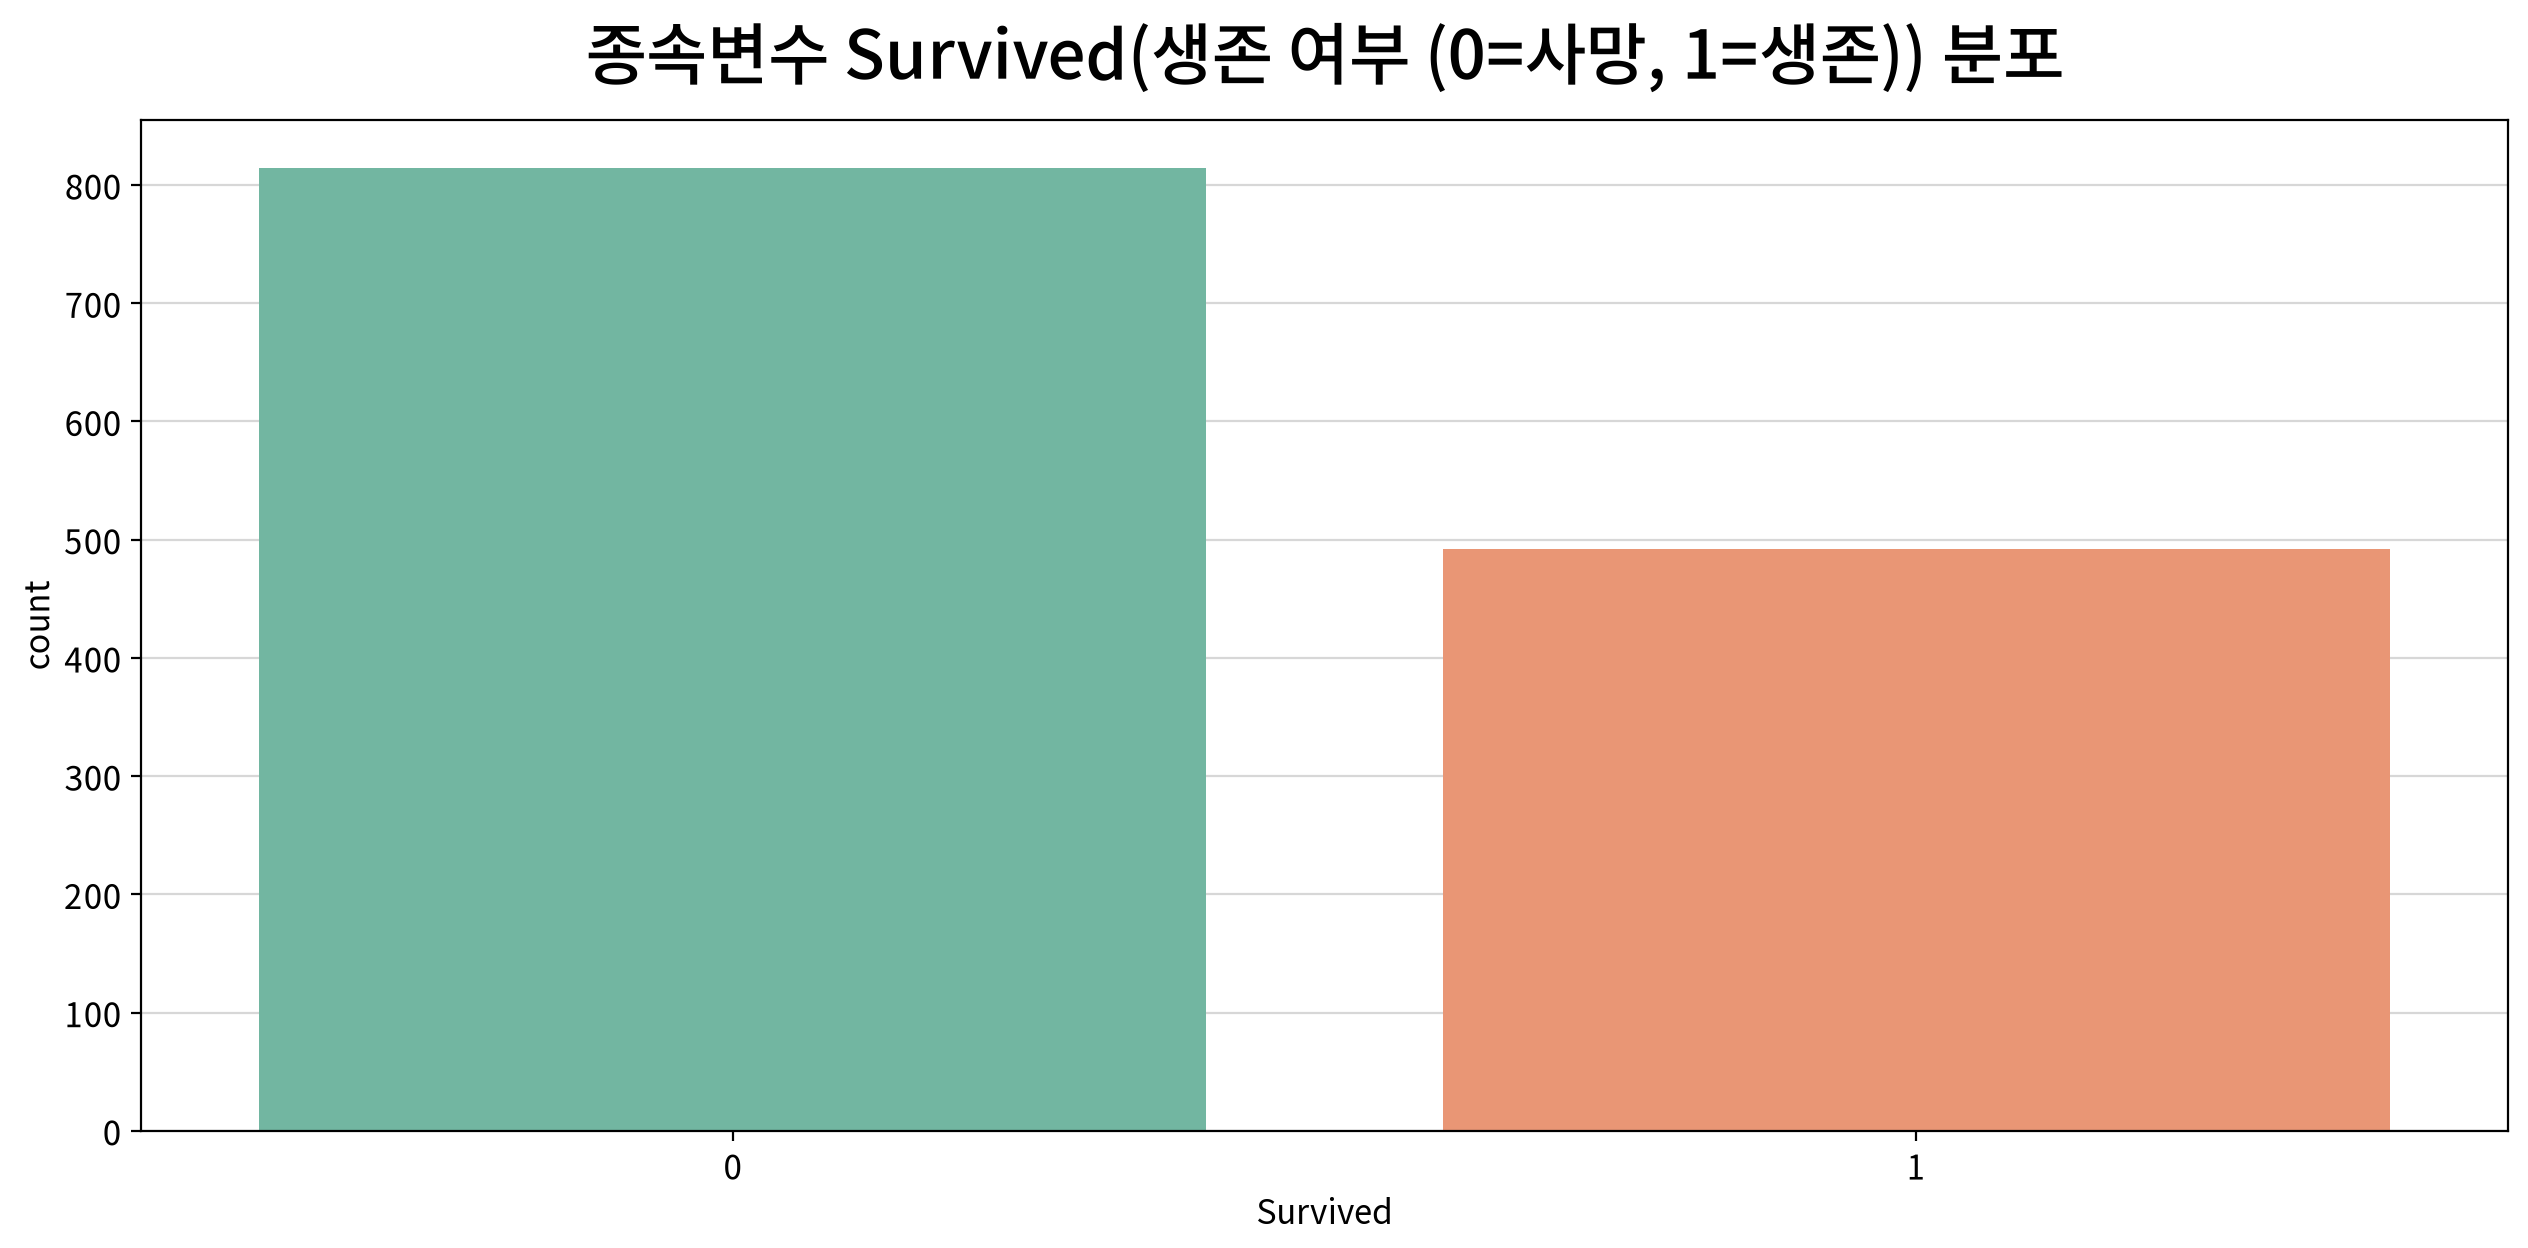

,빈도,비율
Survived,,
0,814,0.623
1,492,0.377


In [17]:
my_plot.countplot(data=df, x=target, hue=target, palette="Set2",
                  title=f"종속변수 {target}({column_means[target]}) 분포")

freq = df[target].value_counts().rename("빈도").to_frame()
freq["비율"] = df[target].value_counts(normalize=True)
freq

---
##### 💡 인사이트

| 점검 항목 | `Survived` 관찰값 |
|---|---|
| 범주 수 | 2 (0=사망 / 1=생존) → **이분형**이므로 로지스틱 회귀 적용 가능 |
| 비율 | 사망 814명(62.3%) · 생존 492명(37.7%) |
| 균형 여부 | **약한 불균형** (62 : 38) |

- **정확도의 바닥값은 62.3%** 다. 모두 '사망'이라고만 답하는 게으른 모델도 62.3%를 맞힌다.
- 심각한 불균형은 아니라 별도의 리샘플링 없이 진행하지만, **정확도 하나만 보지 말고 재현율 · 정밀도 · AUC를 함께** 확인해야 한다.

---

### (2) 명목형 독립변수

#### ▶︎ Pclass(객실 등급 (1=1등급, 2=2등급, 3=3등급)) 분포

Pclass,3,1,2
빈도,708.000,321.000,277.000
비율,0.542,0.246,0.212


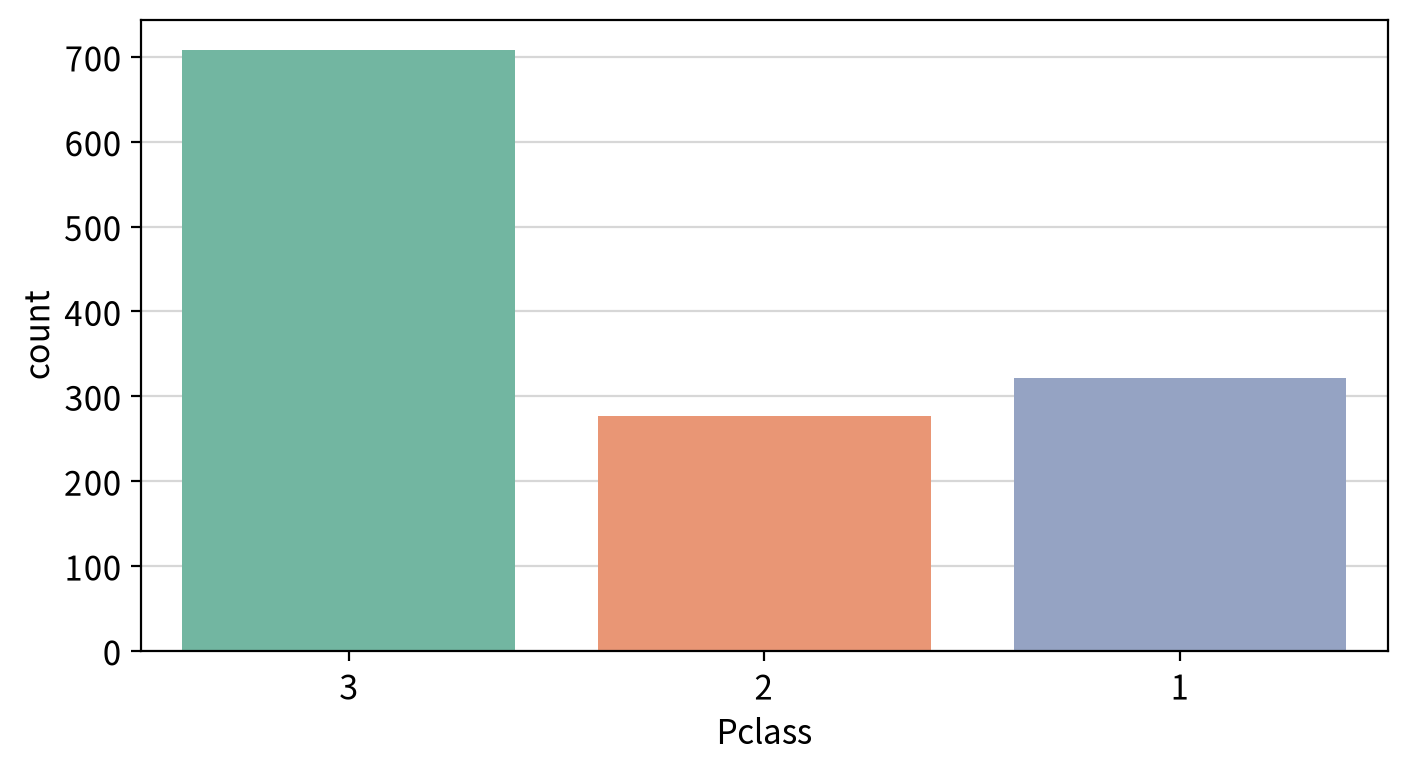

#### ▶︎ Sex(성별 (male, female)) 분포

Sex,male,female
빈도,842.000,464.000
비율,0.645,0.355


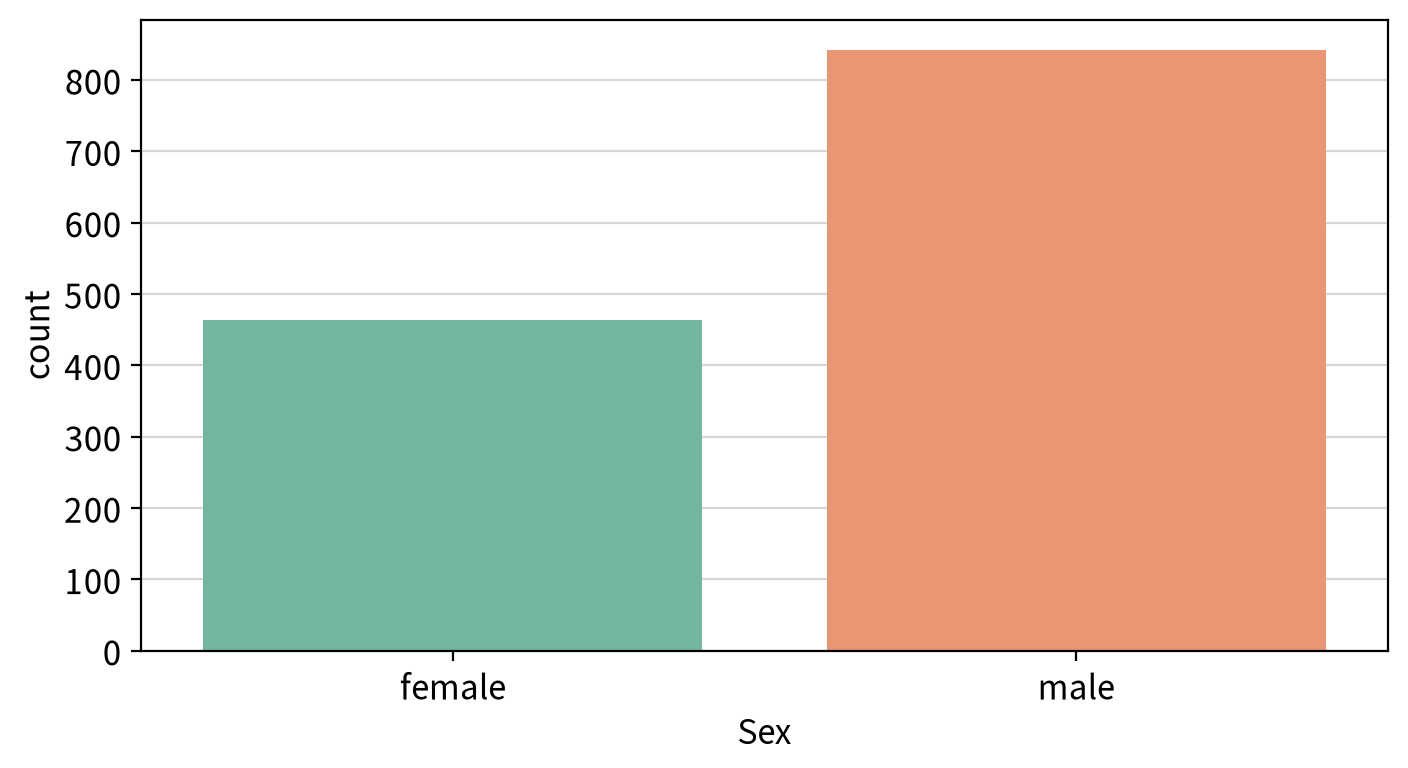

#### ▶︎ Embarked(탑승 항구 (C=Cherbourg, Q=Queenstown, S=Southampton)) 분포

Embarked,S,C,Q
빈도,913.000,270.000,123.000
비율,0.699,0.207,0.094


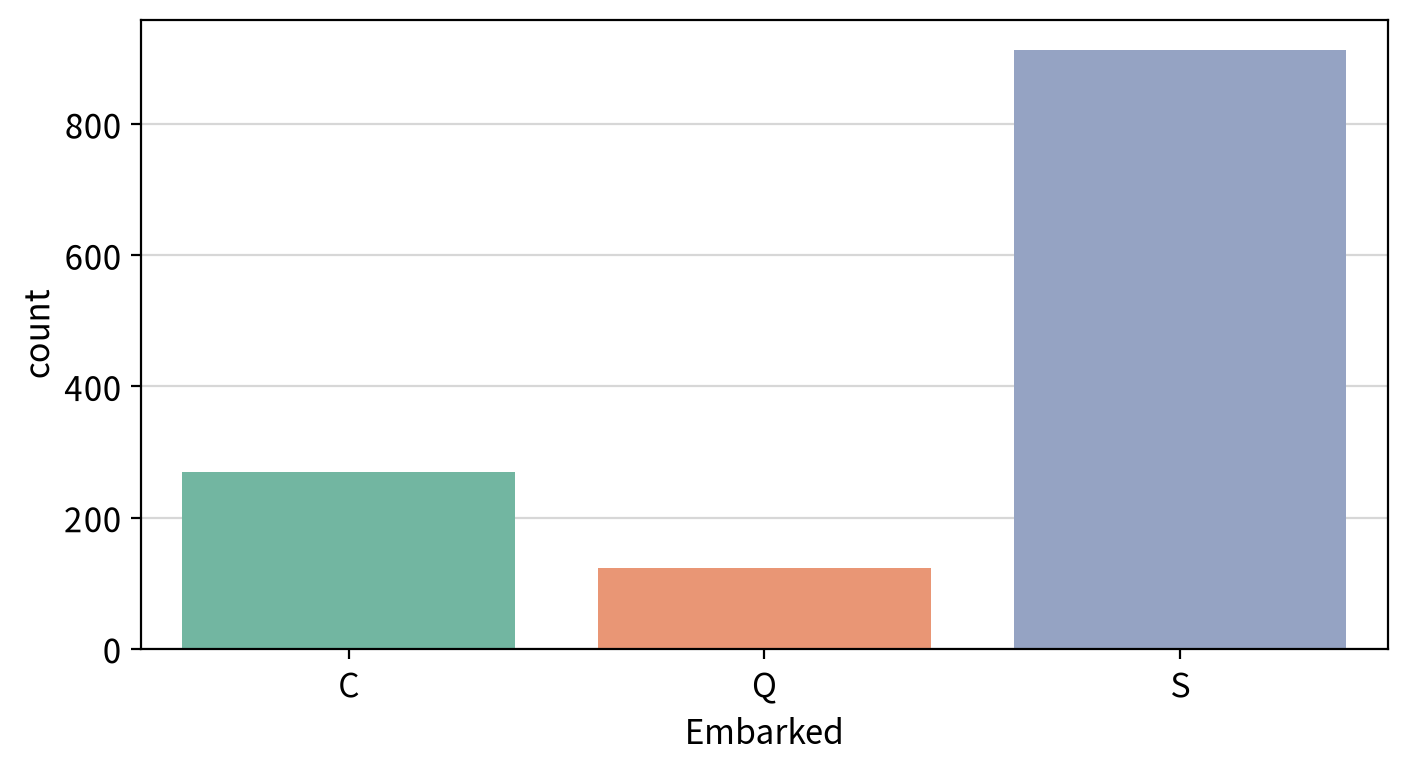

#### ▶︎ Title(이름에서 추출한 호칭 (Mr/Mrs/Miss/Master/Officer)) 분포

Title,Mr,Miss,Mrs,Master,Officer
빈도,759.000,263.000,200.000,61.000,23.000
비율,0.581,0.201,0.153,0.047,0.018


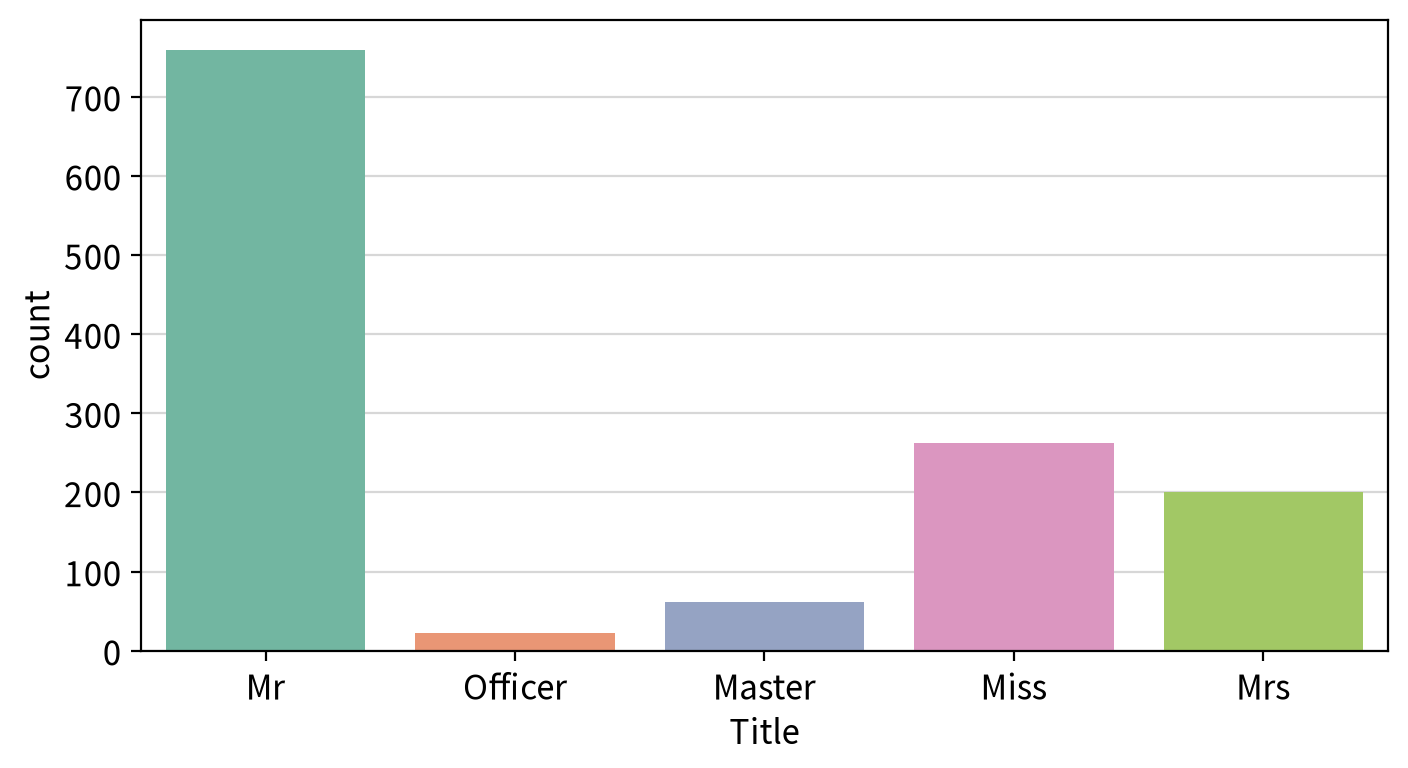

In [18]:
for n in nominal_cols:
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) 분포"))
    freq = df[n].value_counts().rename("빈도").to_frame()
    freq["비율"] = df[n].value_counts(normalize=True)
    display(freq.T)
    my_plot.countplot(data=df, x=n, hue=n, palette="Set2", width=720, height=400)

---
##### 💡 인사이트

| 변수 | 범주 분포 | 판단 |
|---|---|---|
| `Pclass` | 3등급 708 (54.2%) · 1등급 321 (24.6%) · 2등급 277 (21.2%) | 3등급이 절반 이상이지만 나머지도 충분 |
| `Sex` | 남성 842 (64.5%) · 여성 464 (35.5%) | 남성이 많지만 여성도 464명으로 충분해 분석에 문제 없음 |
| `Embarked` | S 913 (69.9%) · C 270 (20.7%) · **Q 123 (9.4%)** | Q가 적지만 100건 이상이라 사용 가능 |
| `Title` | Mr 759 (58.1%) · Miss 263 (20.1%) · Mrs 200 (15.3%) · Master 61 (4.7%) · **Officer 23 (1.8%)** | **`Officer`는 23명(생존 약 5명)뿐이라 계수가 불안정할 수 있다** |

- **가장 작은 범주는 `Title = Officer`의 23명**이다. 생존자가 5명 정도뿐이라, 모델에서 이 범주의 효과는 신뢰구간이 넓고 불안정하게 추정될 수 있다.
- 원본 호칭 18종을 그대로 썼다면 1명짜리 범주가 여럿 생겨 추정 자체가 어려웠을 것이다. **5종으로 묶은 판단이 여기서 정당화된다.**

---

### (3) 연속형 독립변수

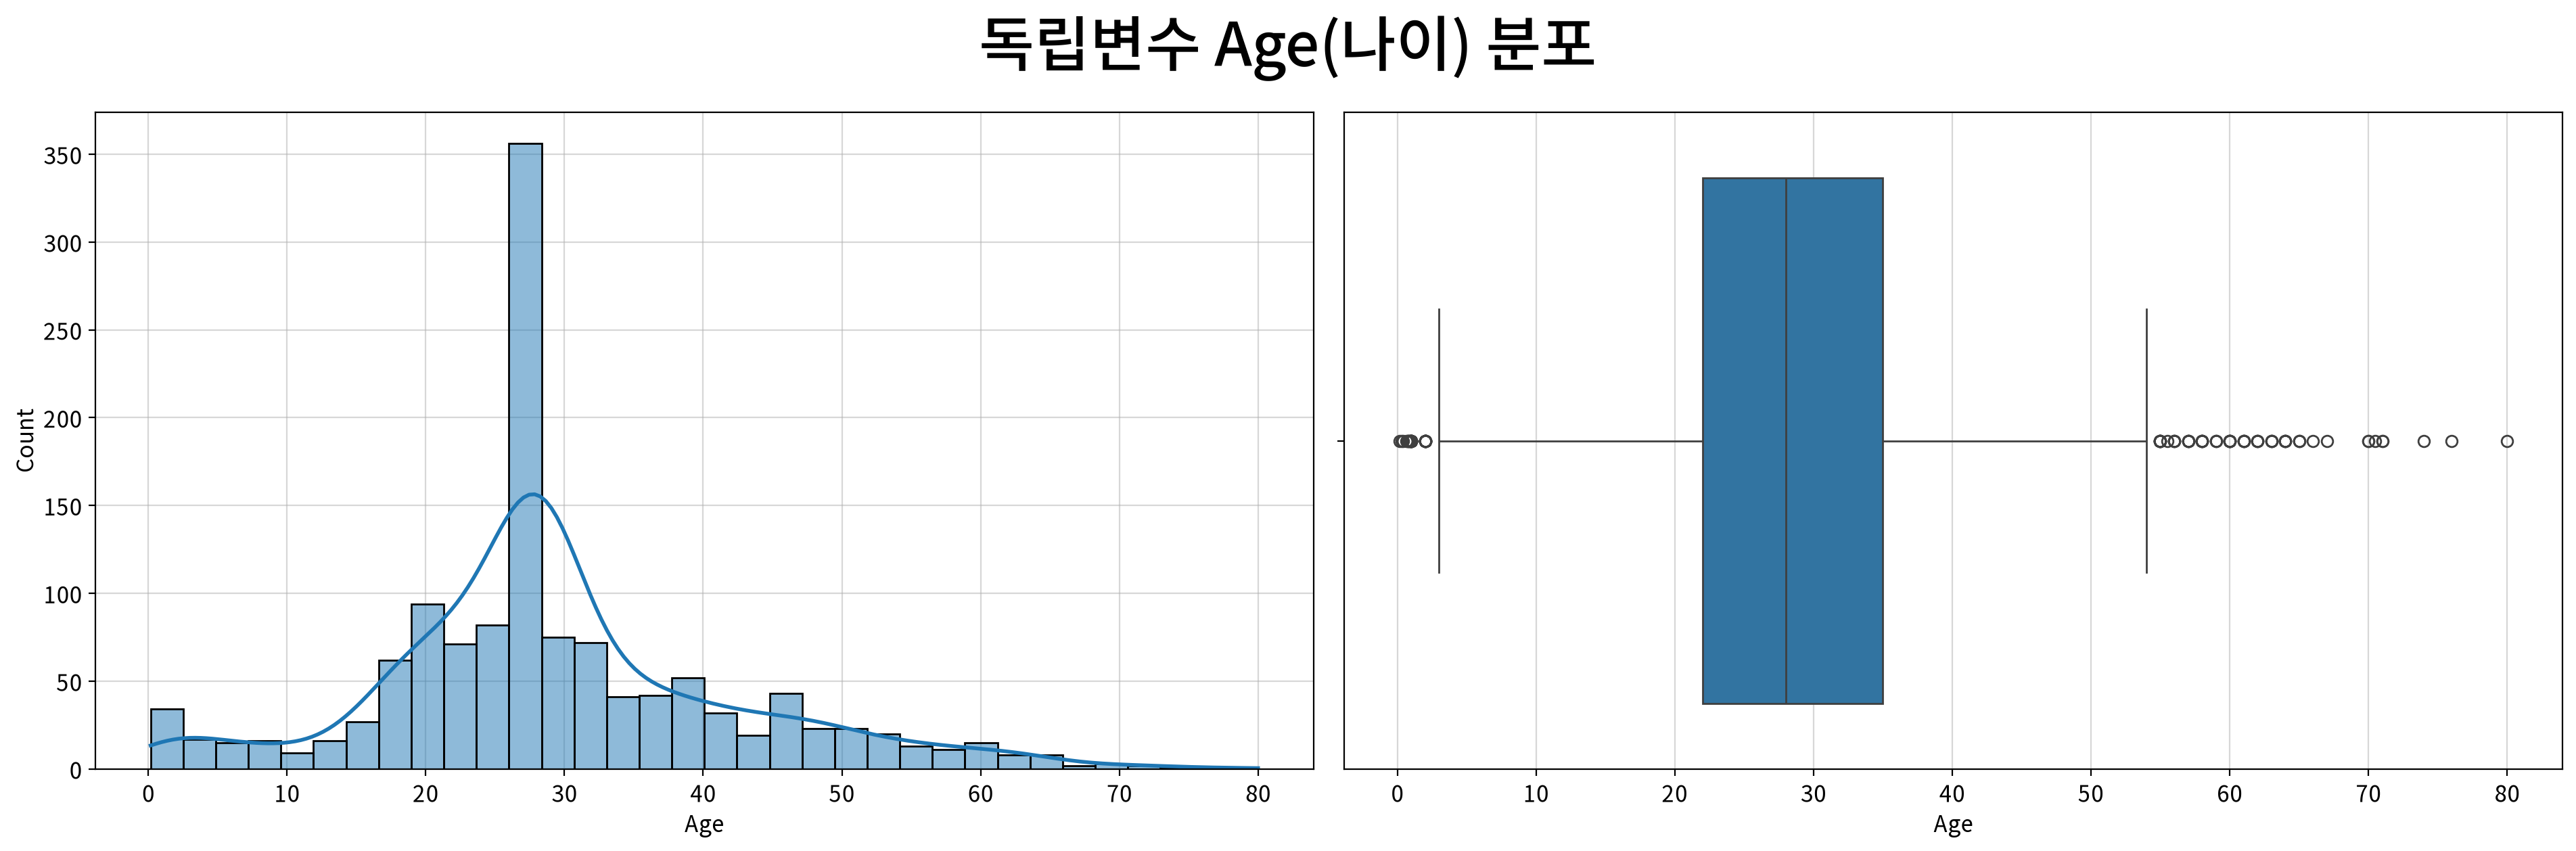

,Age
count,1306.000
mean,29.448
std,12.858
min,0.170
25%,22.000
50%,28.000
75%,35.000
max,80.000
rel_diff,0.052
rdiff_flag,similar


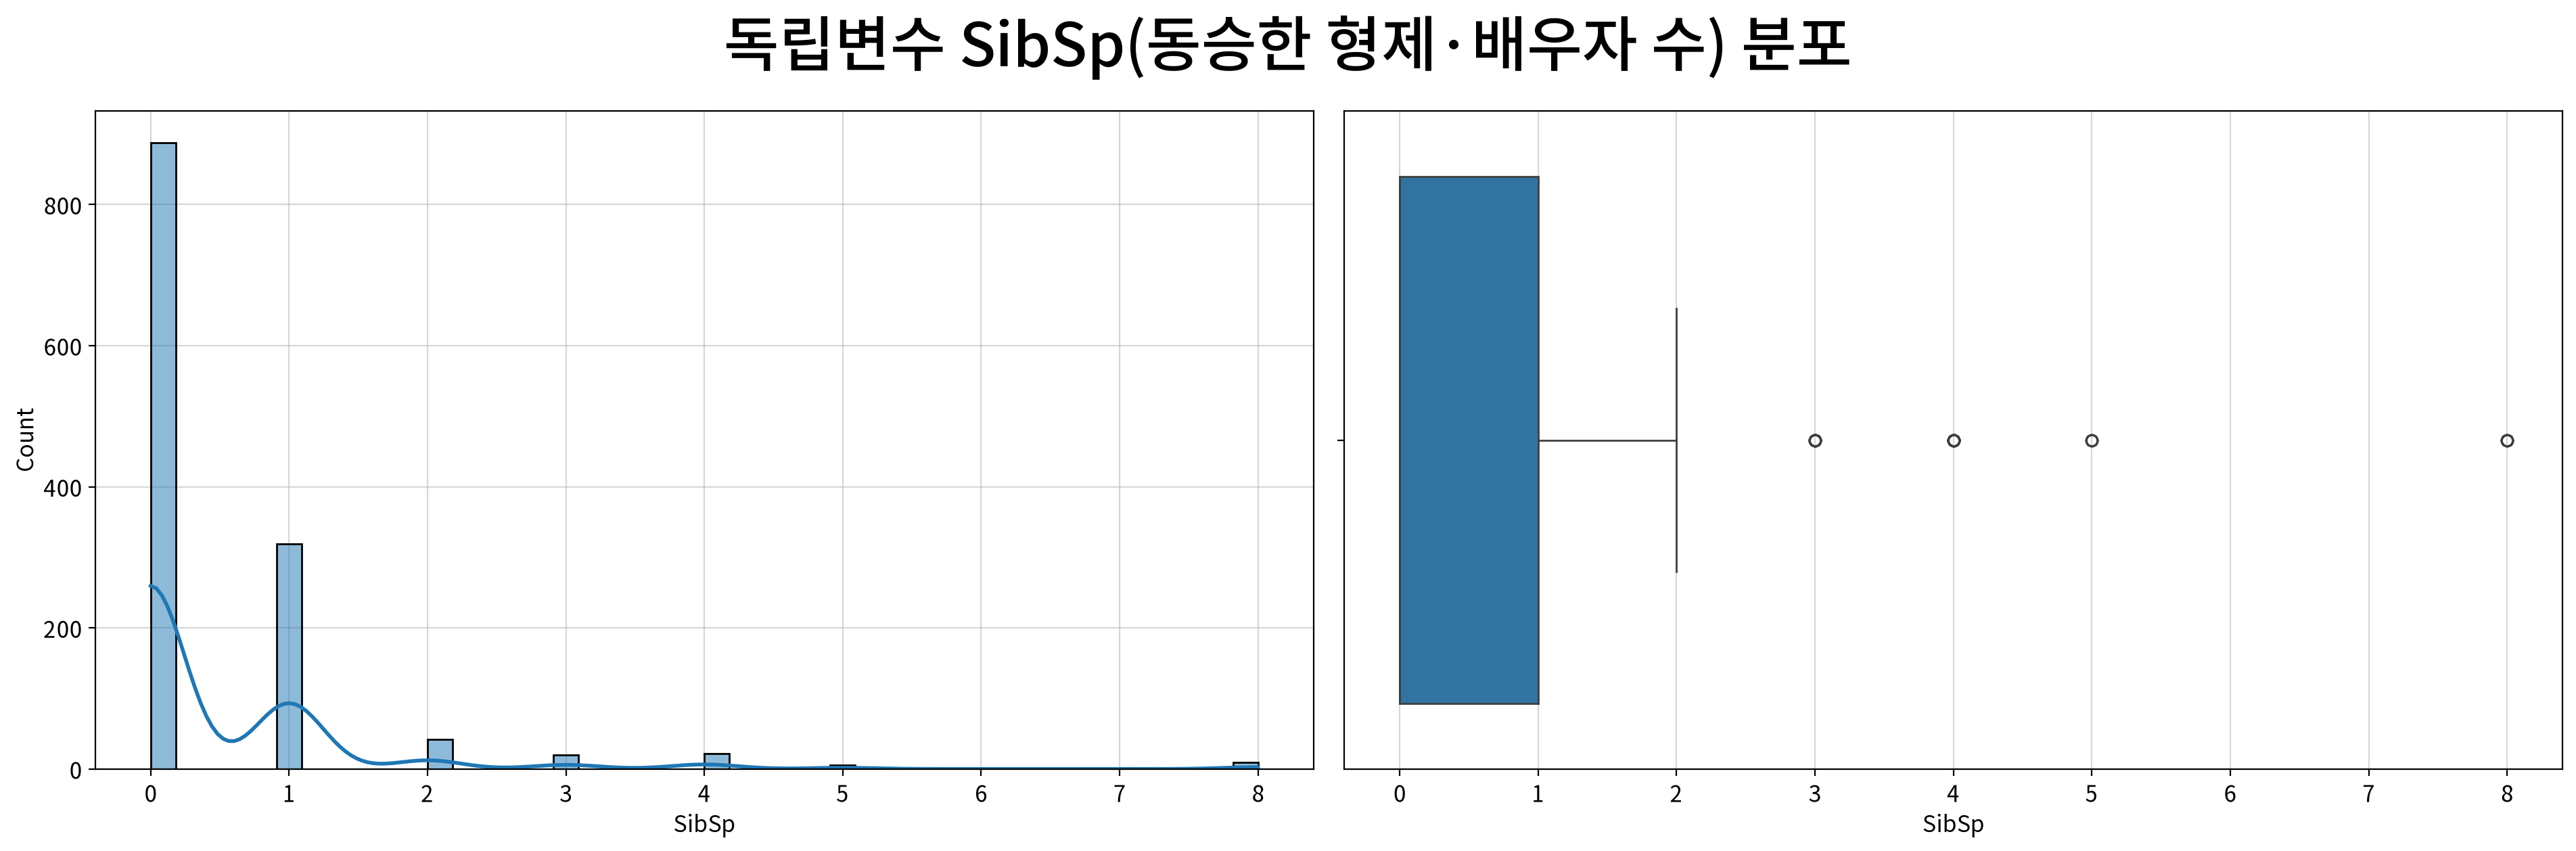

,SibSp
count,1306.000
mean,0.500
std,1.043
min,0.000
25%,0.000
50%,0.000
75%,1.000
max,8.000
rel_diff,inf
rdiff_flag,large_diff


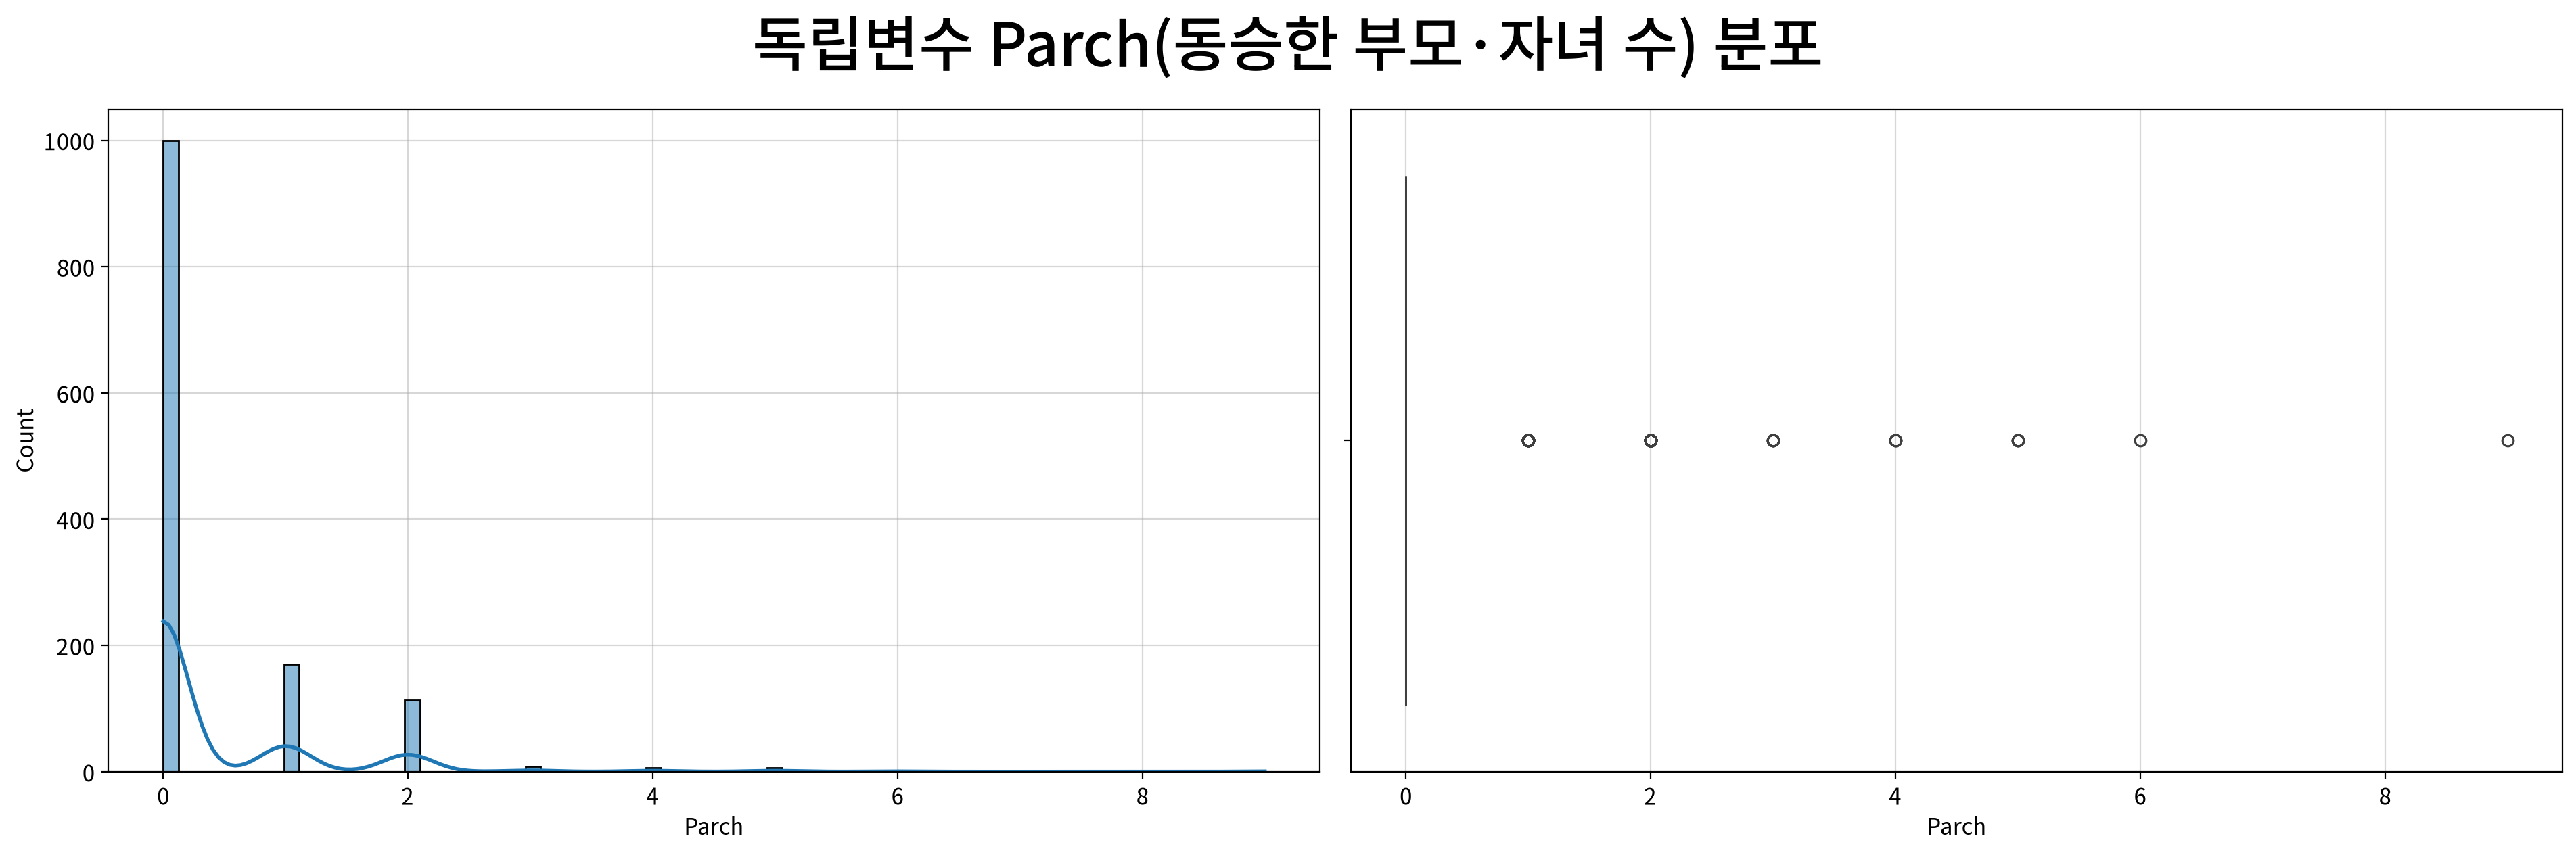

,Parch
count,1306.000
mean,0.386
std,0.866
min,0.000
25%,0.000
50%,0.000
75%,0.000
max,9.000
rel_diff,inf
rdiff_flag,large_diff


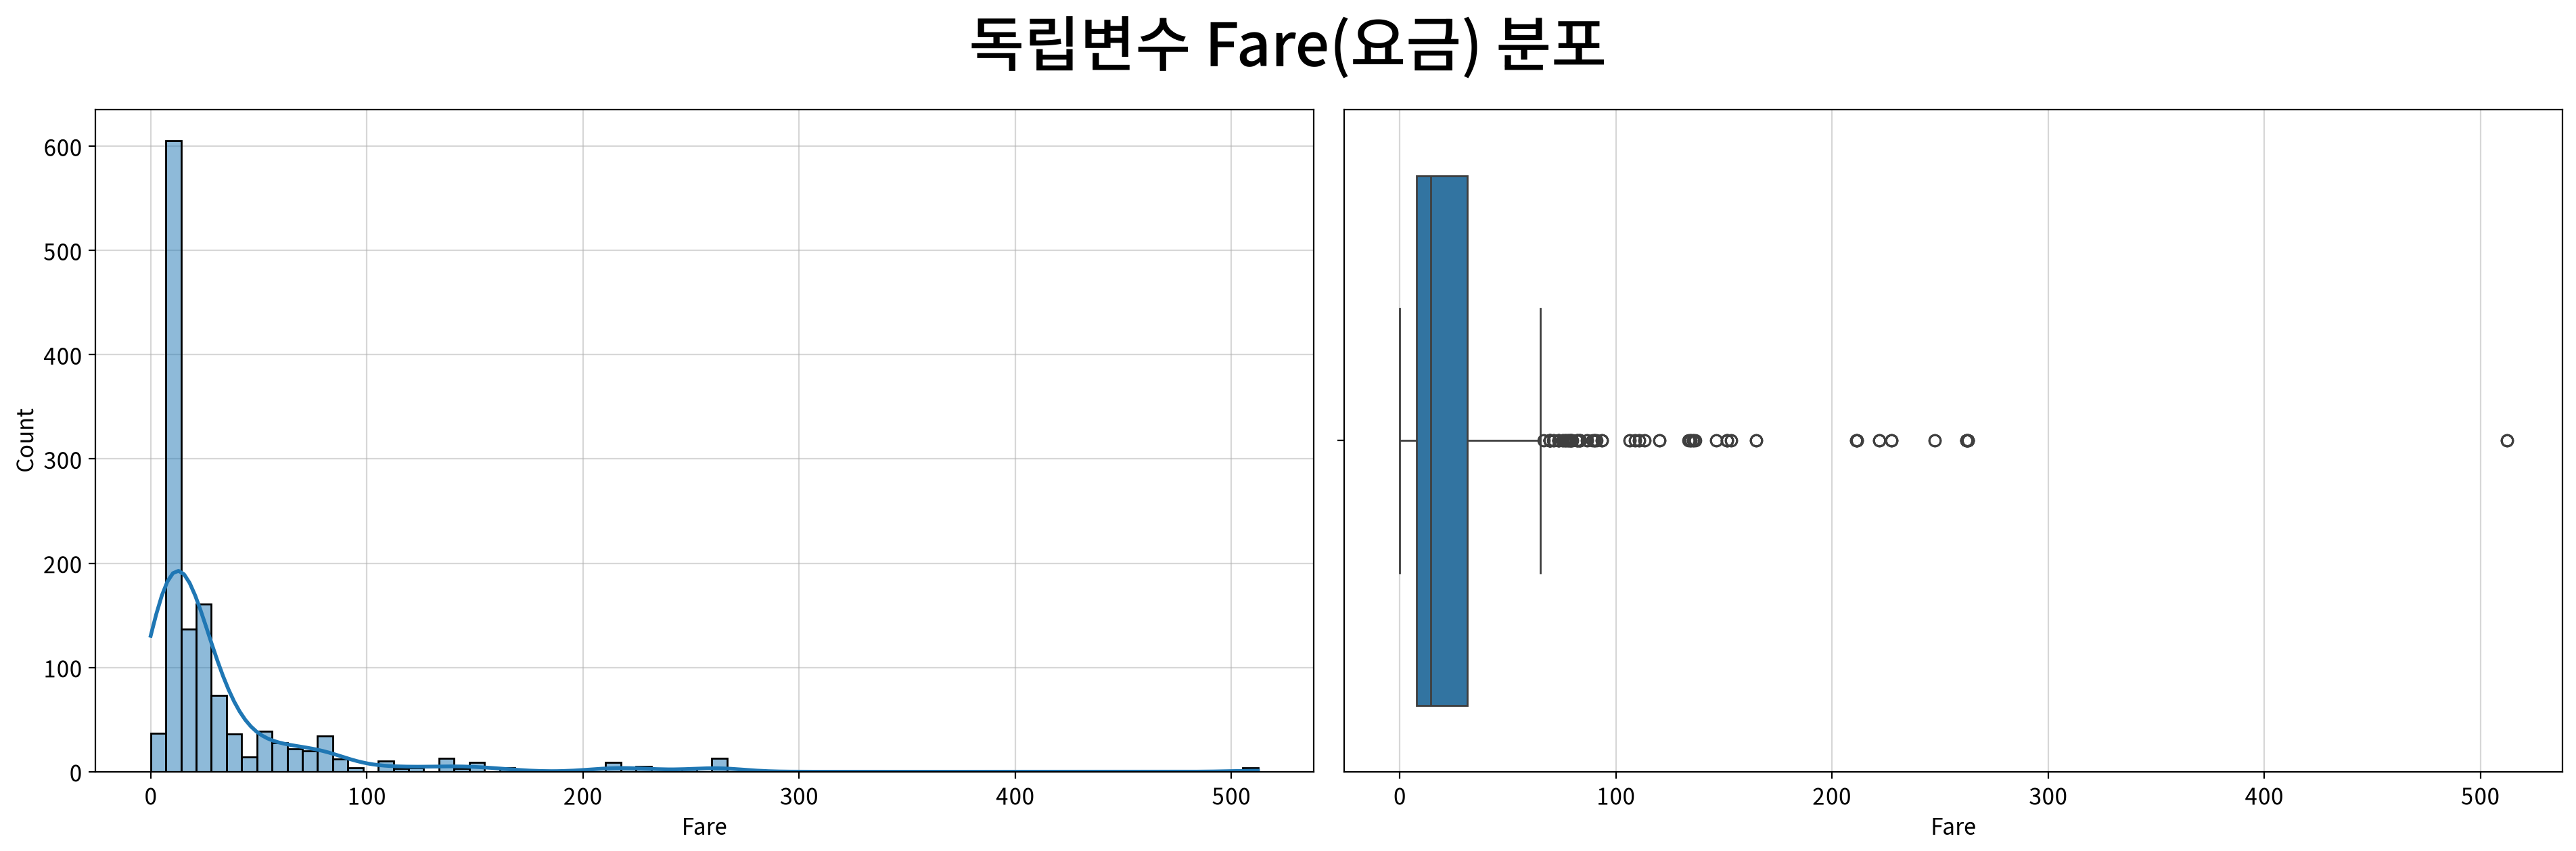

,Fare
count,1306.000
mean,33.224
std,51.766
min,0.000
25%,7.896
50%,14.454
75%,31.275
max,512.329
rel_diff,1.299
rdiff_flag,large_diff


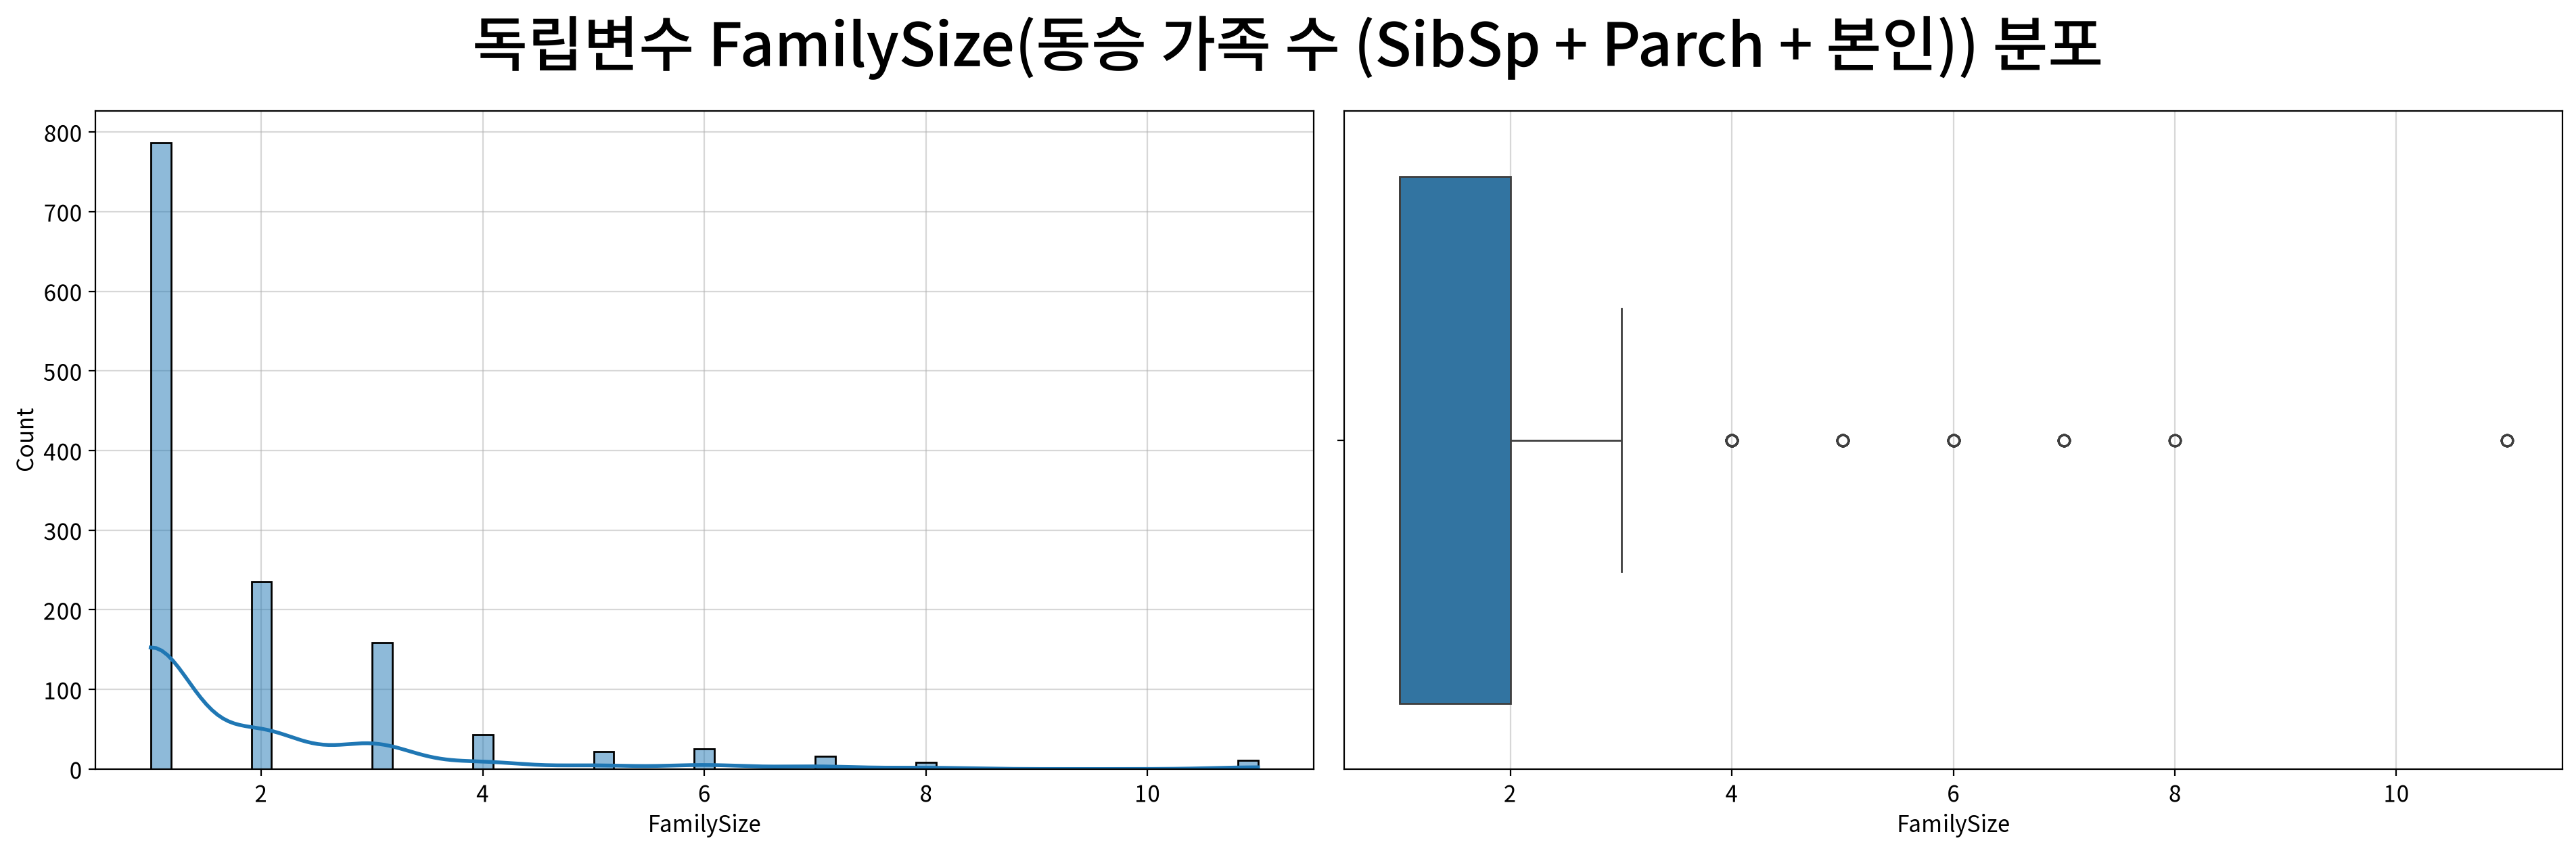

,FamilySize
count,1306.000
mean,1.886
std,1.585
min,1.000
25%,1.000
50%,1.000
75%,2.000
max,11.000
rel_diff,0.886
rdiff_flag,large_diff


In [19]:
for f in continuous_cols:
    fig, ax = my_plot.init(rows=1, cols=2, width=960, height=640,
                           title=f"독립변수 {f}({column_means[f]}) 분포")
    my_plot.histplot(data=df, x=f, kde=True, ax=ax[0])
    my_plot.boxplot(data=df, x=f, ax=ax[1])
    my_plot.show()

    display(num_desc.loc[[f]].T)

---
##### 💡 인사이트

| 변수 | 분포 모양 (왜도) | 이상치 | 판단 |
|---|---|---|---|
| `Age` | 약한 우편향 (0.54), **28세에 솟은 막대** | 7.6% | 중앙값(28세) 대체의 흔적 |
| `SibSp` | 심한 우편향 (3.84), 0에 집중 | 4.4% | 카운트 변수 |
| `Parch` | 심한 우편향 (3.67), 0에 집중 | 23.5% | 카운트 변수 — **Q1 = Q3 = 0이라 IQR 이상치 판정이 무의미** |
| `Fare` | 극심한 우편향 (4.38), 저가에 집중 | 12.9% | 높은 요금은 실제 1등석 가격 — 오류가 아니라 정보(삭제 시 객실 등급 정보가 사라짐) |
| `FamilySize` | 우편향 (2.85), **1명(단독)에 집중** | 9.6% | 카운트 변수 — 4명 이상이 이상치로 잡힘 |

- **`Age` 히스토그램의 28세 자리에 막대가 솟아 있다.** 결측 263명을 중앙값으로 채운 흔적이다. 실제 데이터가 아니라 **채워 넣은 값**이므로 이후 결과를 볼 때 염두에 둔다.
- `SibSp` · `Parch` · `FamilySize` 같은 **카운트 변수**에 IQR 이상치 대체를 쓰면, 의미 있는 값(가족이 많은 승객)이 눌려 버린다. → 이상치 대체는 `Age` · `Fare`에만 적용한다.
- 로지스틱 회귀는 잔차의 정규성 · 등분산성을 가정하지 않으므로 **왜도만으로 변환하지 않는다.** 변환 여부는 로짓 선형성 검정이 결정한다.

---

## 2-2. 이변량 분석 — 생존자와 사망자는 다른가?

### (1) 연속형 × 생존 : 독립표본 검정

#### ▶︎ Age(나이) → Survived

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:2.665e-01 U_stat=2.075e+05


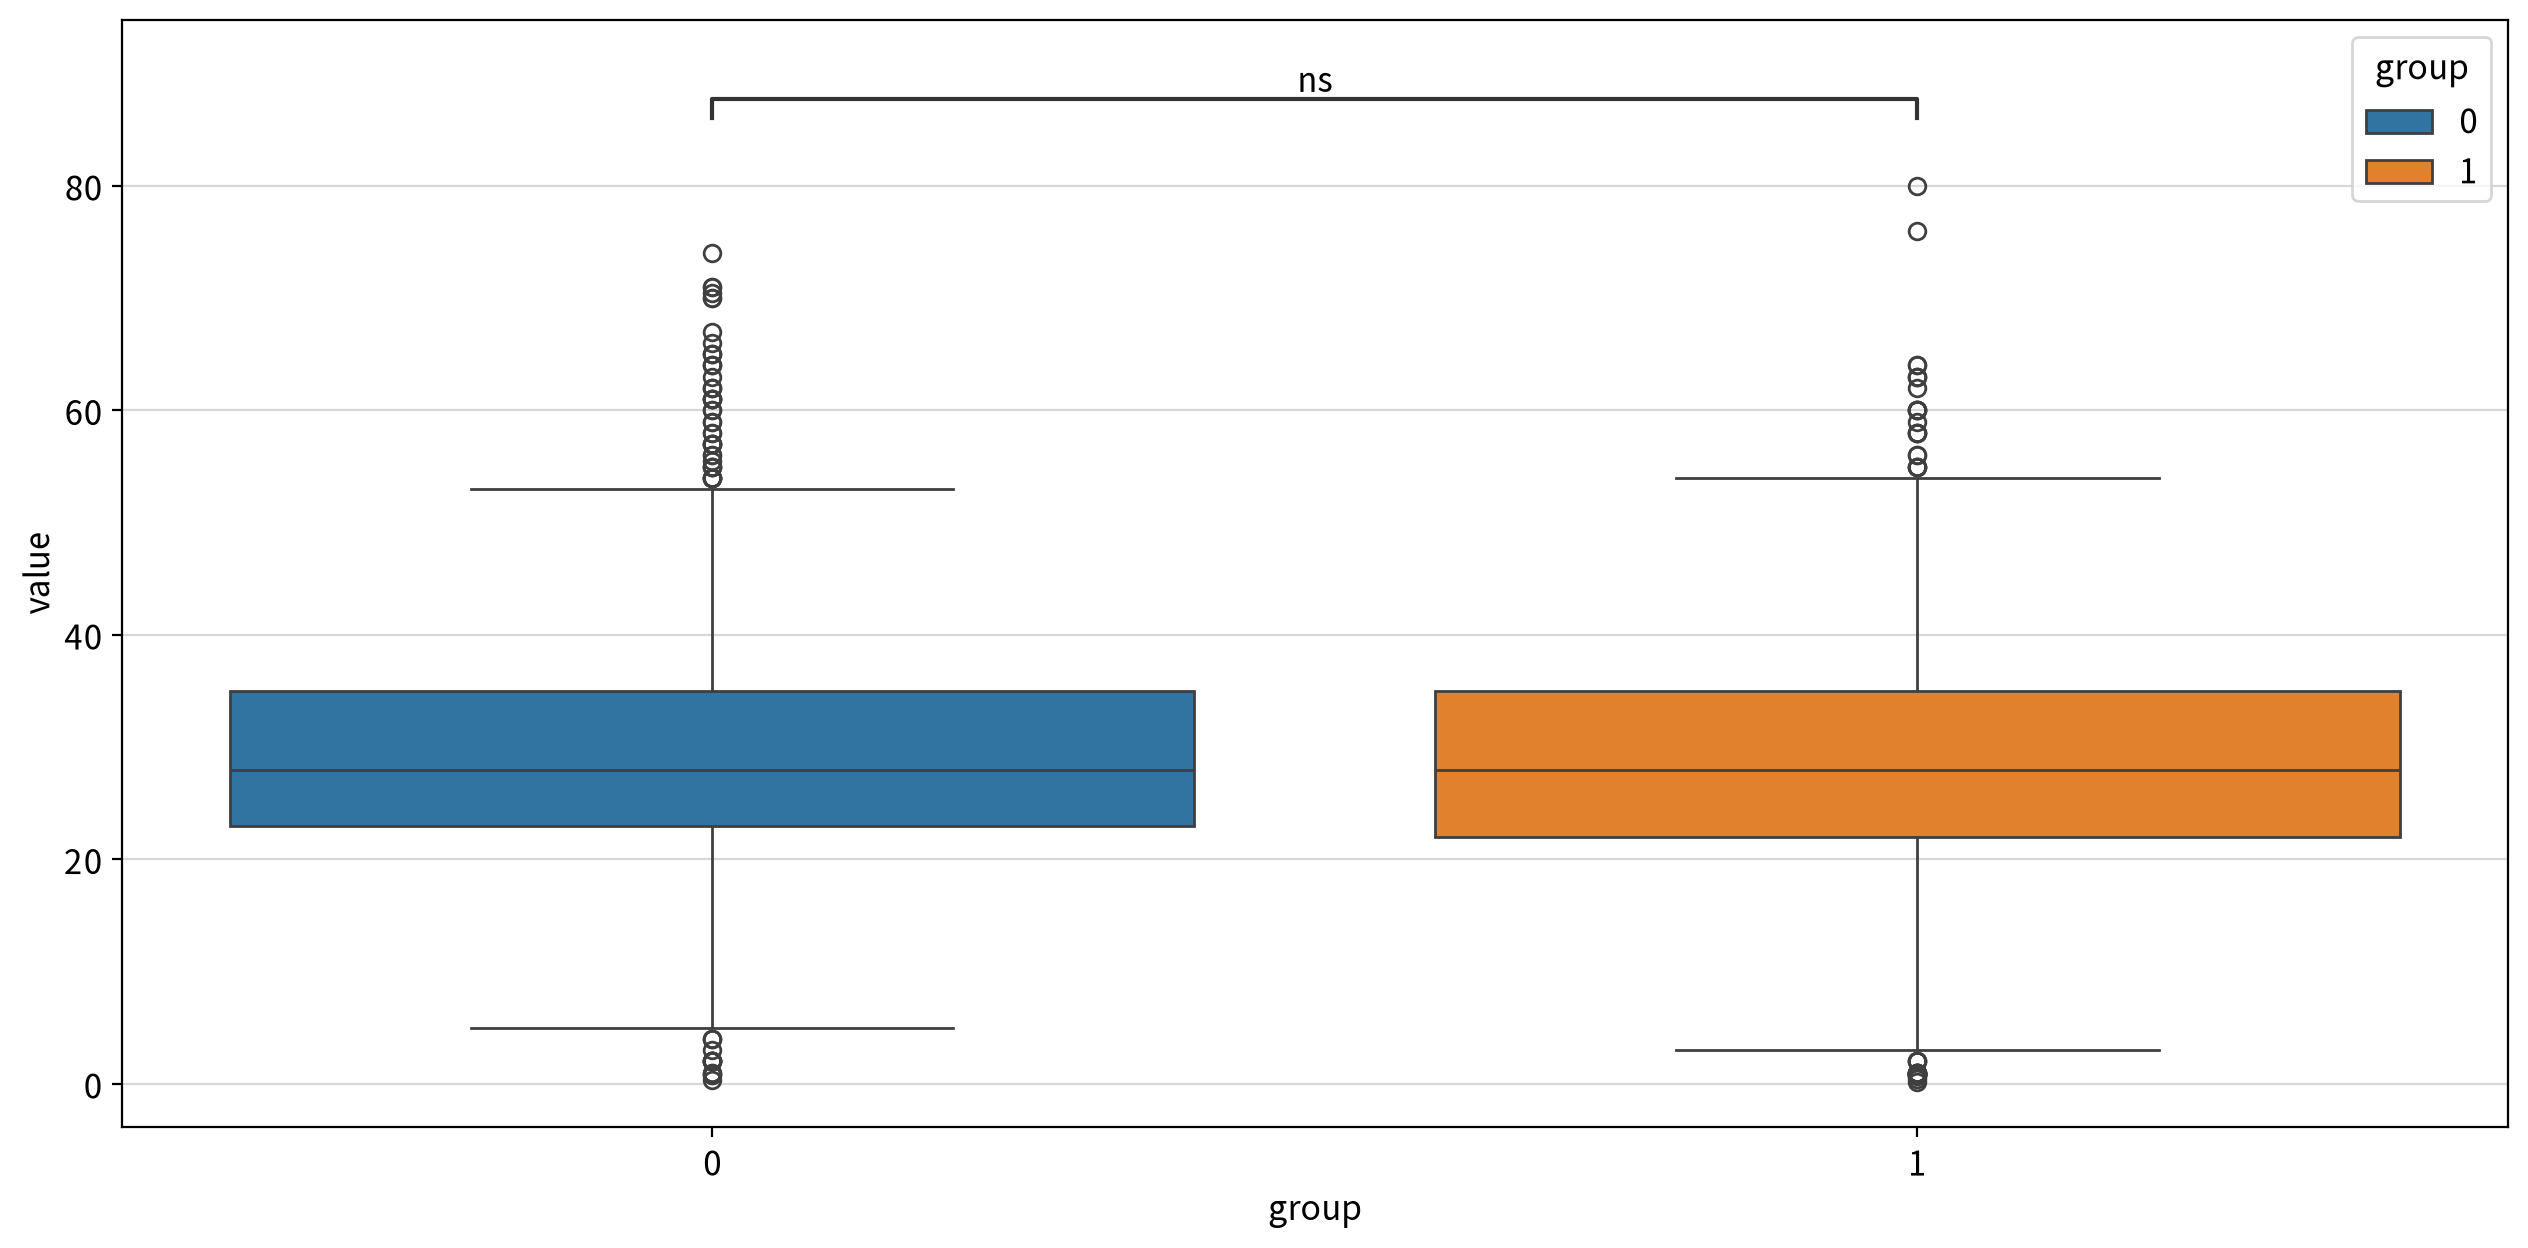

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   207540.000    0.267        False  0 = 1
                    less        207540.000    0.867        False  0 ≥ 1
                    greater     207540.000    0.133        False  0 ≤ 1

#### ▶︎ SibSp(동승한 형제·배우자 수) → Survived

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:7.787e-05 U_stat=1.789e+05


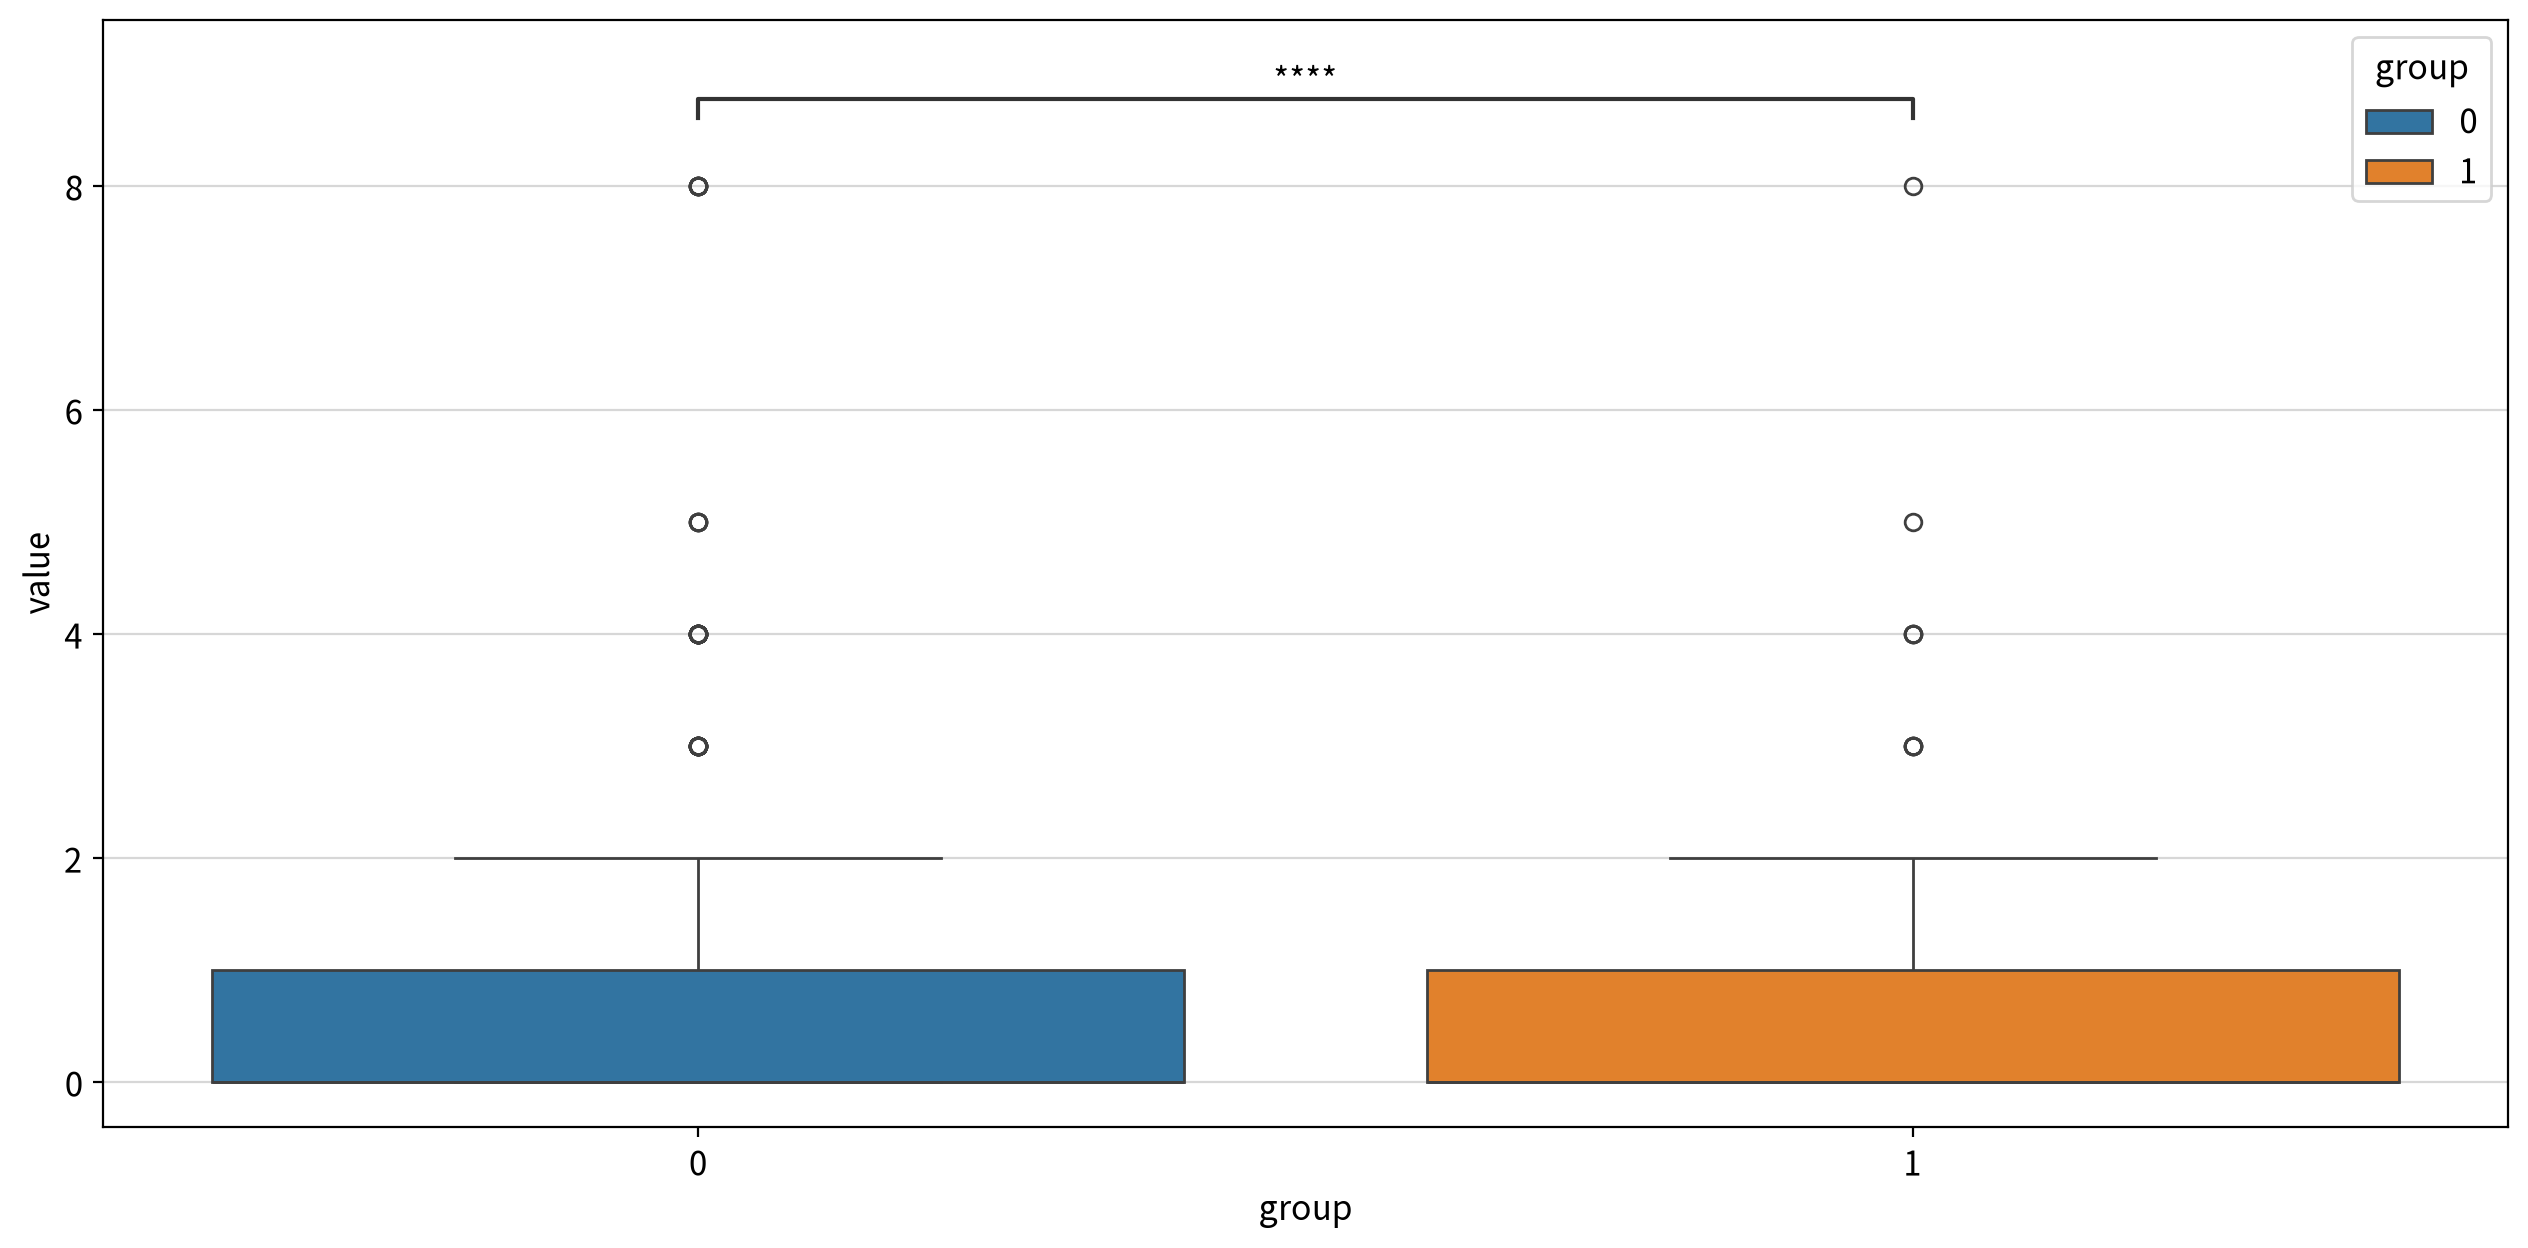

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   178868.500    0.000         True  0 ≠ 1
                    less        178868.500    0.000         True  0 < 1
                    greater     178868.500    1.000        False  0 ≤ 1

#### ▶︎ Parch(동승한 부모·자녀 수) → Survived

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.646e-09 U_stat=1.707e+05


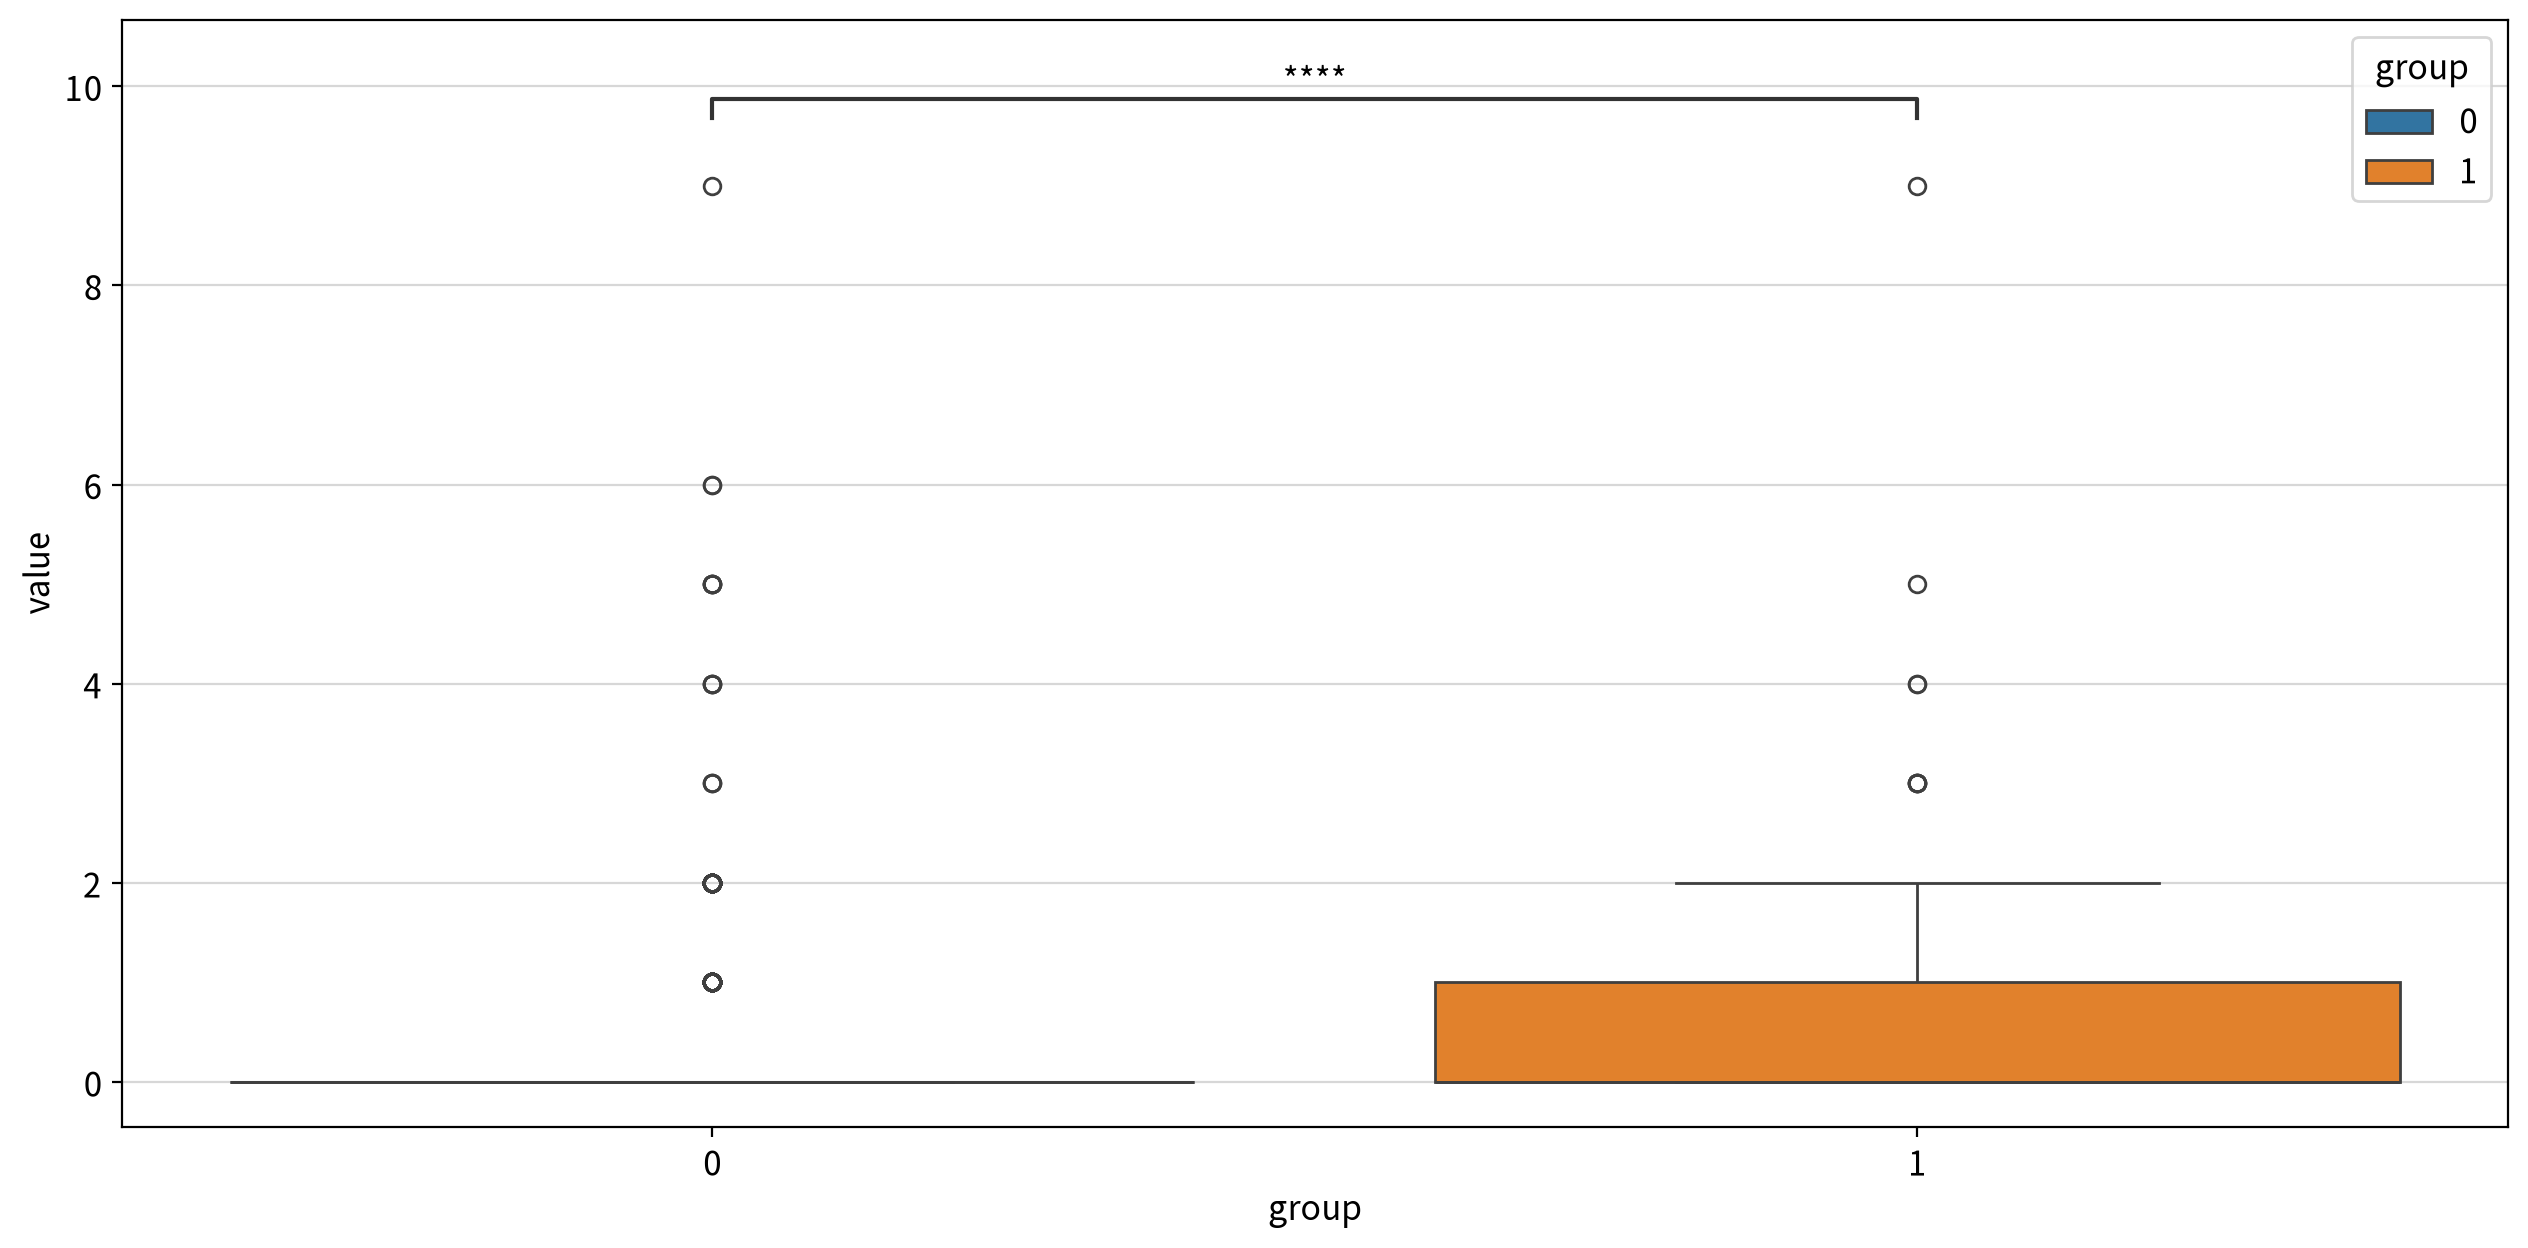

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   170723.000    0.000         True  0 ≠ 1
                    less        170723.000    0.000         True  0 < 1
                    greater     170723.000    1.000        False  0 ≤ 1

#### ▶︎ Fare(요금) → Survived

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:1.570e-24 U_stat=1.327e+05


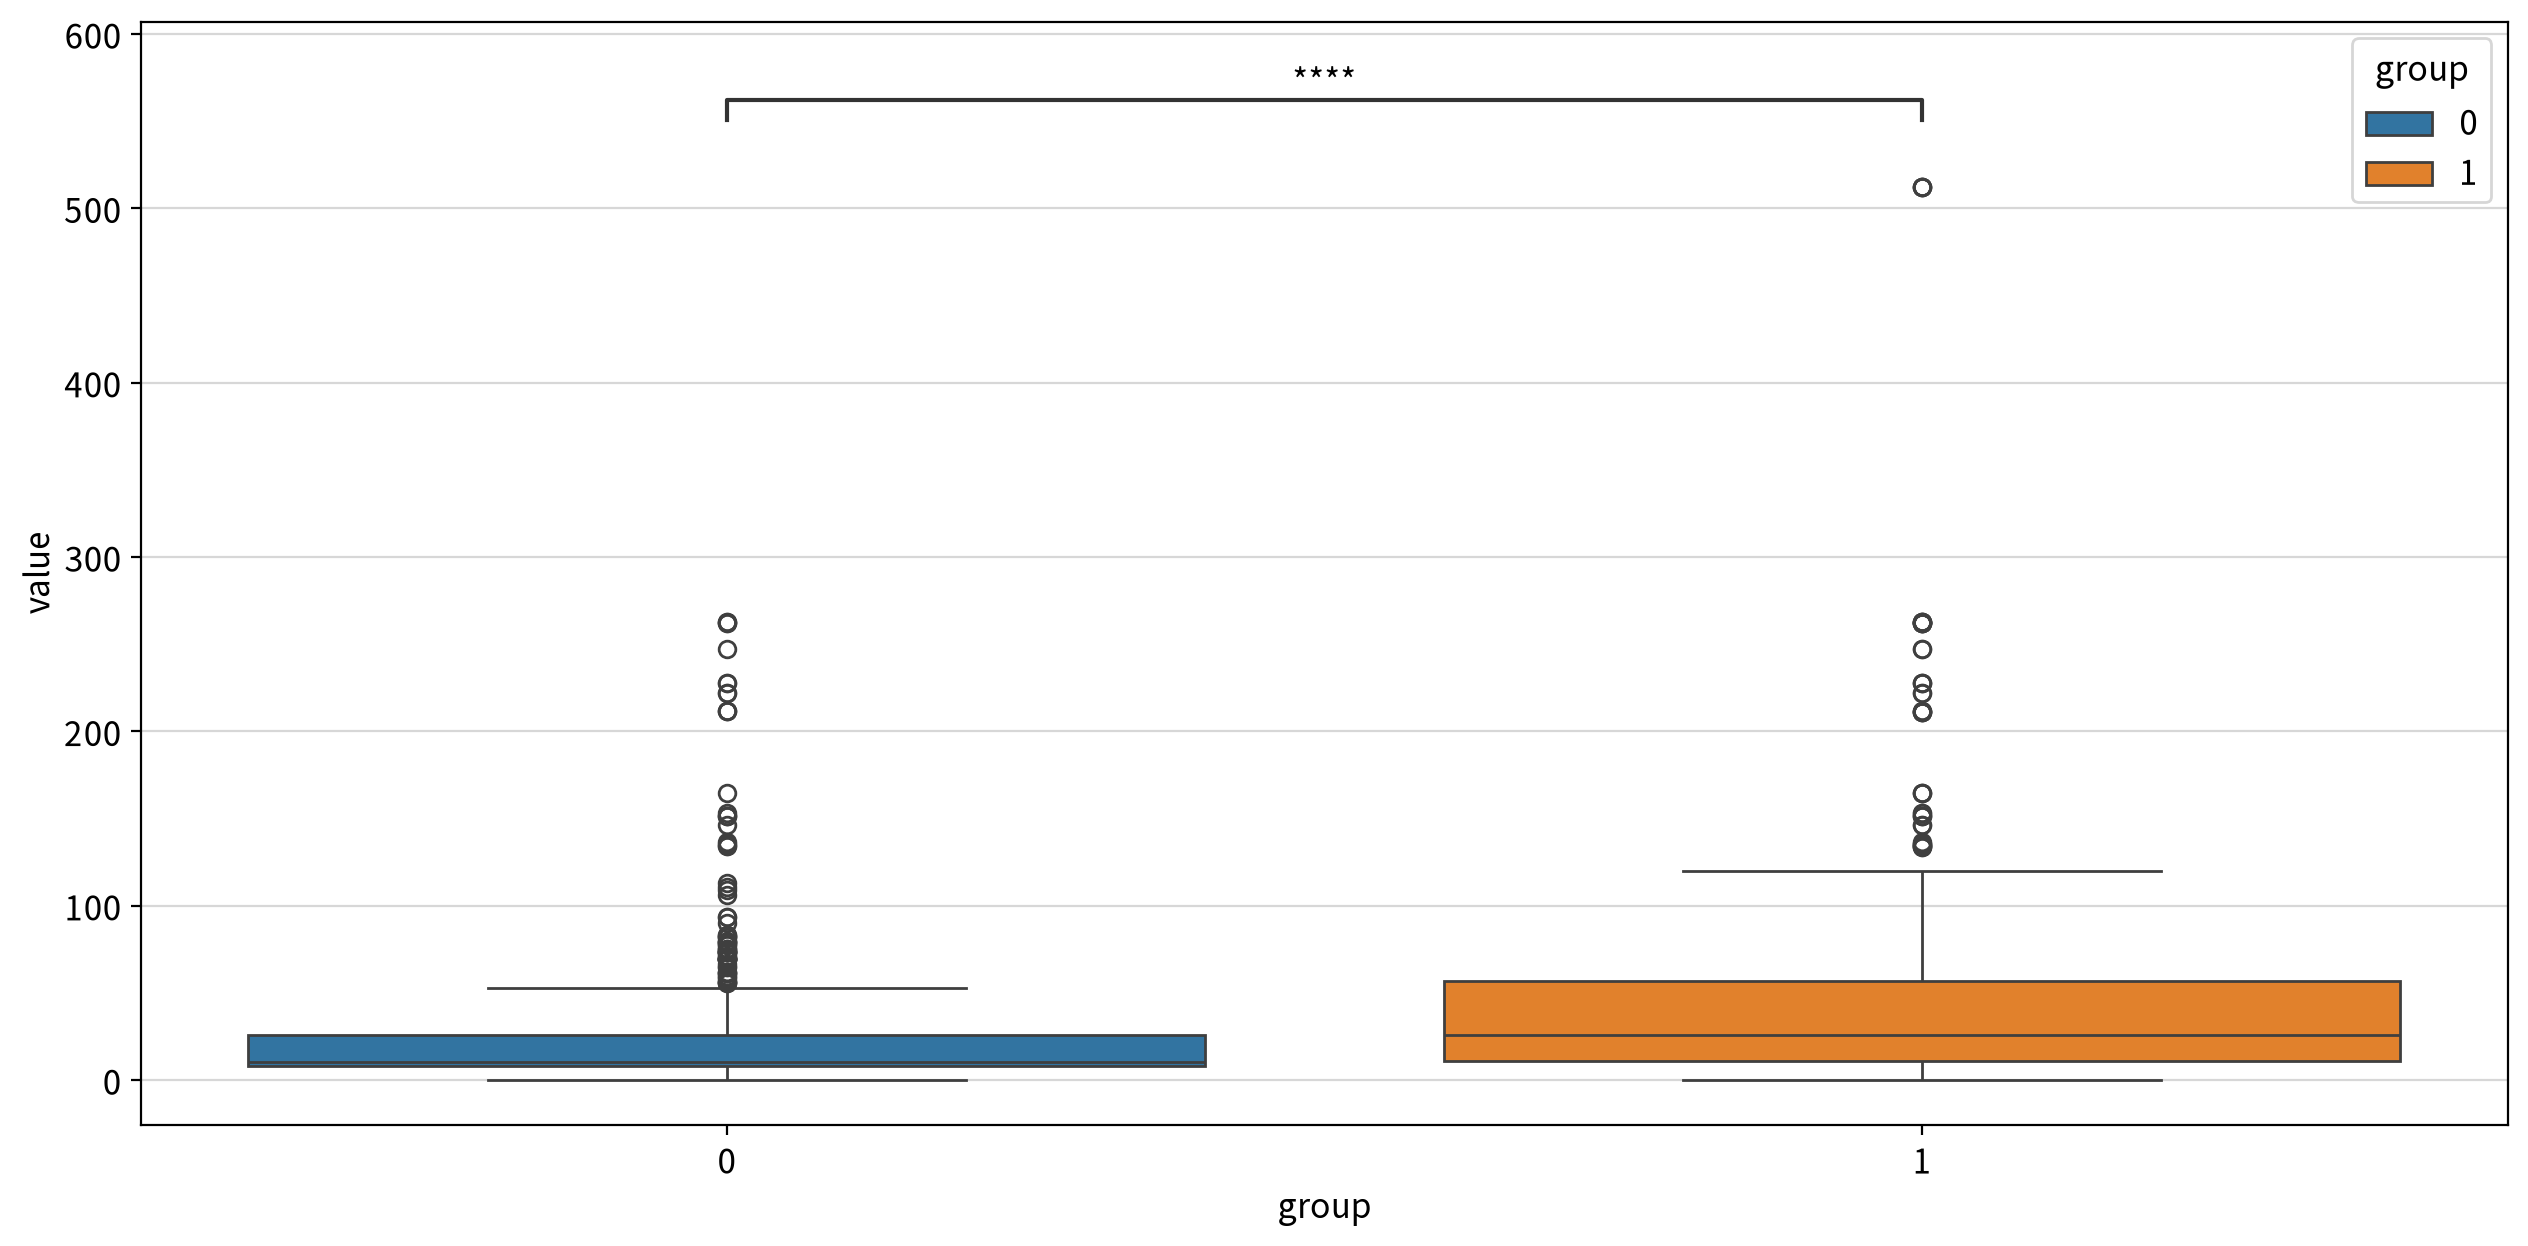

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   132743.000    0.000         True  0 ≠ 1
                    less        132743.000    0.000         True  0 < 1
                    greater     132743.000    1.000        False  0 ≤ 1

#### ▶︎ FamilySize(동승 가족 수 (SibSp + Parch + 본인)) → Survived

p-value annotation legend:
      ns: 5.00e-02 < p <= 1.00e+00
       *: 1.00e-02 < p <= 5.00e-02
      **: 1.00e-03 < p <= 1.00e-02
     ***: 1.00e-04 < p <= 1.00e-03
    ****: p <= 1.00e-04

0 vs. 1: Mann-Whitney-Wilcoxon test two-sided, P_val:5.986e-12 U_stat=1.603e+05


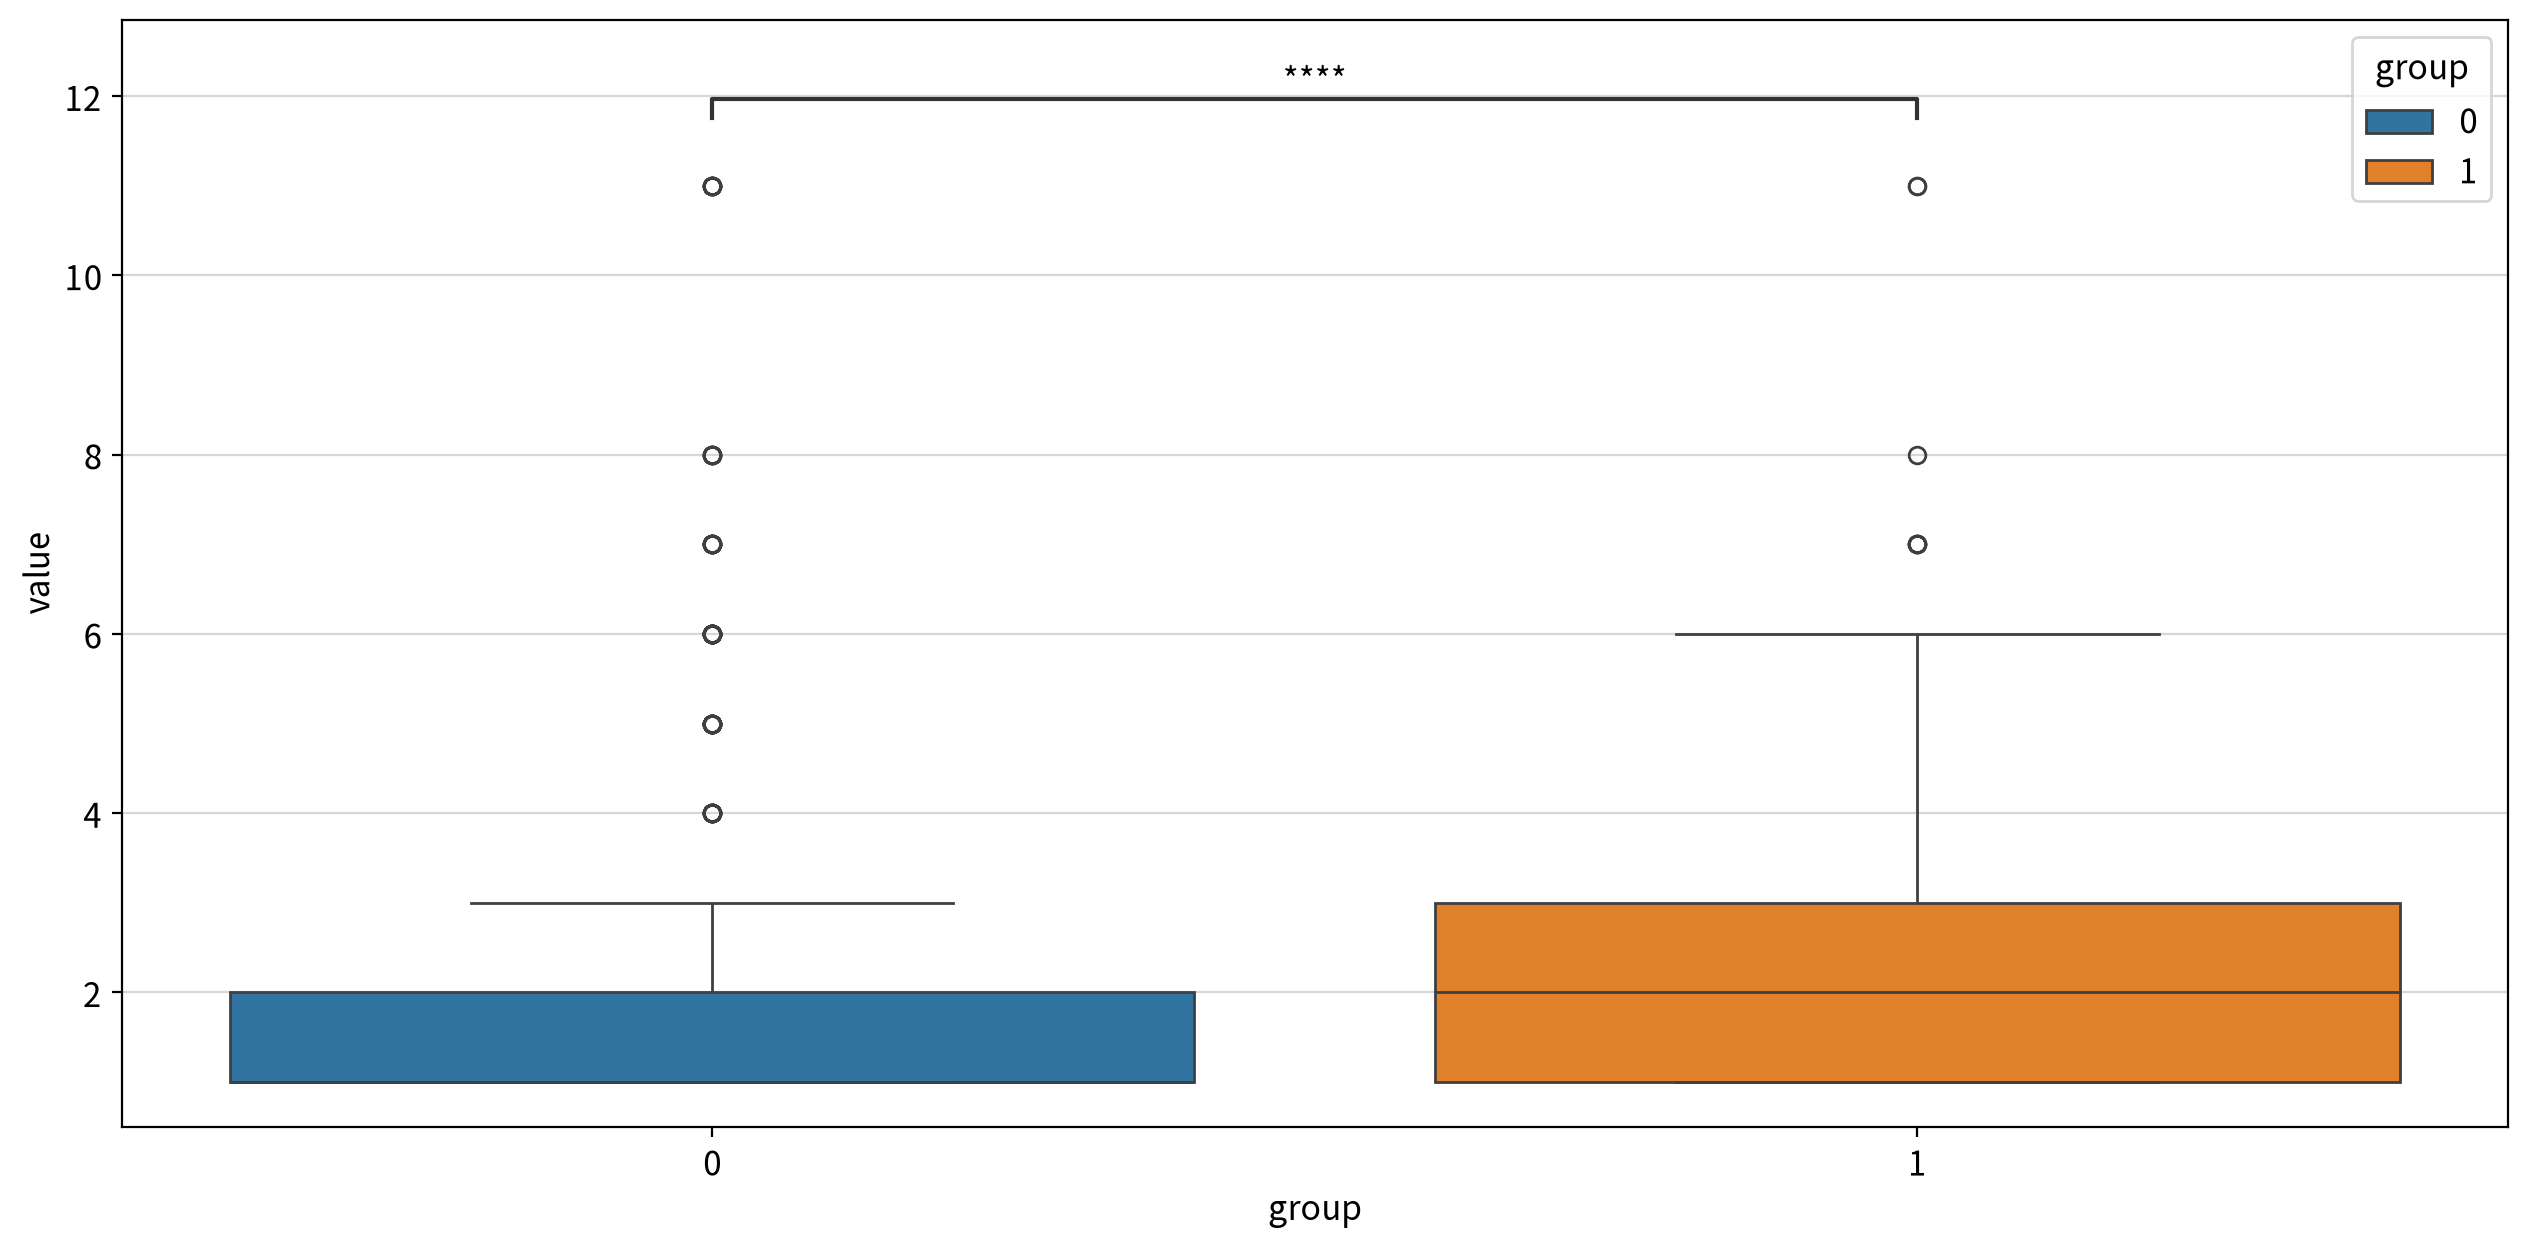

statistic  p-value  significant result
test                alternative                                        
Mann-Whitney U test two-sided   160280.500    0.000         True  0 ≠ 1
                    less        160280.500    0.000         True  0 < 1
                    greater     160280.500    1.000        False  0 ≤ 1

In [20]:
for f in continuous_cols:
    print()
    display(Markdown(f"#### ▶︎ {f}({column_means[f]}) → {target}"))

    # 종속변수(Survived)가 집단 기준이 되므로 hue=target, values=f
    wide_df = my_prep.long2wide(df, hue=target, values=f)
    display(my_stats.test_independent(wide_df, 
                                      group1=wide_df.columns[0], group2=wide_df.columns[1]))

### (2) 가족 규모별 생존율

- 검정은 두 집단의 **중심 위치**만 비교한다. `FamilySize`는 값이 1~11인 카운트 변수라, **값별 생존율의 모양**을 직접 본다.

In [21]:
fs = df.groupby("FamilySize")[target].agg(생존율=lambda s: (s.astype(int) == 1).mean(), 
                                          인원수="size")
fs.T

FamilySize,1,2,3,4,5,6,7,8,11
생존율,0.291,0.532,0.560,0.721,0.227,0.200,0.312,0.125,0.182
인원수,787.000,235.000,159.000,43.000,22.000,25.000,16.000,8.000,11.000


---
##### 💡 인사이트

| 변수 | 검정 방법 | 유의확률 | 방향 | 단독 판정 |
|---|---|---|---|---|
| `Fare` | Mann-Whitney U | < 0.001 | 사망 < 생존 | ✅ 채택 |
| `Parch` | Mann-Whitney U | < 0.001 | 사망 < 생존 | ✅ 채택 |
| `FamilySize` | Mann-Whitney U | < 0.001 | 사망 < 생존 | ✅ 채택 |
| `SibSp` | Mann-Whitney U | < 0.001 | 사망 < 생존 | ✅ 채택 |
| `Age` | Mann-Whitney U | **0.267** | **차이 없음** | 🟡 보류 |

- 정규성이 깨져 **모든 변수에서 Mann-Whitney U**가 선택됐다.
- **`FamilySize`는 "많을수록 생존"이 아니다.** 가족 규모별 생존율을 보면:

| 가족 수 | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 11 |
|---|---|---|---|---|---|---|---|---|---|
| 생존율 | 29.1% | 53.2% | 56.0% | **72.1%** | 22.7% | 20.0% | 31.2% | 12.5% | 18.2% |
| 인원 | 787 | 235 | 159 | 43 | 22 | 25 | 16 | 8 | 11 |

- 단독(29.1%)에서 **4명까지 오르다가(72.1%), 5명부터 급락**한다. 검정이 '생존자 쪽이 크다'고 나온 건 단독 승객이 너무 많아서일 뿐, 실제 모양은 **오르다 꺾이는 ∩자**다. → 모델에서 이 모양을 어떻게 담을지 확인한다.
- **`Age`는 p = 0.267로 차이가 없었다.** 하지만 아이는 생존율이 높고 고령 남성은 낮아, 양 끝의 효과가 평균 비교에서 상쇄됐을 수 있다. 결측 263명이 28세로 채워진 영향도 있다. → 단독 판정은 보류하고 모델에서 다시 본다.

---

### (3) 명목형 × 생존 : 교차분석 (카이제곱 독립성 검정)

- 채택 기준 (명목형) : **유의(p < 0.05) + Cramér's V ≥ 0.1**(효과가 무시할 수준이 아님). 효과크기가 Weak여도 범주별 효과가 다를 수 있으므로 채택하고, 모델에서 최종 판정한다.

#### ▶︎ Pclass(객실 등급 (1=1등급, 2=2등급, 3=3등급)) → Survived

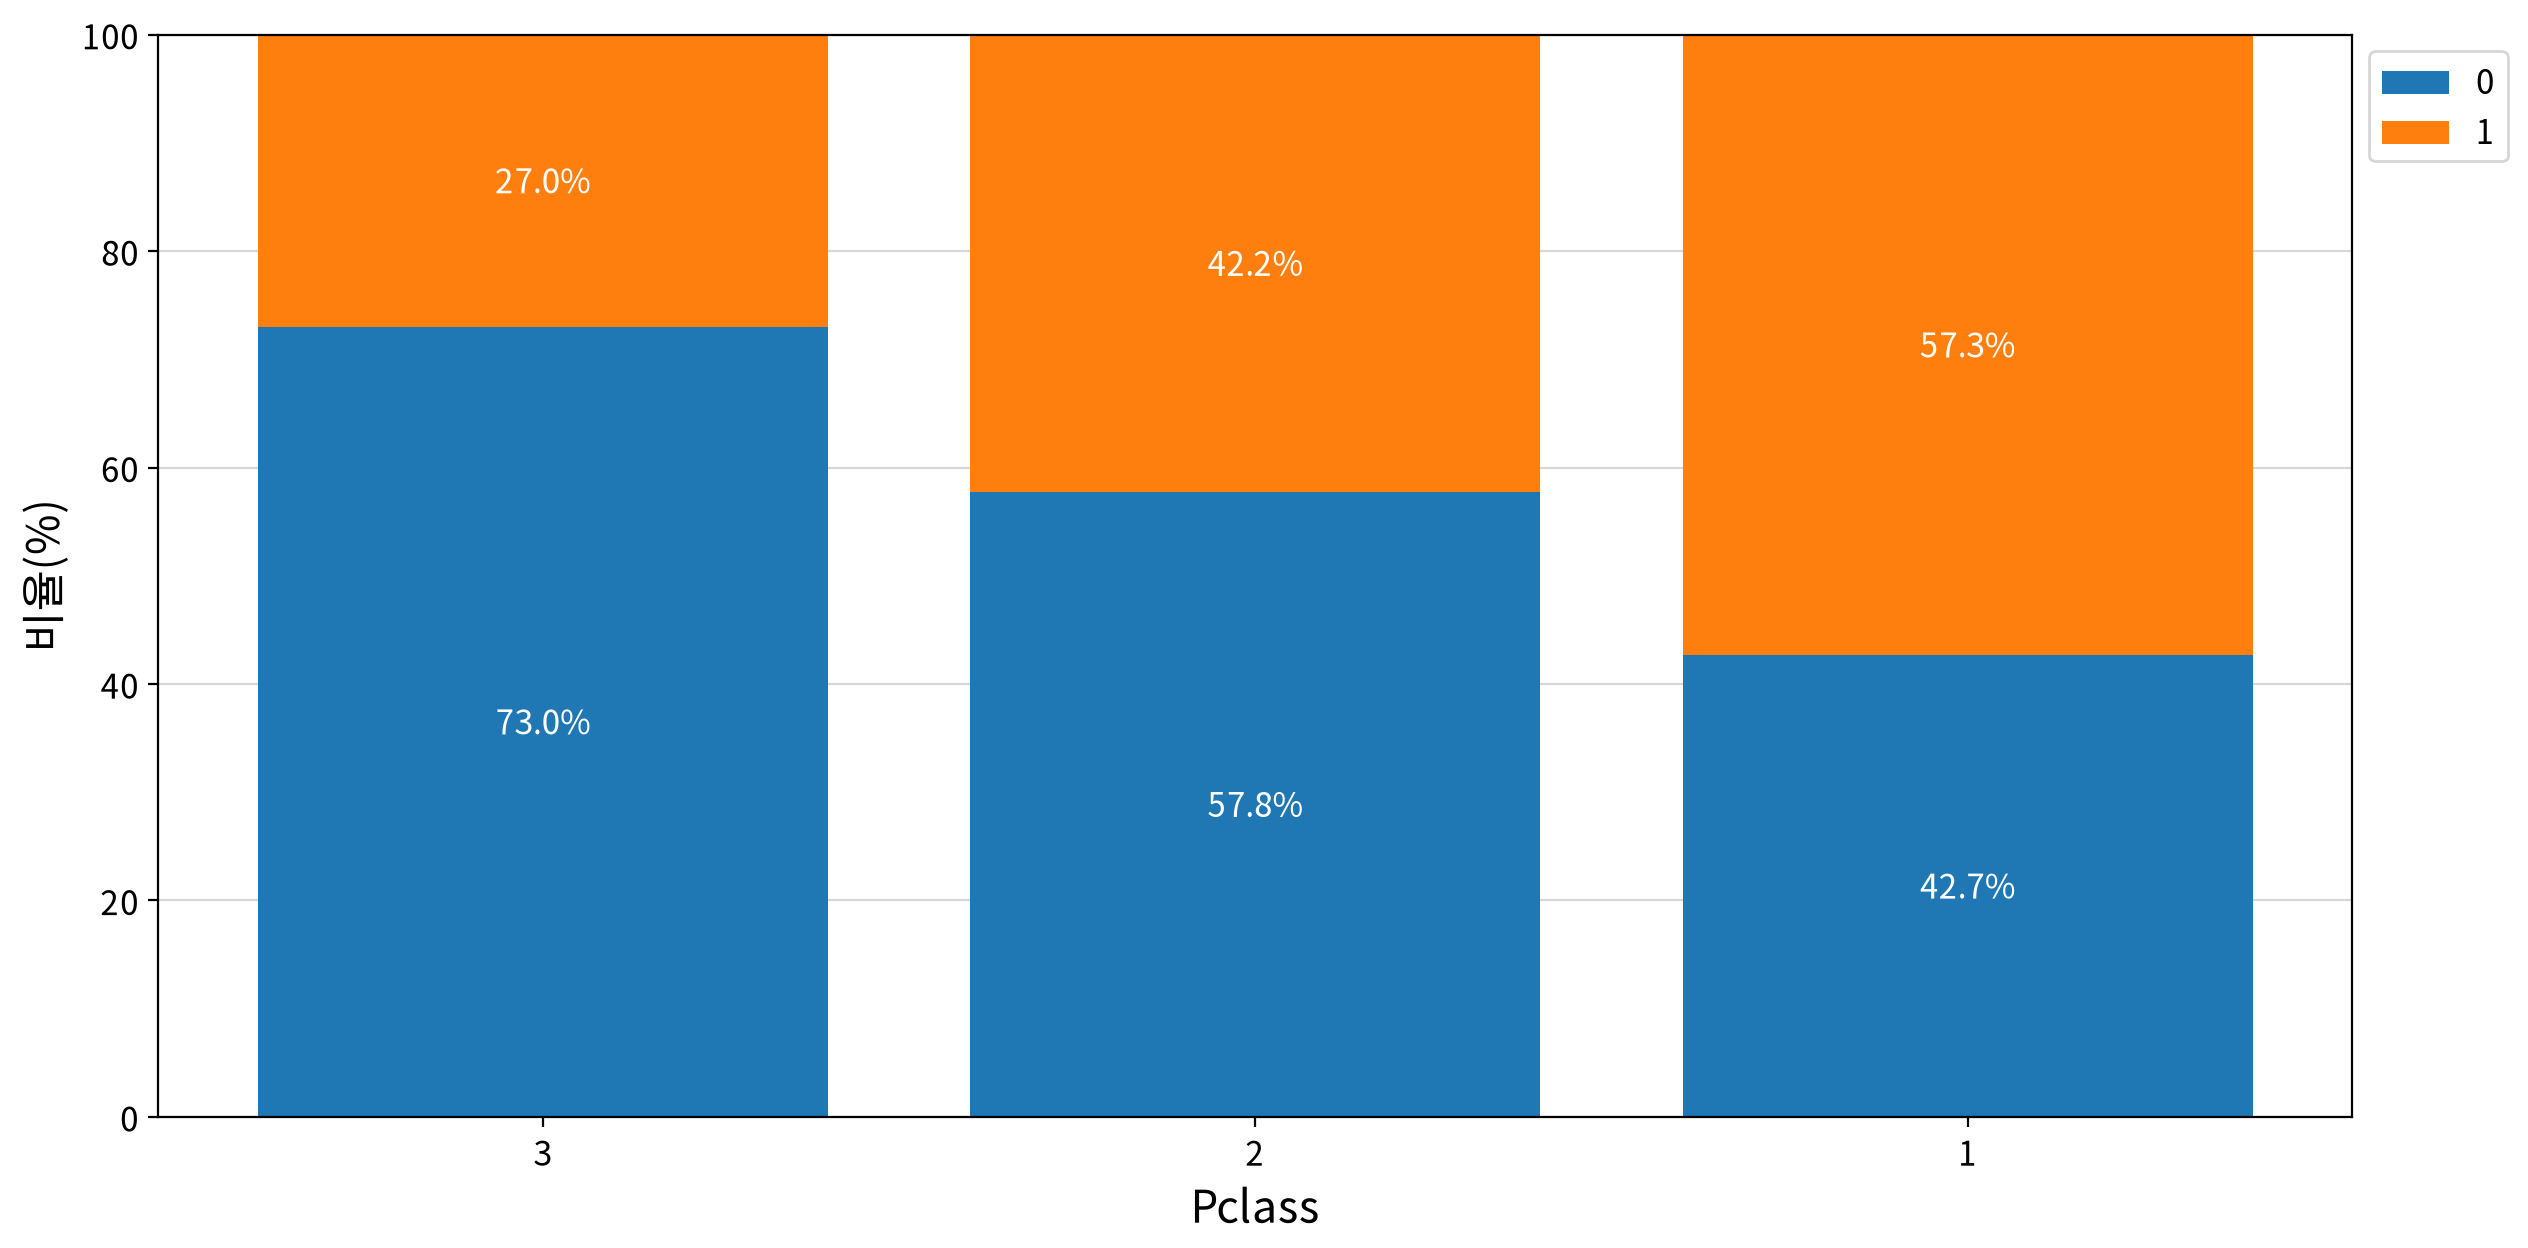

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Pclass,Survived,Chi-square test of independence,89.728,2,0.000,True,0.262,Weak,104.350,True


#### ▶︎ Sex(성별 (male, female)) → Survived

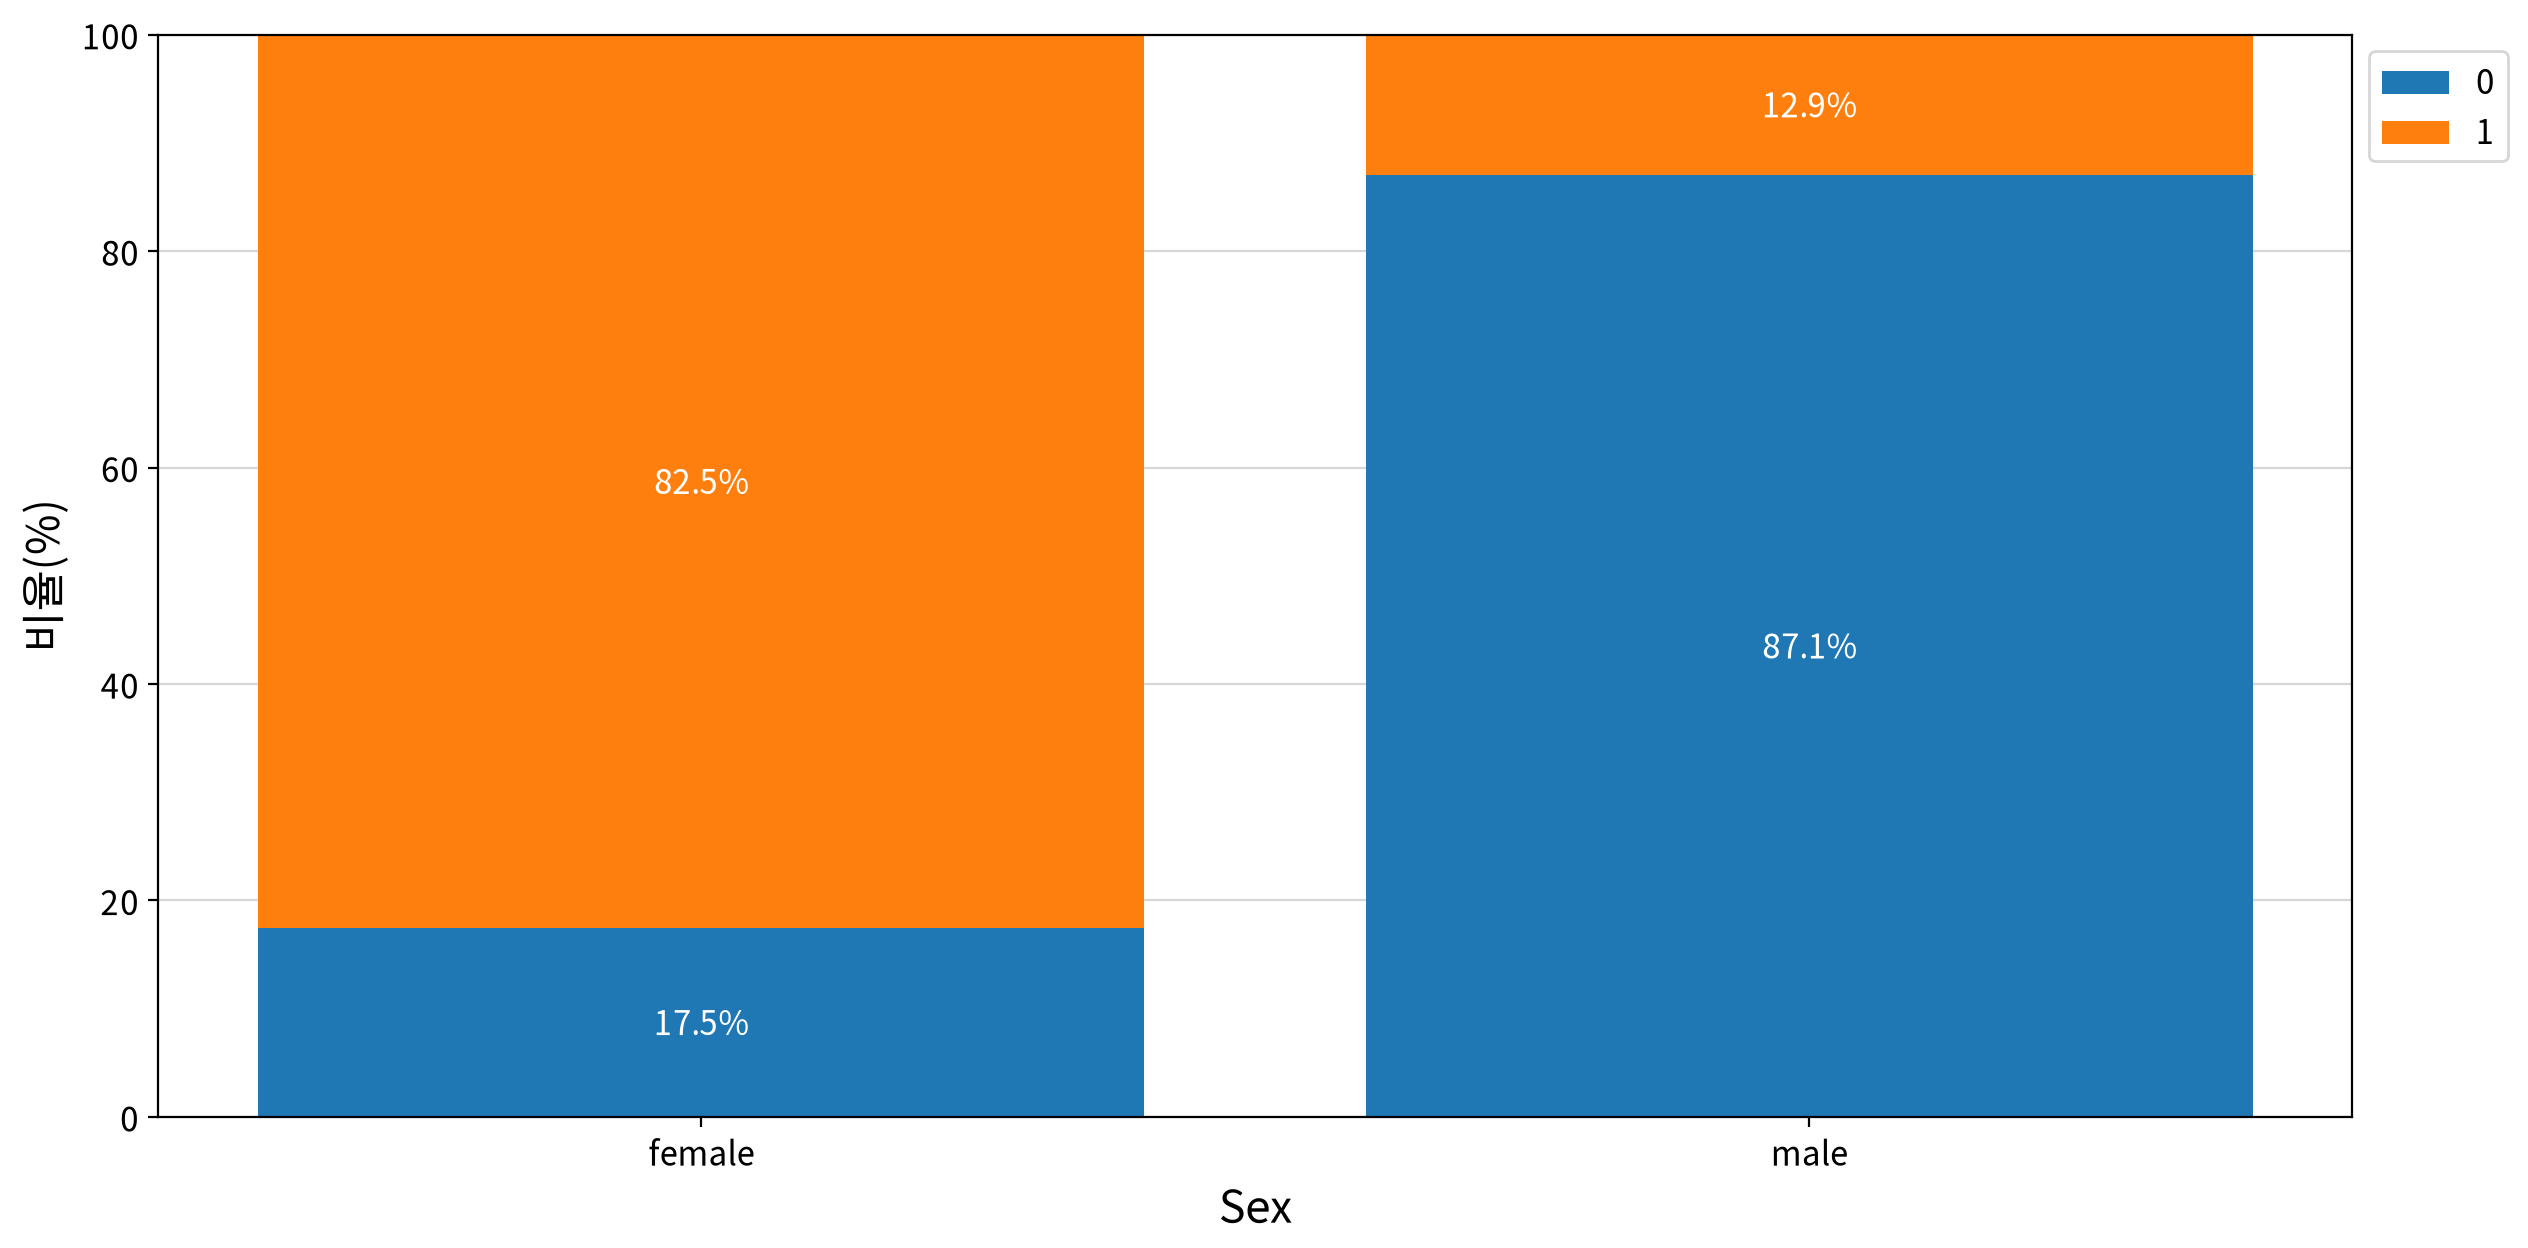

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Sex,Survived,Chi-square test of independence,614.166,1,0.000,True,0.686,Strong,174.800,True


#### ▶︎ Embarked(탑승 항구 (C=Cherbourg, Q=Queenstown, S=Southampton)) → Survived

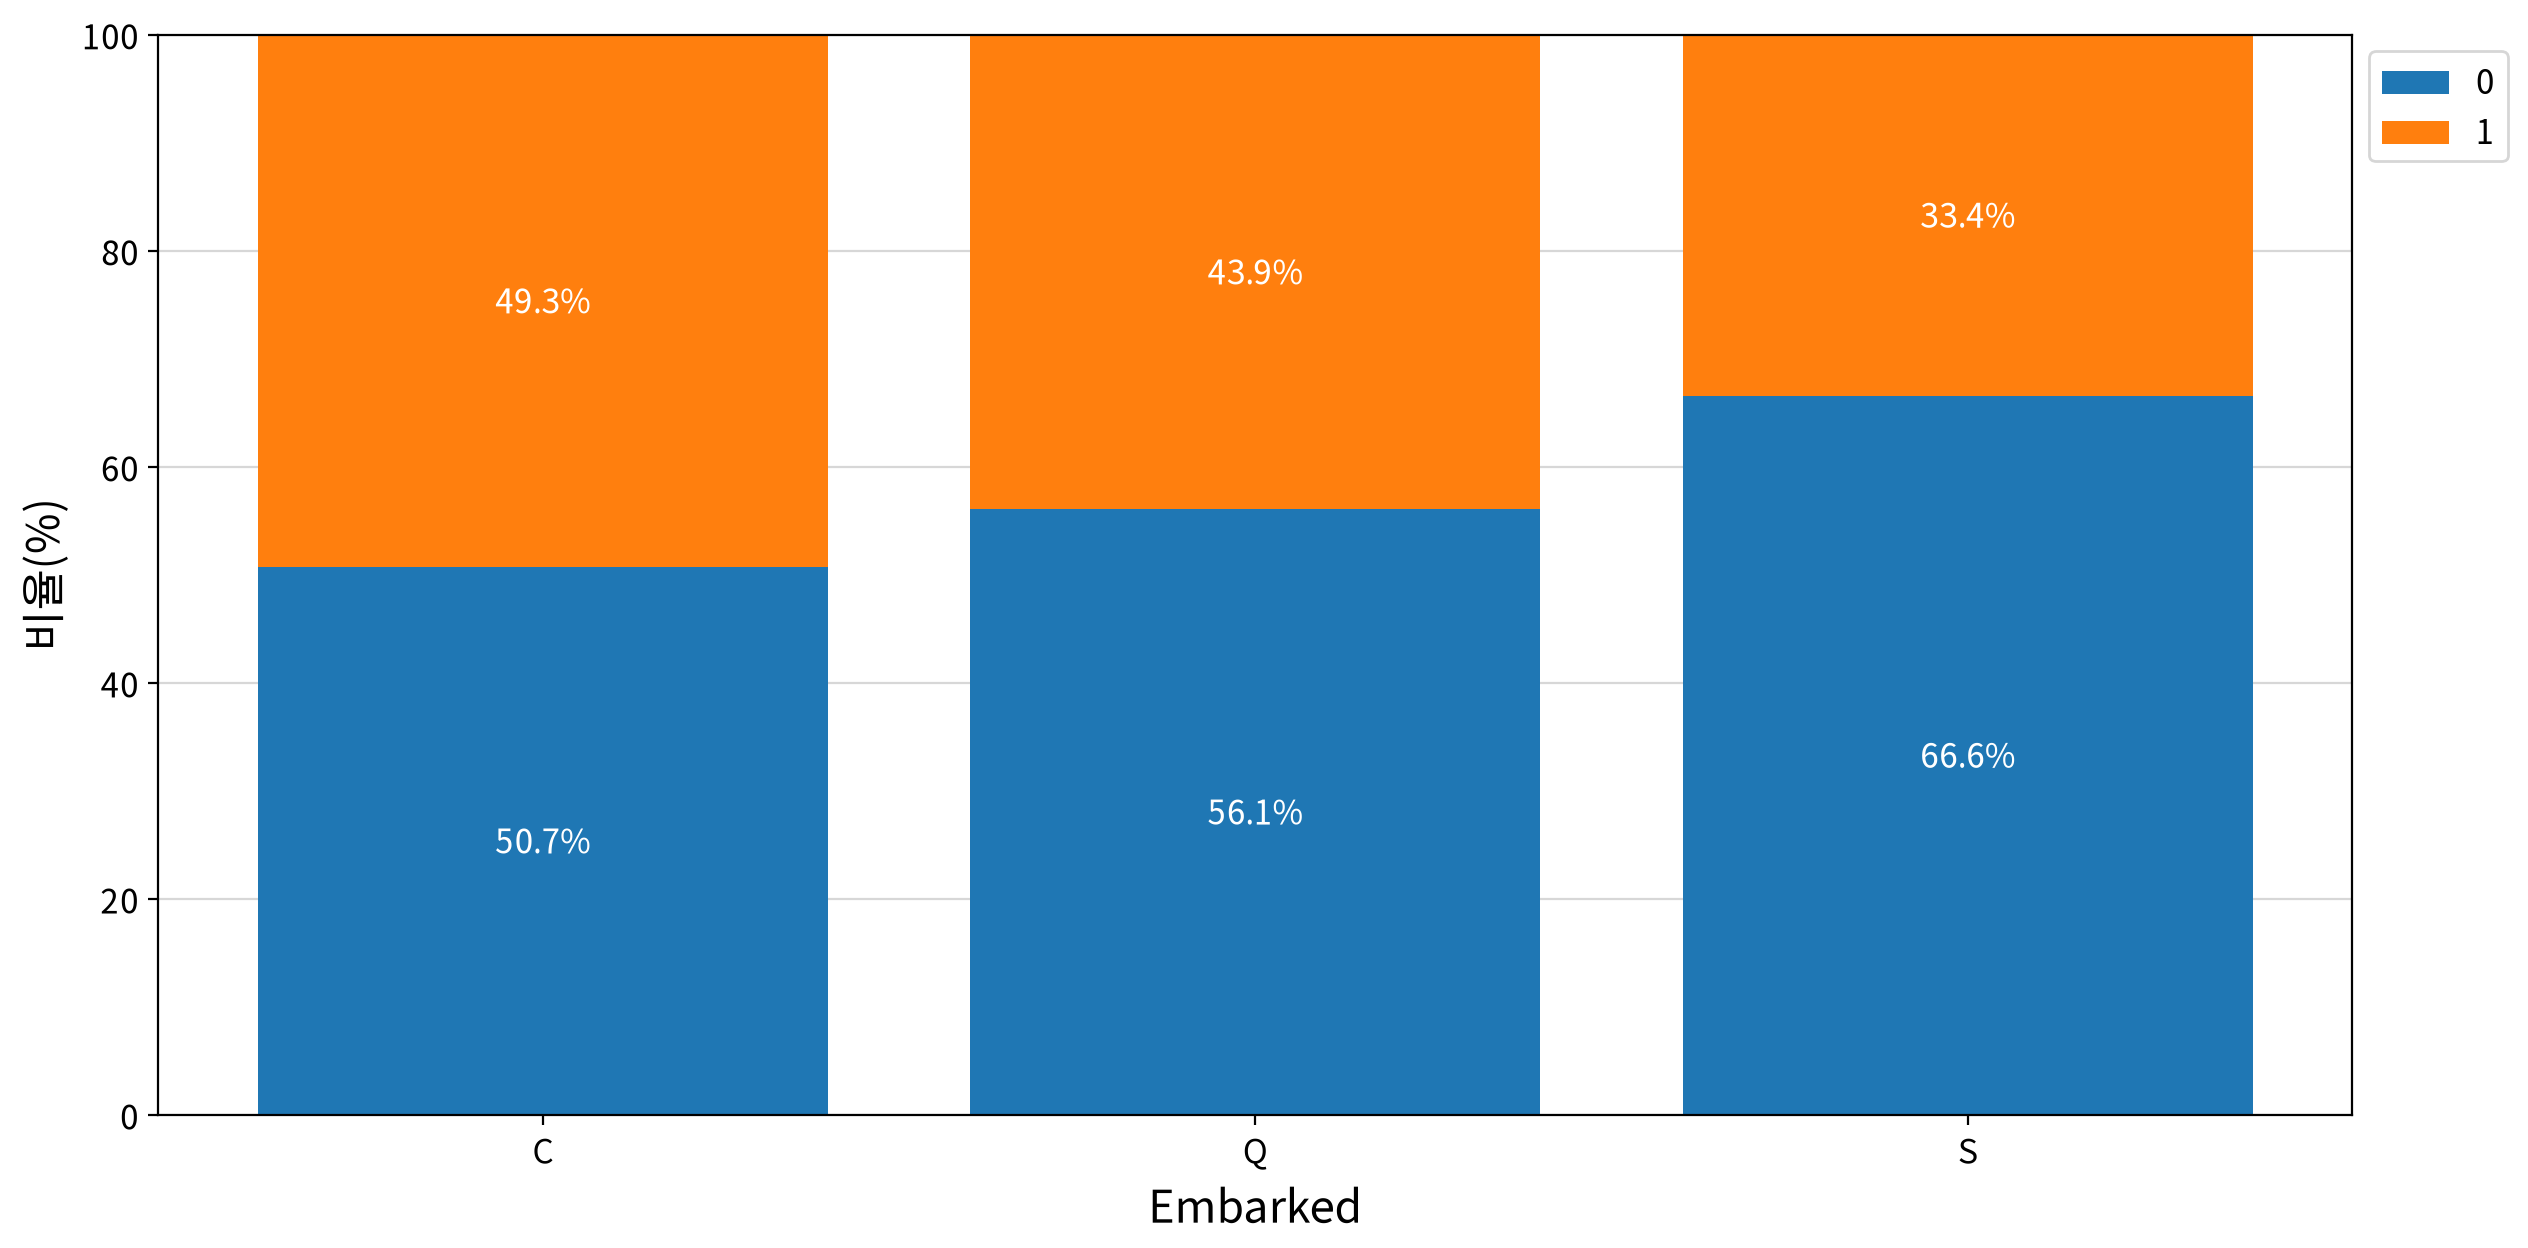

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Embarked,Survived,Chi-square test of independence,24.548,2,0.000,True,0.137,Weak,46.340,True


#### ▶︎ Title(이름에서 추출한 호칭 (Mr/Mrs/Miss/Master/Officer)) → Survived

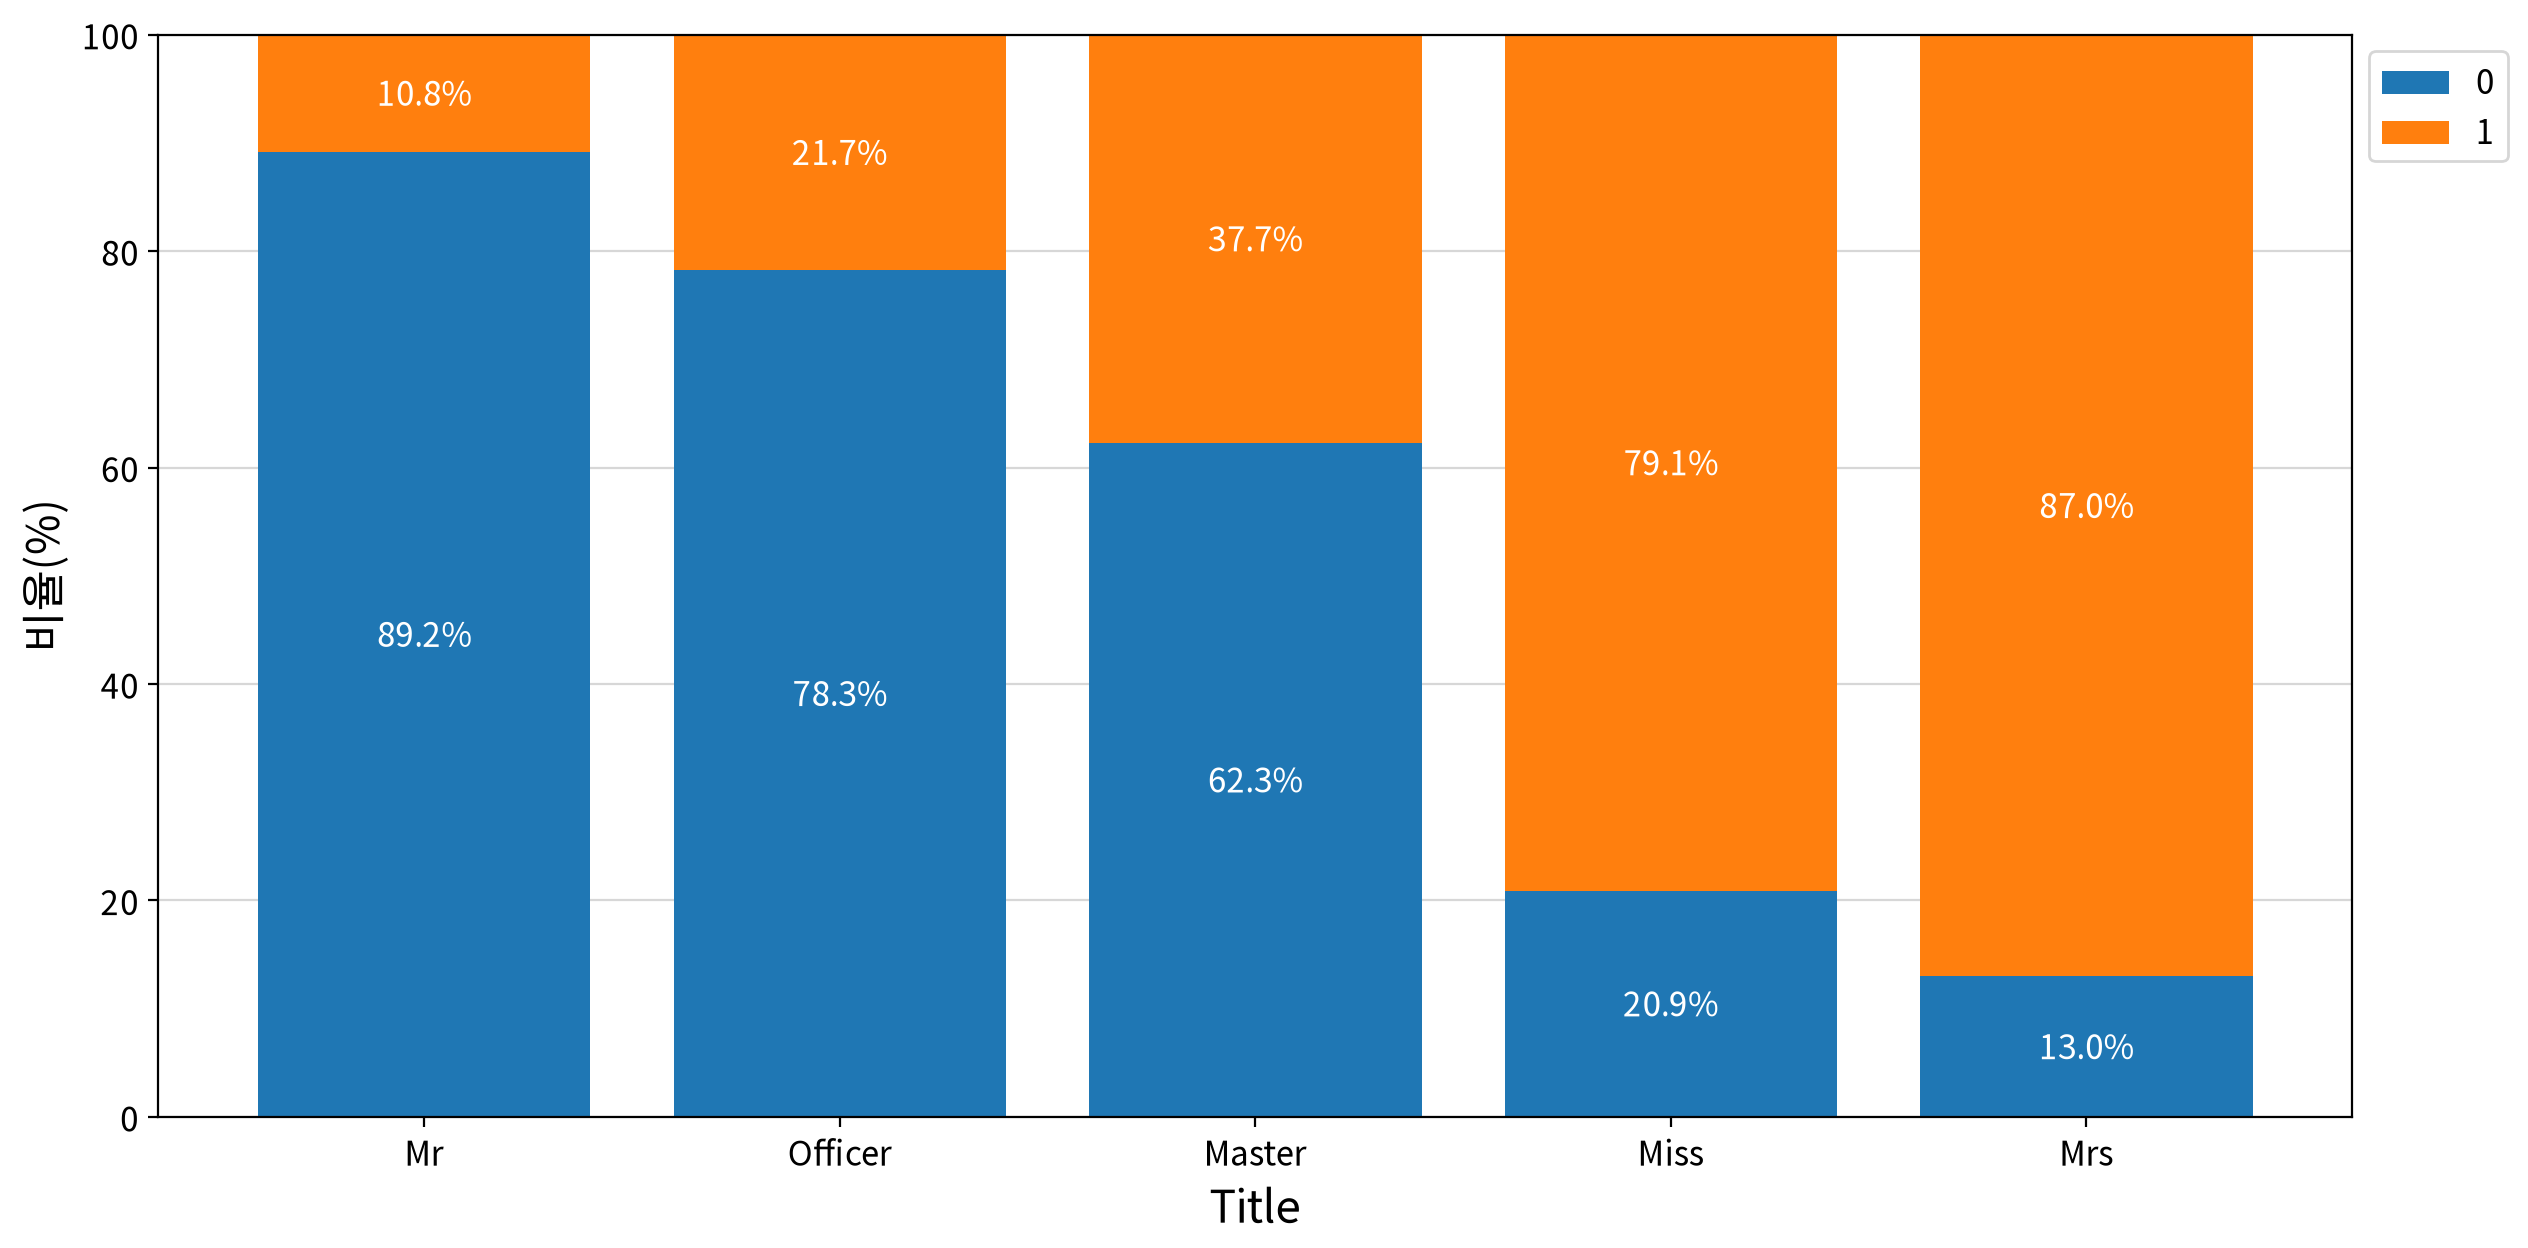

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Title,Survived,Chi-square test of independence,635.224,4,0.000,True,0.697,Strong,8.660,True


In [22]:
for n in nominal_cols:
    print()
    display(Markdown(f"#### ▶︎ {n}({column_means[n]}) → {target}"))
    display(my_stats.chi2_independence(df, x=n, y=target))

---

##### 💡 인사이트

- 판정 기준 : **유의(p < 0.05) + Cramér's V ≥ 0.1**(효과가 무시할 수준이 아님) → ✅ 채택

| 판정 | 변수 | χ² | 유의확률 | Cramér's V | 효과 크기 | 범주별 생존율 |
|---|---|---|---|---|---|---|
| ✅ 채택 | **`Title`** | **635.22** | < 0.001 | **0.697** | **Strong** | Mrs 87.0% · Miss 79.1% · **Master 37.7%** · Officer 21.7% · Mr 10.8% |
| ✅ 채택 | `Sex` | 614.17 | < 0.001 | 0.686 | Strong | 여성 82.5% · 남성 12.9% |
| ✅ 채택 | `Pclass` | 89.73 | < 0.001 | 0.262 | Weak | 1등급 57.3% · 2등급 42.2% · 3등급 27.0% |
| ✅ 채택 | `Embarked` | 24.55 | < 0.001 | 0.137 | Weak | C 49.3% · Q 43.9% · S 33.4% |

- **4개 모두 채택**이다. 생존과의 관계가 유의하고, 효과 크기도 모두 무시할 수준(0.1)을 넘는다.
- **`Title`이 `Sex`보다 생존을 더 잘 설명한다**(V 0.697 > 0.686).
- 차이가 나는 자리는 **`Master`(남자아이) 37.7%** 다. `Sex`는 이 61명을 성인 남성과 같은 `male`(12.9%)로 묶었지만, `Title`은 따로 떼어 **약 3배 높은 생존율**을 보여 준다. **'여성과 아이 먼저'의 '아이' 부분이 여기서 드러난다.**
- `Mrs`(87.0%)와 `Miss`(79.1%)도 갈린다. 성별로는 둘 다 82.5%의 `female`이었다.
- 객실 등급은 1등급에서 3등급으로 갈수록 생존율이 **단조 감소**한다.
- 효과 크기가 Weak인 `Pclass` · `Embarked`도 버리지 않는다. 다른 변수를 통제했을 때의 효과는 모델에서 판정한다.
- ⚠️ `Title`과 `Sex`는 같은 정보를 담고 있을 가능성이 크다(남자아이를 빼면 성별과 호칭이 거의 일치). 둘 중 무엇을 쓸지는 다변량 분석에서 정한다.

---

## 2-3. 다변량 분석 — 독립변수끼리 같은 정보를 담고 있는가?

- 2-2 이변량 분석은 **독립변수 → 생존**의 관계를 봤다. 여기서는 **독립변수끼리**의 관계를 보고, 같은 정보를 담은 변수(공선성)를 찾는다.
- 연속형끼리는 상관분석 · VIF, 명목형끼리는 교차분석을 쓴다.

### (1) 연속형 독립변수끼리 : 상관분석 · VIF

- 파생변수 `FamilySize`는 `SibSp` · `Parch`를 더해 만든 변수라 **원재료와 겹칠 수밖에 없다.**

In [ ]:
corr = my_stats.multi_correlation(df, columns=continuous_cols, plot=False)
display(my_stats.correlation_summary(corr))
display(my_stats.compute_vif(df, columns=continuous_cols))

,Age,SibSp,Parch,Fare,FamilySize
Age,1.000,-0.101,-0.181,0.171,-0.133
SibSp,-0.101,1.000,0.438,0.448,0.848
Parch,-0.181,0.438,1.000,0.402,0.796
Fare,0.171,0.448,0.402,1.000,0.524
FamilySize,-0.133,0.848,0.796,0.524,1.000


,max-y,max-coef,count,columns
x,,,,
FamilySize,SibSp,0.848,2,"SibSp, Parch"
SibSp,FamilySize,0.848,1,FamilySize
Parch,FamilySize,0.796,1,FamilySize
Fare,FamilySize,0.524,0,-
Age,Parch,-0.181,0,-


,VIF
FamilySize,1000799917193443.500
Parch,1000799917193443.500
SibSp,1000799917193443.500
Fare,1.119
Age,1.098


### (2) 명목형 독립변수끼리 : `Title` ↔ `Sex`

- 호칭은 성별 정보를 포함한다(Mr · Master는 남성, Miss · Mrs는 여성). 두 독립변수가 얼마나 겹치는지 교차분석으로 본다.

In [24]:
display(my_stats.chi2_independence(df, x="Title", y="Sex", plot=False))
crosstab(df["Title"], df["Sex"])   # 교차표 생성

,,test,chi2,dof,p-value,significant,effect(V),strength,min_expected,assumption
row,col,,,,,,,,,
Title,Sex,Chi-square test of independence,1301.824,4,0.000,True,0.998,Strong,8.170,True


Sex,female,male
Title,,
Mr,0,759
Officer,1,22
Master,0,61
Miss,263,0
Mrs,200,0


---
##### 💡 인사이트

- **`FamilySize` · `SibSp` · `Parch`는 완전히 겹친다.** `FamilySize = SibSp + Parch + 1`이라 VIF가 사실상 무한대다. 셋을 함께 넣으면 계수를 추정할 수 없다.
- **`Title`과 `Sex`도 거의 같은 정보다**(Cramér's V = 0.998). `Mr` · `Master`는 전원 남성, `Miss` · `Mrs`는 전원 여성이고, 예외는 여성 `Officer` 1명뿐이다.
- `Age` · `Fare`는 다른 변수와 겹치지 않는다(VIF 1.10 · 1.12).

---

## 2-4. 최종 변수 선택

| 판정 | 변수 | 검정방법 | 유의확률 | 방향 | 공선성 신호 | 근거 |
|---|---|---|---|---|---|---|
| ✅ 채택 | `Title` | 교차분석 | < 0.001 | Mrs > Miss > Master > Officer > Mr | `Sex`와 V = 0.998 | V = 0.697 (**Strong**) — 가장 높음. 성별에 더해 아이 · 기혼/미혼 여성까지 구분 |
| ✅ 채택 | `Pclass` | 교차분석 | < 0.001 | 1등급 > 3등급 | 없음 | 등급 순서대로 단조 감소 |
| ✅ 채택 | `Embarked` | 교차분석 | < 0.001 | C > S | 없음 | 유의하나 `Pclass`와 겹칠 가능성 → 모델에서 재확인 |
| ✅ 채택 | `Fare` | Mann-Whitney U | < 0.001 | 생존 > 사망 | 없음 (VIF 1.12) | 집단 차이 유의 |
| ✅ 채택 | `FamilySize` | Mann-Whitney U | < 0.001 | 생존 > 사망 (∩자) | `SibSp` · `Parch`와 완전 공선성 | 두 변수를 합친 대표 |
| 🟡 보류 | `Age` | Mann-Whitney U | 0.267 | — | 없음 (VIF 1.10) | 단독 차이는 없으나 억제효과 가능성 → 모델에서 판정 |
| ❌ 제외 | `Sex` | 교차분석 | < 0.001 | 여성 > 남성 | `Title`과 V = 0.998 | `Title`에 포함된 정보 |
| ❌ 제외 | `SibSp` · `Parch` | Mann-Whitney U | < 0.001 | 생존 > 사망 | `FamilySize`와 완전 공선성 (VIF = ∞) | `FamilySize`로 대표 |
| ❌ 제외 | `PassengerId` · `Name` · `Ticket` | — | — | — | — | 식별자 · 텍스트 (PART 1에서 제거) |
| ❌ 제외 | `Cabin` | — | — | — | — | 결측 77.5% (PART 1에서 제거) |

- **`Sex` 대신 `Title`, `SibSp` · `Parch` 대신 `FamilySize`를 쓴다.** 두 경우 모두 '비슷한' 변수가 아니라 **사실상 같은 정보**라, 함께 넣으면 계수를 안정적으로 추정할 수 없다(`FamilySize`는 아예 계산 불가).
- 상관이 강한 정도의 중복은 모델의 VIF · 후진소거에 맡기지만, 이렇게 **수식이나 정의로 겹치는 변수**는 EDA에서 대표 하나만 남긴다.

---
# PART 3. 기준선 모형과 가정 검정

## 3-1. 기준선 모형

### (1) 모델 데이터 준비 

- 종속변수 라벨링

    - 2-4에서 정한 대로 `Sex` · `SibSp` · `Parch`를 뺀다.
    - 종속변수는 **0 / 1 정수**로 라벨링한다. → 이 모형이 예측하는 것은 **P(Survived = 1) = 생존 확률**이다.

In [25]:
df_model = df.drop(columns=["Sex", "SibSp", "Parch"])
df_model = my_prep.labeling(df=df_model, columns=[target])
df_model.head()

Survived (2종): 0=0, 1=1


,Survived,Pclass,Age,Fare,Embarked,FamilySize,Title
0,0,3,22.000,7.250,S,2,Mr
1,1,1,38.000,71.283,C,2,Mrs
2,1,3,26.000,7.925,S,1,Miss
3,1,1,35.000,53.100,S,2,Mrs
4,0,3,35.000,8.050,S,1,Mr


- 더미변수

    - 명목형 변수(`Pclass` · `Embarked` · `Title`)는 **더미변수**(범주별 0 / 1)로 바꿔 넣는다. 숫자(1, 2, 3)로 그대로 넣으면 범주 사이에 **순서와 같은 간격**이 있다고 가정하게 되기 때문이다.
    - `Pclass`는 순서는 있지만 등급 간 간격이 같다는 보장이 없어, 역시 더미로 바꿔 등급마다 효과를 따로 추정한다.
    - 기준 범주는 각각 **3등급 · C(Cherbourg) · Mr**이다. 계수는 모두 이 기준 범주와 비교한 값으로 읽는다.

In [26]:
df_dummy = my_prep.dummies(df=df_model, columns=["Pclass", "Embarked", "Title"])
df_dummy.head()

Pclass (3종) -> 2개: Pclass_2, Pclass_1 (기준: 3 제외)
Embarked (3종) -> 2개: Embarked_Q, Embarked_S (기준: C 제외)
Title (5종) -> 4개: Title_Officer, Title_Master, Title_Miss, Title_Mrs (기준: Mr 제외)

컬럼 수: 7개 -> 12개


,Survived,Age,Fare,FamilySize,Pclass_2,Pclass_1,Embarked_Q,Embarked_S,Title_Officer,Title_Master,Title_Miss,Title_Mrs
0,0,22.000,7.250,2,0,0,0,1,0,0,0,0
1,1,38.000,71.283,2,0,1,0,0,0,0,0,1
2,1,26.000,7.925,1,0,0,0,1,0,0,1,0
3,1,35.000,53.100,2,0,1,0,1,0,0,0,1
4,0,35.000,8.050,1,0,0,0,1,0,0,0,0


### (2) 기준선 모형 적합

In [27]:
fit = my_logit.fit_model(data=df_dummy, y=target)
my_logit.report_variables(fit=fit, data=df_dummy)

,종속변수,독립변수,B,β,표준오차,z,유의확률,B 95% 하한,B 95% 상한,오즈비(OR),OR 95% 하한,OR 95% 상한,공차,VIF
0,Survived,Title_Mrs,4.624,1.666,0.292,15.861,0.000,4.053,5.195,101.889,57.542,180.413,0.830,1.205
1,Survived,Title_Miss,3.895,1.563,0.244,15.995,0.000,3.418,4.372,49.160,30.502,79.232,0.766,1.306
2,Survived,Title_Master,2.494,0.526,0.396,6.292,0.000,1.717,3.271,12.109,5.569,26.333,0.709,1.410
3,Survived,Pclass_1,1.947,0.839,0.286,6.799,0.000,1.386,2.508,7.007,3.997,12.281,0.467,2.139
4,Survived,Pclass_2,0.879,0.360,0.232,3.782,0.000,0.424,1.335,2.409,1.527,3.800,0.829,1.207
5,Survived,Title_Officer,0.400,0.053,0.547,0.731,0.465,-0.673,1.472,1.491,0.510,4.357,0.945,1.058
6,Survived,FamilySize,-0.333,-0.527,0.065,-5.104,0.000,-0.461,-0.205,0.717,0.631,0.815,0.721,1.388
7,Survived,Embarked_Q,0.196,0.057,0.356,0.550,0.583,-0.502,0.893,1.216,0.605,2.443,0.641,1.561
8,Survived,Embarked_S,-0.156,-0.071,0.225,-0.691,0.489,-0.597,0.286,0.856,0.550,1.331,0.662,1.511
9,Survived,Age,-0.022,-0.282,0.008,-2.613,0.009,-0.038,-0.005,0.978,0.962,0.995,0.639,1.565


---
##### 💡 인사이트 — 기준선 모형

| 변수 | 단독 비교 (EDA) | 기준선 모형 (다른 변수 통제) |
|---|---|---|
| `Title` (Mrs · Miss · Master) | 유의 | ✅ 모두 유의 (p < 0.001) |
| `Pclass` (1 · 2등급) | 유의 | ✅ 모두 유의 (p < 0.001) |
| `FamilySize` | 유의 | ✅ 유의 (B = −0.333, p < 0.001) |
| **`Age`** | **유의하지 않음 (p = 0.267)** | ✅ **유의 (B = −0.022, p = 0.009)** |
| `Fare` | 유의 | ❌ 유의하지 않음 (p = 0.226) |
| `Embarked` (S · Q) | 유의 | ❌ 유의하지 않음 (p = 0.489 · 0.583) |
| `Title_Officer` | — | ❌ 유의하지 않음 (p = 0.465) |

- **단독으로는 무관했던 `Age`가 유의해졌다.** 호칭으로 아이(Master)를 따로 통제하자, 같은 호칭 안에서는 **나이가 많을수록 생존에 불리하다**는 효과가 드러났다.
- 반대로 **`Fare`와 `Embarked`는 유의하지 않게 됐다.** 다른 변수와 함께 넣자 효과가 사라졌는데, 요금 · 항구가 담고 있던 정보가 **객실 등급과 겹쳤을 가능성**이 있다.
- **`FamilySize`는 음수**로 나왔다. 가족이 많을수록 불리하다는 뜻인데, EDA의 ∩자(4명까지는 유리)와 맞지 않는다. 직선 하나로 표현하면서 대가족의 강한 불리함이 전체 기울기를 끌어내린 것이다.

---

## 3-2. 가정 검정

### (1) 로짓 선형성 검정 (Box-Tidwell)

- 연속형 변수 x에 `x × ln(x)` 보조항을 넣었을 때 **그 항이 유의하면(p < 0.05) 직선이 아니다.**

In [38]:
my_logit.test_linear(fit=fit, data=df_dummy)

,z,p-value,linearity,위치이동,result
독립변수,,,,,
Age,0.923,0.356,True,False,귀무가설 채택 → 로짓 선형성 위배 근거 없음
Fare,-0.008,0.994,True,True,귀무가설 채택 → 로짓 선형성 위배 근거 없음
FamilySize,0.032,0.974,True,False,귀무가설 채택 → 로짓 선형성 위배 근거 없음


---
##### 💡 인사이트

- 세 변수 모두 **로짓 선형성 위배 근거가 없다**(p ≥ 0.05). 그래서 제곱항 · 로그 같은 처방은 하지 않는다.
- 그런데 `FamilySize`는 EDA에서 분명한 **∩자**(4명까지 상승, 5명부터 급락)를 보였다. Box-Tidwell은 `x × ln(x)` 형태의 완만한 휘어짐을 잡는 검정이라, **특정 지점에서 꺾이는 모양은 잘 잡지 못할 수 있다.**
- → 통계 검정만으로 판단하지 않고, PART 4에서 **도메인 지식으로 가족 규모를 집단화**한 모델과 비교한다.

---

### (2) 독립성 검정 — Durbin-Watson

In [39]:
my_logit.test_independent(fit)

,statistic,independence,result
Durbin-Watson,1.973,True,독립성 만족


---
##### 💡 인사이트

- DW = **1.973**으로 기준 범위(1.5 ~ 2.5) 안에 있다. → **독립성 만족.**
- 1,306명은 서로 다른 승객이고 행 순서에 의미가 없으므로, 자료 수집 설계로 봐도 독립이 타당하다.

---

# PART 4. 로지스틱 회귀 모델링

### (1) 도메인 파생변수 — 가족 규모를 세 집단으로 (`FamilyGroup`)

- EDA에서 생존율은 **1명 → 2~4명에서 오르고, 5명 이상에서 급락**했다. 그런데 직선을 가정한 기준선 모형과 로짓 선형성 검정은 이 모양을 잡지 못했다.
- 그래서 가족 규모를 **단독(1명) · 소가족(2~4명) · 대가족(5명 이상)** 세 집단으로 나눈 명목형 변수로 바꾼다. 범주형이면 집단마다 효과를 따로 추정하므로, 곡선 모양을 가정 없이 담을 수 있다.

In [40]:
df_domain = df_model.drop(columns=["FamilySize"])
df_domain["FamilyGroup"] = cut(df_model["FamilySize"], 
                               bins=[0, 1, 4, 20], labels=["Alone", "Small", "Large"])

df_domain.groupby("FamilyGroup", observed=True)[target].agg(생존율="mean", 인원수="size").T

FamilyGroup,Alone,Small,Large
생존율,0.291,0.561,0.220
인원수,787.000,437.000,82.000


### (2) 전처리 체크포인트 정의

- PART 3의 로짓 선형성 검정에서 위배된 변수가 없어 **처방(`recipe`)이 필요 없다.** 그래서 '가정 반영' 계열 대신, EDA에서 본 가족 규모의 ∩자를 담은 **도메인 파생변수(`FamilyGroup`)** 계열과 비교한다.
- **0~3번은 원본 `FamilySize`(연속형)**, **4~7번은 `FamilyGroup`(도메인 파생변수)** 을 쓴 조합이다. 두 계열의 전처리를 똑같이 맞춰 **파생변수의 순수한 효과**를 본다.
- **공선성 제거(`vif=True`)는 모든 체크포인트에 공통으로 건다.**

In [41]:
# 원본 FamilySize 데이터(df_model)에 적용할 체크포인트
checkpoints = {
    "0_기준선":     dict(vif=True),
    "1_후진소거":   dict(backward=True, vif=True),
    "2_이상치대체": dict(backward=True, outlier=True, vif=True),
    "3_정규화":     dict(backward=True, outlier=True, vif=True, scale=True),
}

# 도메인 파생변수 데이터(df_domain)에 적용할 체크포인트
domain_checkpoints = {
    "4_도메인":           dict(vif=True),
    "5_도메인+후진소거":   dict(backward=True, vif=True),
    "6_도메인+이상치대체": dict(backward=True, outlier=True, vif=True),
    "7_도메인+정규화":     dict(backward=True, outlier=True, vif=True, scale=True),
}

### (3) 체크포인트별 모델 적합

- 이상치 대체는 `Age` · `Fare`에만 적용한다. 카운트 변수(`FamilySize`)에 IQR 대체를 쓰면 4명 이상이 전부 눌려 버린다.

In [42]:
fits = {}        # 적합된 모델을 누적할 딕셔너리

# 원본 FamilySize 데이터
for name in checkpoints:
    print(f"\n▶︎ --- {name} ---")
    fits[name] = my_logit.fit_pipeline(data=df_model, y=target, columns=["Age", "Fare"],
                                       name=name, **checkpoints[name])

# 도메인 파생변수 데이터 (fits 에 이어서 담는다)
for name in domain_checkpoints:
    print(f"\n▶︎ --- {name} ---")
    fits[name] = my_logit.fit_pipeline(data=df_domain, y=target, columns=["Age", "Fare"],
                                       name=name, **domain_checkpoints[name])

print("\n누적된 모델 :", len(fits), "개")


▶︎ --- 0_기준선 ---

완료! 남은 변수: ['Age', 'Embarked_Q', 'Embarked_S', 'FamilySize', 'Fare', 'Pclass_1', 'Pclass_2', 'Title_Master', 'Title_Miss', 'Title_Mrs', 'Title_Officer']
최대 VIF = 2.14


▶︎ --- 1_후진소거 ---

완료! 남은 변수: ['Age', 'Embarked_Q', 'Embarked_S', 'FamilySize', 'Fare', 'Pclass_1', 'Pclass_2', 'Title_Master', 'Title_Miss', 'Title_Mrs', 'Title_Officer']
최대 VIF = 2.14

유의하지 않은 독립변수 제거 → Embarked_Q (p = 0.5826)
유의하지 않은 독립변수 제거 → Title_Officer (p = 0.4609)
유의하지 않은 독립변수 제거 → Fare (p = 0.2507)
유의하지 않은 독립변수 제거 → Embarked_S (p = 0.1726)

▶︎ --- 2_이상치대체 ---

완료! 남은 변수: ['Age', 'Embarked_Q', 'Embarked_S', 'FamilySize', 'Fare', 'Pclass_1', 'Pclass_2', 'Title_Master', 'Title_Miss', 'Title_Mrs', 'Title_Officer']
최대 VIF = 3.94

유의하지 않은 독립변수 제거 → Embarked_Q (p = 0.5507)
유의하지 않은 독립변수 제거 → Title_Officer (p = 0.4163)
유의하지 않은 독립변수 제거 → Embarked_S (p = 0.2736)

▶︎ --- 3_정규화 ---

완료! 남은 변수: ['Age', 'Embarked_Q', 'Embarked_S', 'FamilySize', 'Fare', 'Pclass_1', 'Pclass_2', 'Title_Master', 'Title_Miss', 

### (4) 모델 성능 비교

- AUC 1순위 모델과 차이가 5% 이내인 모델 중 **변수가 적은 모델**을 우선한다.

In [43]:
best = my_logit.compare_models(fits)
print("간명성 기준 1순위 :", best.name_)

,변수 수,정확도,정밀도,재현율,F1,AUC,Pseudo R²,AIC,Gap(%)
모델,,,,,,,,,
6_도메인+이상치대체,7,0.872,0.865,0.782,0.822,0.904,0.476,923.279,0.390
7_도메인+정규화,7,0.872,0.865,0.782,0.822,0.904,0.476,923.279,0.390
5_도메인+후진소거,7,0.872,0.865,0.782,0.822,0.904,0.476,923.331,0.390
1_후진소거,7,0.868,0.851,0.787,0.817,0.903,0.466,940.001,0.440
2_이상치대체,8,0.867,0.849,0.787,0.817,0.906,0.468,937.820,0.160
3_정규화,8,0.867,0.849,0.787,0.817,0.906,0.468,937.820,0.160
0_기준선,11,0.870,0.852,0.793,0.821,0.904,0.468,943.999,0.350
4_도메인,12,0.873,0.864,0.787,0.823,0.907,0.479,927.270,0.000


간명성 기준 1순위 : 6_도메인+이상치대체


---
##### 💡 인사이트 — 가족을 '집단'으로 보자 모델이 나아졌다

| 계열 | 대표 모델 | 변수 수 | AUC | 정확도 | Pseudo R² | AIC |
|---|---|---|---|---|---|---|
| 원본 `FamilySize` (0~3번) | 1_후진소거 | 7 | 0.903 | 0.868 | 0.466 | 940.00 |
| **도메인 `FamilyGroup` (4~7번)** | **5_도메인+후진소거** | **7** | **0.904** | **0.872** | **0.476** | **923.33** |

- 같은 변수 7개인데, 가족 규모를 세 집단으로 바꾸자 **AIC가 940.00 → 923.33으로 낮아지고**, Pseudo R²도 0.466 → 0.476으로 올랐다.
- AUC · 정확도는 거의 같다. 예측력보다 **모형의 설명력(적합도)** 이 좋아진 것이다.
- 이상치 대체 · 정규화는 성능을 거의 바꾸지 못했다(AUC 차이 0.003 이하).

---

### (5) 최종 모델 선택

- `compare_models()`는 **`6_도메인+이상치대체`** 를 1순위로 골랐다. 그런데 `5` · `6` · `7`번은 남은 변수(7개)와 성능이 **사실상 같다**(AUC 0.904, 정확도 0.872, AIC 923.3).
- 세 모델의 차이는 **전처리 단계뿐**이다.
  - `6`번의 이상치 대체 : 성능을 바꾸지 못한 채 실제 나이 · 요금 값만 바꿨다.
  - `7`번의 정규화 : 나이를 '살' 단위가 아닌 다른 단위로 바꿔 버린다. 그러면 **"나이가 1살 많으면 생존 확률이 몇 % 줄어든다"** 처럼 바로 와닿는 해석을 할 수 없다. (예를 들면 “1살 많으면 생존 오즈 1.7% 감소”)
- 그래서 같은 성능이면 **불필요한 전처리가 없는 `5_도메인+후진소거`** 를 최종 채택한다.
  - → **간명성은 변수 수만이 아니라 전처리 단계에도 적용된다.**

In [47]:
# 성능이 같다면 불필요한 전처리가 없는 5번을 최종 채택한다
final_name = "5_도메인+후진소거"

final_fit = fits[final_name]
final_data = final_fit.data_[["Survived"] + list(final_fit.model.exog_names[1:])]   # 상수항을 제외하여 최종 모델에 남은 변수만 출력

print("최종 모델 :", final_name)
print("독립변수  :", int(final_fit.df_model), "개")

최종 모델 : 5_도메인+후진소거
독립변수  : 7 개


---
# PART 5. 최종 모델 보고

### (1) 모형 적합도 · 계수 해석

#### ▶ 모형 적합도

 **Note. n = 1306. LL = -453.665, LL-Null = -865.143, LLR χ²(7) = 822.955, p < 0.001, Pseudo R² = 0.476**

Survived를 종속변수로, Age, Pclass_2, Pclass_1, Title_Master, Title_Miss, Title_Mrs, FamilyGroup_Large(을)를 독립변수로 한 이항 로지스틱 회귀분석 결과, 모형은 통계적으로 유의하였다.

> LLR χ²(7) = 822.955, p < 0.001, Pseudo R² = 0.476.

즉, 모형의 유사결정계수는 0.476로 매우 우수한 적합 수준을 보였다.

> ※ Pseudo R²는 선형회귀의 R²처럼 '분산 설명 비율'로 해석하지 않는다. 일반적으로 **0.2~0.4** 구간이면 매우 우수한 적합으로 본다.

#### ▶ 독립변수 보고

,종속변수,독립변수,B,β,표준오차,z,유의확률,B 95% 하한,B 95% 상한,오즈비(OR),OR 95% 하한,OR 95% 상한,공차,VIF
0,Survived,Title_Mrs,4.420,1.592,0.280,15.801,0.000,3.872,4.969,83.120,48.038,143.822,0.898,1.114
1,Survived,Title_Miss,3.949,1.584,0.235,16.828,0.000,3.489,4.409,51.875,32.751,82.167,0.832,1.202
2,Survived,Title_Master,2.337,0.493,0.387,6.030,0.000,1.577,3.096,10.346,4.841,22.111,0.746,1.341
3,Survived,FamilyGroup_Large,-2.236,-0.543,0.337,-6.639,0.000,-2.896,-1.576,0.107,0.055,0.207,0.869,1.151
4,Survived,Pclass_1,2.012,0.866,0.235,8.543,0.000,1.550,2.473,7.476,4.712,11.860,0.748,1.338
5,Survived,Pclass_2,0.717,0.293,0.232,3.095,0.002,0.263,1.171,2.049,1.301,3.227,0.871,1.149
6,Survived,Age,-0.017,-0.224,0.008,-2.121,0.034,-0.034,-0.001,0.983,0.967,0.999,0.661,1.512


- **Age**의 회귀계수는 **B = -0.0175**, 오즈비는 **OR = 0.9827** (95% CI [0.9670, 0.9987])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = -2.12**, **p = .034**). 즉, **Age** 가 1 증가할 때 Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **1.7% 감소**하는 것으로 해석된다.
- **Pclass_2**의 회귀계수는 **B = 0.7173**, 오즈비는 **OR = 2.0488** (95% CI [1.3010, 3.2266])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = 3.10**, **p = .002**). 즉, **Pclass_2** 에 해당하는 경우(기준 범주 대비) Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **104.9% 증가**하는 것으로 해석된다.
- **Pclass_1**의 회귀계수는 **B = 2.0117**, 오즈비는 **OR = 7.4757** (95% CI [4.7122, 11.8600])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = 8.54**, **p < .001**). 즉, **Pclass_1** 에 해당하는 경우(기준 범주 대비) Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **647.6% 증가**하는 것으로 해석된다.
- **Title_Master**의 회귀계수는 **B = 2.3366**, 오즈비는 **OR = 10.3461** (95% CI [4.8411, 22.1112])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = 6.03**, **p < .001**). 즉, **Title_Master** 에 해당하는 경우(기준 범주 대비) Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **934.6% 증가**하는 것으로 해석된다.
- **Title_Miss**의 회귀계수는 **B = 3.9488**, 오즈비는 **OR = 51.8751** (95% CI [32.7508, 82.1667])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = 16.83**, **p < .001**). 즉, **Title_Miss** 에 해당하는 경우(기준 범주 대비) Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **5087.5% 증가**하는 것으로 해석된다.
- **Title_Mrs**의 회귀계수는 **B = 4.4203**, 오즈비는 **OR = 83.1201** (95% CI [48.0382, 143.8221])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = 15.80**, **p < .001**). 즉, **Title_Mrs** 에 해당하는 경우(기준 범주 대비) Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **8212.0% 증가**하는 것으로 해석된다.
- **FamilyGroup_Large**의 회귀계수는 **B = -2.2357**, 오즈비는 **OR = 0.1069** (95% CI [0.0553, 0.2069])로 나타났으며, 신뢰구간이 1을 포함하지 않아 **Survived**에 유의한 요인임을 의미한다 (**z = -6.64**, **p < .001**). 즉, **FamilyGroup_Large** 에 해당하는 경우(기준 범주 대비) Survived가 1(사건 발생)이 될 오즈는 평균적으로 약 **89.3% 감소**하는 것으로 해석된다.

> ※ 오즈비(OR)가 1보다 크면 사건 발생 오즈가 증가, 1보다 작으면 감소함을 뜻한다. 유의확률이 유의수준보다 큰(=유의하지 않은) 변수는 효과가 통계적으로 확인되지 않았으므로 오즈비 해석에 주의한다. 오즈비의 신뢰구간이 1을 포함하지 않으면 해당 유의수준에서 유의하며, 이는 p값 판정과 일치한다. 더미변수의 오즈비는 '기준(drop_first로 제외된) 범주' 대비 값이다.

### ▶ 오즈비 시각화

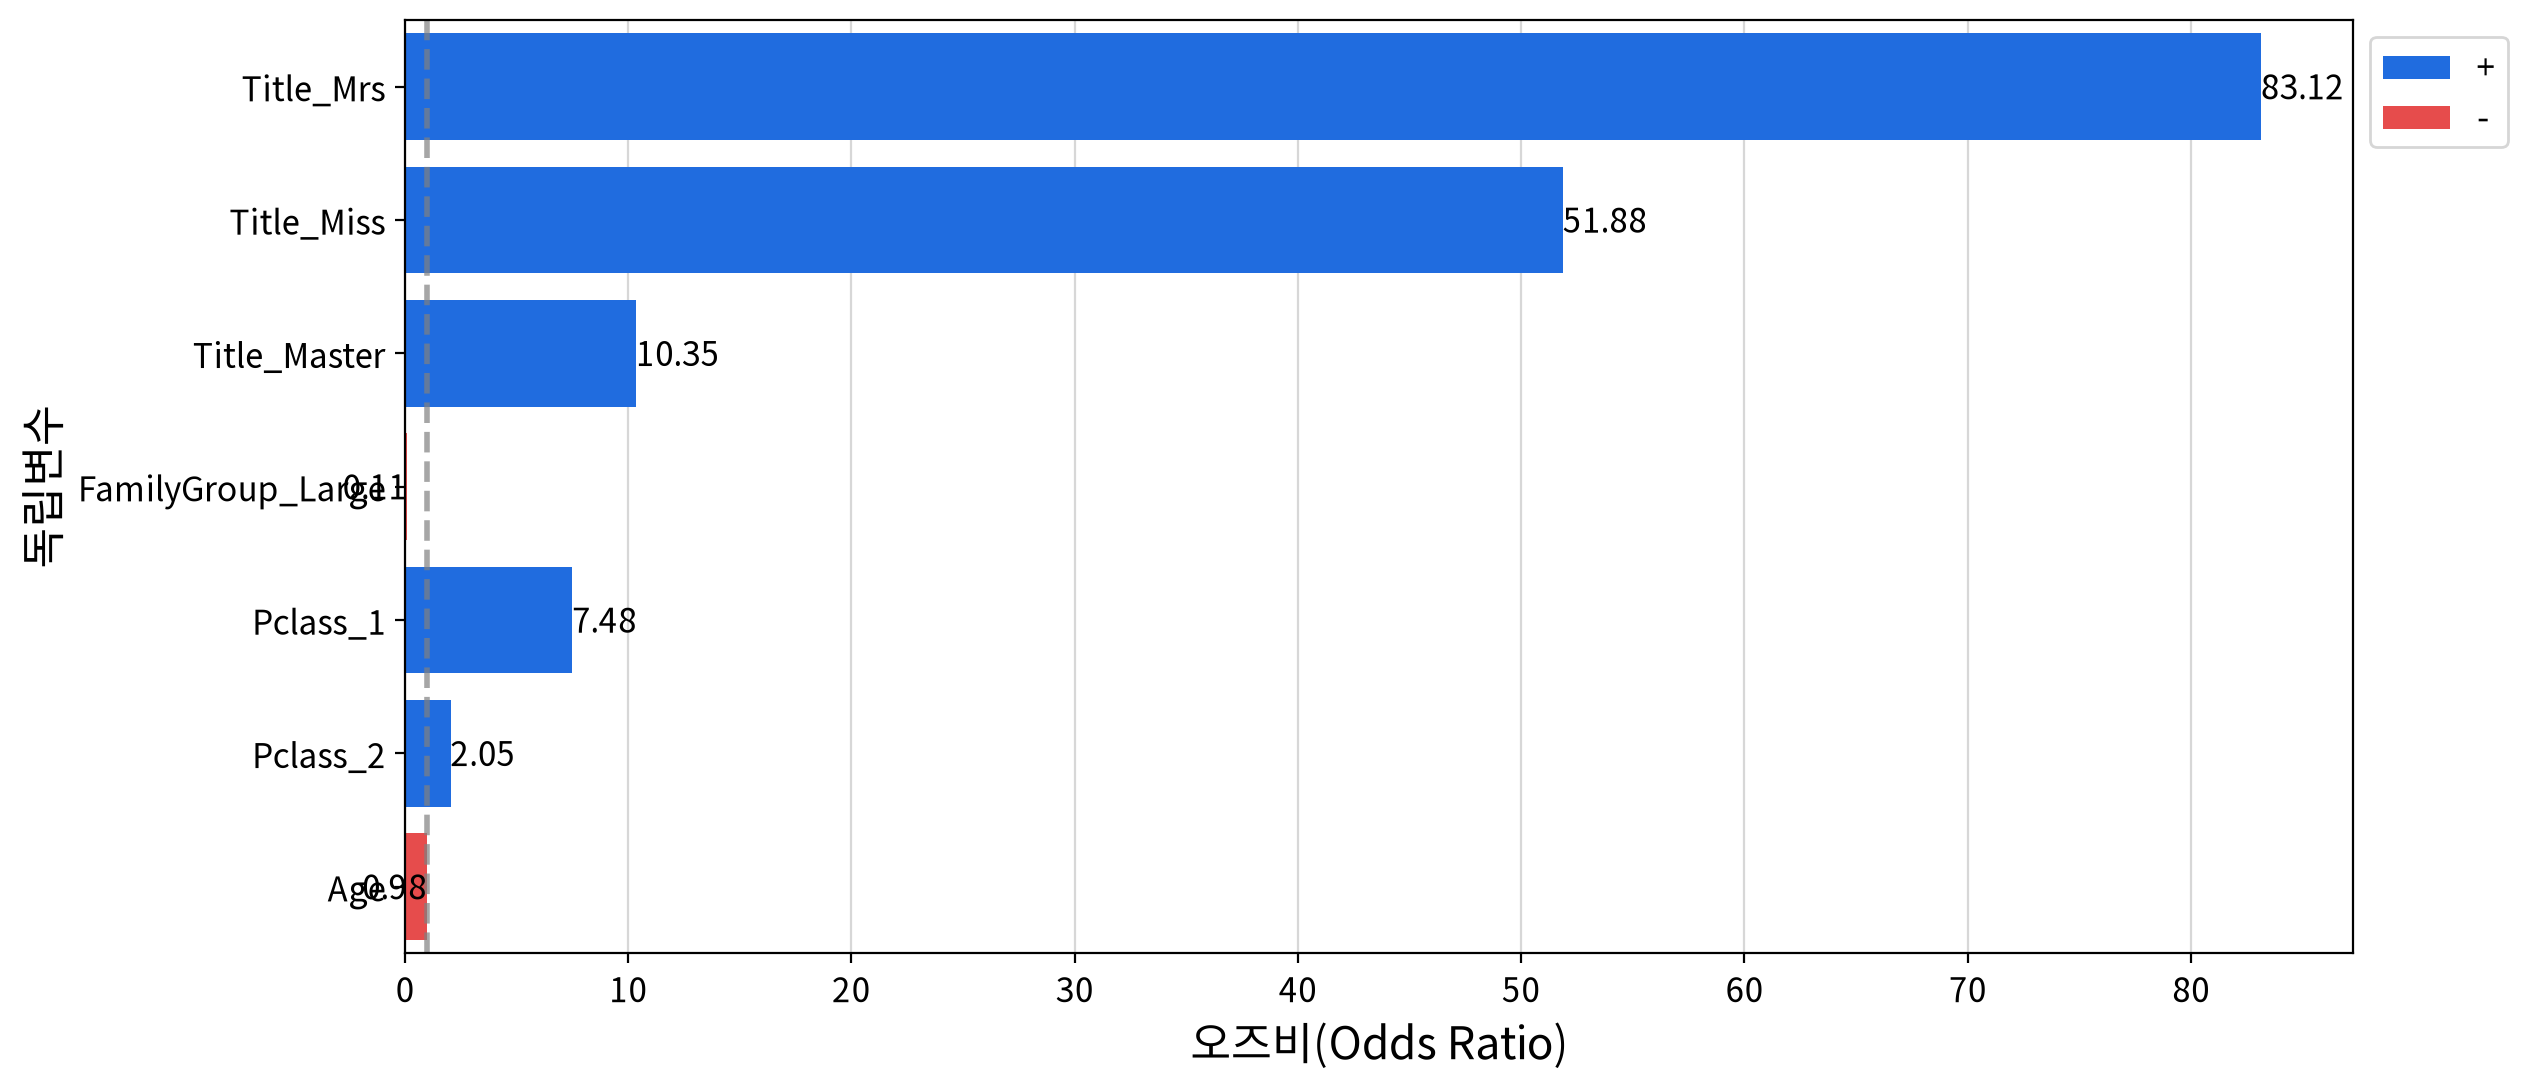

In [45]:
my_logit.auto_logit(data=final_data, y=target)

> ※ **오즈비(OR)의 크기로 변수의 영향력을 비교하면 안 된다.** 변수마다 값의 범위가 달라서, 영향력은 **표준화 계수(β)** 로 비교한다.

---
##### 💡 인사이트 — 최종 모델

**① 적합도**
- **LLR χ²(7) = 822.96, p < .001, Pseudo R² = 0.476** — 로지스틱 회귀에서 0.2~0.4면 매우 좋은 적합으로 보는데, 그보다도 높다.
   - 즉, 독립변수 7개를 넣은 모델이 아무것도 넣지 않은 모델보다 유의하게 낫다.
- **7개 항이 모두 유의**하다(p ≤ 0.034).

<br>

**② 영향력 순위 (표준화 계수 β)**

| 순위 | 변수 | β | 의미 |
|---|---|---|---|
| 1 | `Title_Mrs` | 1.592 | 기혼 여성은 성인 남성보다 생존에 유리 |
| 2 | `Title_Miss` | 1.584 | 미혼 여성은 성인 남성보다 생존에 유리 |
| 3 | `Pclass_1` | 0.866 | 1등급은 3등급보다 생존에 유리 |
| 4 | `FamilyGroup_Large` | −0.543 | 대가족은 단독 · 소가족보다 생존에 불리 |
| 5 | `Title_Master` | 0.493 | 남자아이는 성인 남성보다 생존에 유리 |

- **여성 → 1등급 → 대가족(불리) → 남자아이** 순으로 생존을 갈랐다.
- 남자아이는 β 순위로는 5위지만, 오즈비는 **약 10배**로 1등급(약 7.5배)보다 크다(아래 ③ 참고). 남자아이가 61명(4.7%)뿐이라, **한 사람에게 주는 효과는 크지만 전체 승객 사이의 영향력(β)은 작게** 나타난 것이다.
- 즉 '여성과 아이 먼저'는 데이터에서 **여성 쪽이 훨씬 강하게** 드러난다.

<br>

**③ 오즈비로 해석** (기준 범주 : 성인 남성 `Mr` · `Officer` / 3등급 / 단독 · 소가족)

| 변수 | 오즈비 | 해석 |
|---|---|---|
| `Title_Mrs` | 83.1 | 기혼 여성의 생존 오즈는 성인 남성의 **약 83배** |
| `Title_Miss` | 51.9 | 미혼 여성의 생존 오즈는 성인 남성의 **약 52배** |
| `Title_Master` | 10.3 | 남자아이의 생존 오즈는 성인 남성의 **약 10배** |
| `Pclass_1` | 7.48 | 1등급의 생존 오즈는 3등급의 **약 7.5배** |
| `Pclass_2` | 2.05 | 2등급의 생존 오즈는 3등급의 **약 2배** |
| `FamilyGroup_Large` | 0.107 | 대가족(5명 이상)의 생존 오즈는 **약 89% 낮다** |
| `Age` | 0.983 | 나이 1살 ↑ → 생존 오즈 **1.7% 감소** (10살 ↑ → 약 16% 감소) |

- `Title_Officer`와 `FamilyGroup_Small`은 후진소거로 빠져서, 각각 성인 남성(`Mr`)과 단독 승객과 **같은 기준 범주**로 묶였다.

<br>

**④ EDA와 무엇이 달라졌나**

| 변수 | EDA (단독 비교) | 최종 모델 (다른 변수 통제) |
|---|---|---|
| `Age` | 차이 없음 (p = 0.267) | ✅ 유의 (나이가 많을수록 불리) |
| `Fare` | 유의 | ❌ 후진소거 제거 (p = 0.168, 객실 등급에 흡수) |
| `Embarked` (S · Q) | 유의 | ❌ 후진소거 제거 (p = 0.748 · 0.251, 객실 등급에 흡수된 것으로 보임) |
| `Title_Officer` | 성인 남성보다 생존율 높음 (21.7% vs 10.8%) | ❌ 후진소거 제거 (p = 0.515, 성인 남성과 차이 없음) |
| `FamilyGroup_Small` | 단독보다 생존율 높음 (56.1% vs 29.1%) | ❌ 후진소거 제거 (p = 0.132, 단독과 차이 없음) |
| `FamilyGroup_Large` | 단독보다 생존율 낮음 (22.0% vs 29.1%) | ✅ 유지 (생존에 뚜렷하게 불리) |

- **나이** : 단독으로 볼 때는 생존과 관계가 없어 보였지만, 다른 변수(호칭 · 객실 등급 등)와 함께 모델에 넣자 **나이가 많을수록 생존에 불리하다**는 효과가 나타났다.
- **요금 · 항구 · Officer · 소가족** : 단독으로 볼 때는 생존과 관계가 있어 보였지만, 다른 변수와 함께 넣자 **효과가 사라졌다.** 이 변수들이 담고 있던 정보가 다른 변수와 겹쳤을 가능성이 있다.
- 끝까지 남은 것은 **호칭 · 객실 등급 · 대가족 · 나이**이고, 그중 **대가족(5명 이상)이 생존에 불리하다**는 것이 가족 규모에서 남은 결과다.

---

### (2) 분류 성능 평가

,예측 0 (Negative),예측 1 (Positive)
실제 0 (Negative),754,60
실제 1 (Positive),107,385


,정확도(Accuracy),정밀도(Precision),"재현율(Recall,TPR)","위양성율(Fallout,FPR)","특이성(Specificity,TNR)",F1,AUC,AUC 판단,진단오즈비(DOR)
performance,0.872,0.865,0.783,0.074,0.926,0.822,0.904,판별력 매우 우수,45.217


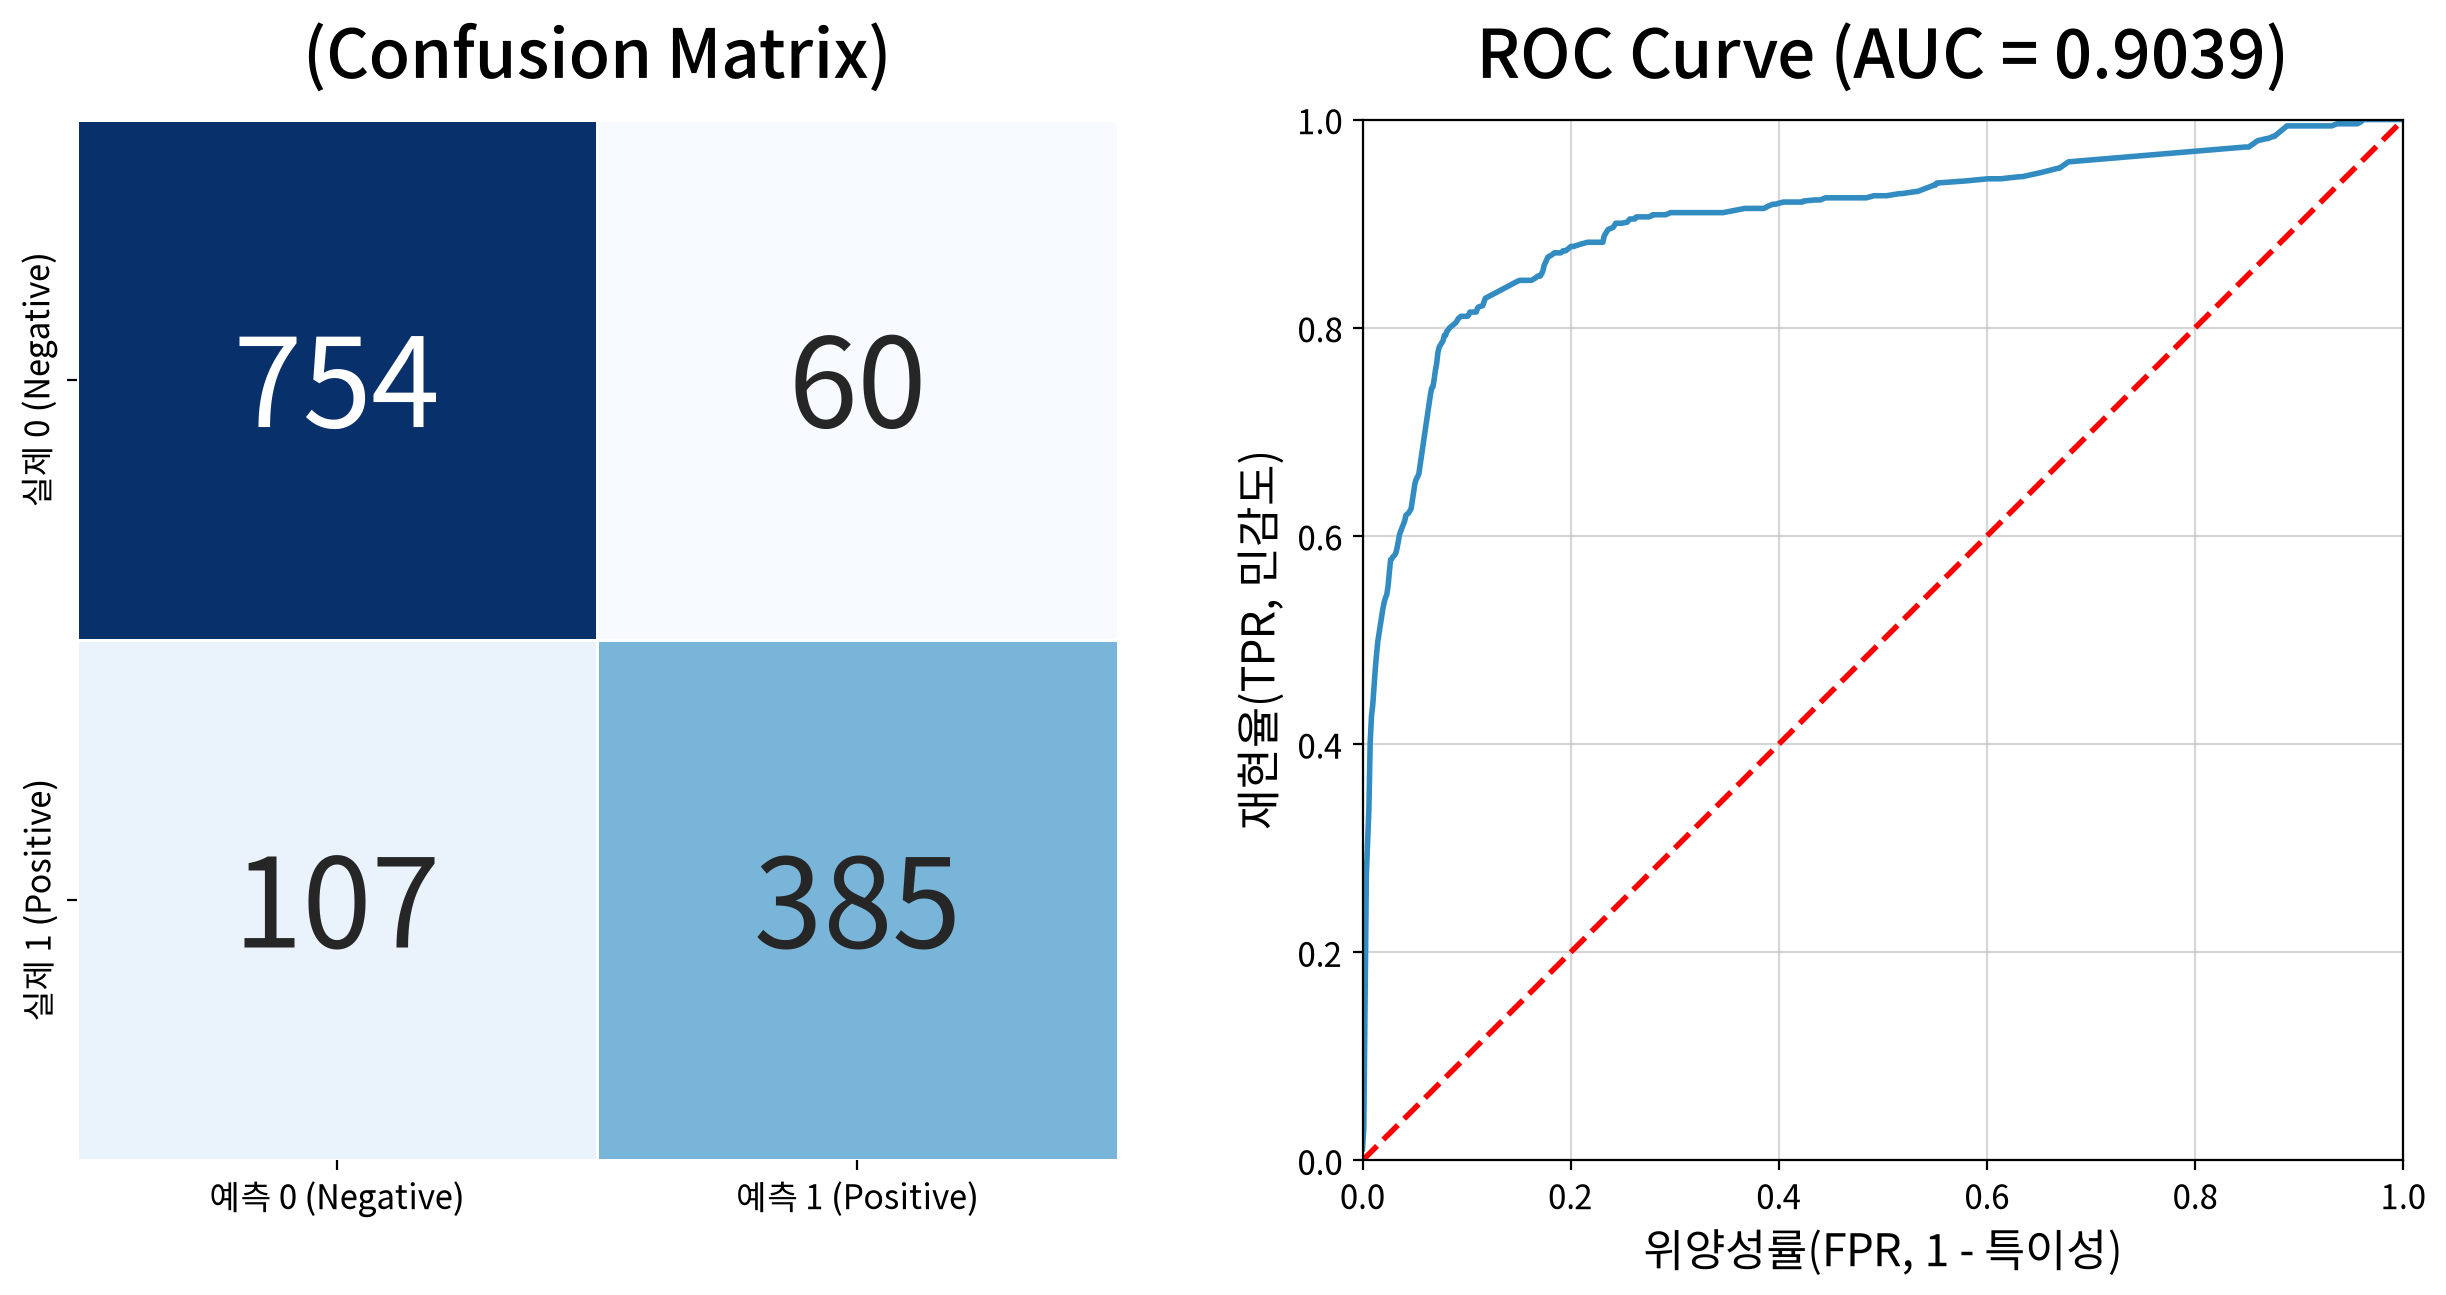

In [48]:
my_logit.report_performance(final_fit)

---
##### 💡 인사이트

| 지표 | 값 | 의미 |
|---|---|---|
| 정확도 | 0.872 | 1,306명 중 1,139명을 맞혔다. 게으른 모델의 바닥값(62.3%)보다 **24.9%p 높다** |
| 정밀도 | 0.865 | 생존으로 판정한 사람 중 86.5%가 실제 생존자 |
| 재현율 | 0.783 | 실제 생존자 492명 중 385명(78.3%)을 찾아냈다 |
| 위양성률 | 0.074 | 사망자의 7.4%를 생존으로 잘못 판정했다 (= 1 − 특이성) |
| 특이성 | 0.926 | 사망자의 92.6%를 사망으로 맞혔다 |
| F1 | 0.822 | 정밀도와 재현율을 합친 점수. 재현율이 낮아 정확도보다 조금 낮다 |
| AUC | 0.904 | 생존자 한 명과 사망자 한 명을 무작위로 뽑았을 때, 모델이 생존자 쪽에 더 높은 확률을 줄 가능성 **90.4% (매우 우수)** |
| 진단 오즈비 | 45.22 | 생존으로 판정한 사람이 실제 생존자일 오즈가, 사망으로 판정한 사람의 **약 45배** |

- **특이성(0.926)이 재현율(0.783)보다 높다.** 사망자가 더 많은 데이터라 모델이 '사망' 쪽으로 판정하는 경향이 있고, 그 결과 **생존자 107명을 사망으로 판정**했다.

---

### (3) 임계값 조정

- 임계값 0.5는 관례일 뿐 정답이 아니다. `FN`은 실제 생존자인데 사망으로 판정한 경우, `FP`는 실제 사망자인데 생존으로 판정한 경우다.

In [49]:
my_logit.report_threshold(final_fit)

,정확도,정밀도,재현율,F1,FN (놓침 : 실제1→예측0),FP (헛짚음 : 실제0→예측1)
임계값,,,,,,
0.300,0.845,0.766,0.846,0.804,76,127
0.400,0.873,0.853,0.801,0.826,98,68
0.500,0.872,0.865,0.783,0.822,107,60
0.600,0.871,0.865,0.780,0.821,108,60
0.700,0.866,0.868,0.760,0.810,118,57


---
##### 💡 인사이트 — 임계값 0.4가 가장 균형 잡혀 있다

| 임계값 | 정확도 | 정밀도 | 재현율 | F1 | 놓친 생존자 (FN) | 잘못 판정한 사망자 (FP) |
|---|---|---|---|---|---|---|
| 0.3 | 0.845 | 0.766 | **0.846** | 0.804 | **76명** | 127명 |
| 0.4 | **0.873** | 0.853 | 0.801 | **0.826** | 98명 | 68명 |
| 0.5 (기본) | 0.872 | 0.865 | 0.783 | 0.822 | 107명 | 60명 |
| 0.6 | 0.871 | 0.865 | 0.780 | 0.821 | 108명 | 60명 |
| 0.7 | 0.866 | **0.868** | 0.760 | 0.810 | 118명 | **57명** |

- **정확도와 F1이 모두 임계값 0.4에서 최대**다(0.873 · 0.826). 기본값 0.5보다 놓친 생존자가 107명 → 98명으로 줄고, 잘못 판정한 사망자는 60명 → 68명으로 조금 늘 뿐이다.
- 0.5 이상에서는 정밀도가 거의 오르지 않는다(0.865 → 0.868). 임계값을 높여도 **얻는 것은 적고 놓치는 생존자만 늘어난다.**
- **정답은 목적이 정한다.**
  - **생존 가능성이 있는 사람을 빠짐없이 찾아야 할 때** → 임계값 **0.3** : 재현율 0.846
  - **전체적으로 가장 잘 맞히고 싶을 때** → 임계값 **0.4** : 정확도 · F1 최대

---

# 📌 종합 인사이트

### 1. 생존을 가른 것은 '여성과 아이' → 객실 등급 → 대가족
- 표준화 계수 β 기준 **기혼 여성(1.592) · 미혼 여성(1.584) > 1등급(0.866) > 대가족(−0.543) > 남자아이(0.493)** 순이다.
- 기혼 여성의 생존 오즈는 성인 남성의 약 83배, 1등급은 3등급의 약 7.5배였고, 대가족은 약 89% 낮았다.

### 2. 호칭(Title)이 성별보다 많은 것을 말했다
- 성별로는 남자아이가 성인 남성(생존율 12.9%)과 같은 집단이었지만, 호칭으로 떼어 보니 **37.7%** 였다.
- 호칭으로 아이를 통제하자, EDA에서 무관했던 **나이의 효과**(1살 ↑ → 생존 오즈 1.7% ↓)도 드러났다.

### 3. 통계 검정이 놓친 모양을 도메인 지식으로 담았다
- 가족 규모는 4명까지 생존율이 오르다 5명부터 급락했지만, 로짓 선형성 검정은 위배를 잡지 못했다.
- 단독 · 소가족 · 대가족으로 나눈 **`FamilyGroup`** 을 쓰자, 같은 변수 7개로 AIC가 940.00 → 923.33으로 낮아졌다.

### 4. 요금 · 항구의 효과는 객실 등급이었다
- 단독으로는 유의했던 `Fare` · `Embarked`가 다른 변수와 함께 넣자 사라졌다. 요금 · 항구의 정보가 **객실 등급과 겹쳤을 가능성**이 있다.

### 5. 자동 선택은 전처리의 의미를 모른다
- `compare_models()`는 이상치 대체까지 한 모델을 골랐지만, 성능이 같다면 **불필요한 전처리는 빼는 게 맞다.** 전처리가 없는 `5_도메인+후진소거`를 최종 채택했다.

### ⚠️ 한계
- **`Age` 결측 263명(20.1%)을 전체 중앙값(28세)으로 채웠다.** 28세 자리에 인공적인 봉우리가 생겼고, 나이를 모르는 남자아이 8명도 28세로 채워졌다. 호칭별 중앙값 등으로 채우면 더 정확할 수 있다.
- **`Cabin`(선실 정보)을 버렸다.** 77.5%가 비어 있었지만, 기록 여부 자체가 객실 위치 · 등급과 관련된 정보였을 수 있다.
- **`Officer`(23명) 등 작은 범주의 추정은 불안정하다.**
- **성능을 학습 데이터에서 측정했다(in-sample).** train/test 분할이나 교차검증으로 확인해야 한다.
- **인과관계가 아니라 연관관계다.**

### ✅ 최종 모델
| 항목 | 값 |
|---|---|
| 모델 | `5_도메인+후진소거` |
| 형태 | `logit(P(생존))` ~ `Title`(Master · Miss · Mrs) + `Pclass`(1 · 2등급) + `FamilyGroup_Large` + `Age` |
| 성능 (임계값 0.5) | 정확도 0.872 · AUC 0.904 · 재현율 0.783 · Pseudo R² 0.476 |
| 권장 임계값 | 0.4 → 정확도 0.873 · F1 0.826 |
| 가장 큰 영향 | `Title_Mrs` (β = 1.592) |